In [1]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [2]:
!kaggle datasets download -d brendanartley/lumbar-coordinate-pretraining-dataset
!unzip -qq "/content/lumbar-coordinate-pretraining-dataset.zip"

Dataset URL: https://www.kaggle.com/datasets/brendanartley/lumbar-coordinate-pretraining-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
 99% 712M/717M [00:07<00:00, 70.5MB/s]
100% 717M/717M [00:07<00:00, 98.1MB/s]


In [3]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT
!pip install -q pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 866.2/866.2 kB 1.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/53.8 kB ? eta -:--:--Requirement already satisfied: nvidia-nvjitlink-cu12 in /usr/local/lib/python3.10/dist-packages (from nvidia-cusolver-cu12==11.4.5.107->torch->torch-ema) (12.6.20)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.1/309.1 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 5.5 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects

In [4]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
sys.path.append('/content/CoaT')
from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers
from PIL import Image, ImageFilter

/content/CoaT/src/models/coat.py:589: UserWarning: Overwriting coat_tiny in registry with CoaT.src.models.coat.coat_tiny. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  def coat_tiny(**kwargs):
/content/CoaT/src/models/coat.py:595: UserWarning: Overwriting coat_mini in registry with CoaT.src.models.coat.coat_mini. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  def coat_mini(**kwargs):
/content/CoaT/src/models/coat.py:601: UserWarning: Overwriting coat_small in registry with CoaT.src.models.coat.coat_small. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  def coat_small(**kwargs):
/content/CoaT/src/models/coat.py:608: UserWarning: Overwriting coat_lite_tiny in registry with CoaT.src.models.coat.coat_lite_tiny. This is because the name being registered conflicts with an existing name. Plea

In [5]:
SEED = 1101
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [6]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    #kind: 'detect'
    kind: 'classify'
    #kind: 'depth'
    #condition: 'nfn'
    condition: 'scs'
    #condition: 'ss'
    #condition: 'all'
    #direction: 'sagt1'
    direction: 'ax'
    #direction: 'sagt1'
    position:
        - 'L1/L2'
        - 'L2/L3'
        - 'L3/L4'
        - 'L4/L5'
        - 'L5/S1'

in_chans: 3

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 25
    min_epochs: 25
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        lr: 0.0001
        #lr: 0.001
        weight_decay: 0.0001
    scheduler:
        name: "CosineAnnealingLR"
        #name: "ReduceLROnPlateau"
        #name: "cosine_with_warmup"
        #name: "ChrisLR"
        params:
            CosineAnnealingLR:
                T_max: 25
                eta_min: 5.0e-5
                last_epoch: -1
            ReduceLROnPlateau:
                mode: "min"
                factor: 0.5
                patience: 2
                min_lr: 0.00001
                verbose: True
            ChrisLR:
                freeze_iter: 2
            cosine_with_warmup:
                num_training_steps: 25
                num_warmup_steps: 2
                num_cycles: 0.5
                last_epoch: -1


Overwriting config.yaml


In [7]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [8]:
coor = pd.read_csv('/content/coords_pretrain.csv')
coor.head(3)

,filename,source,x,y,level,relative_x,relative_y
0,1_t2.jpg,spider,139,175,L5/S1,0.542969,0.683594
1,1_t2.jpg,spider,133,157,L4/L5,0.519531,0.613281
2,1_t2.jpg,spider,132,131,L3/L4,0.515625,0.511719


In [9]:
coor.groupby(['filename']).count()['x'].describe()


,x
count,1121.0
mean,5.0
std,0.0
min,5.0
25%,5.0
50%,5.0
75%,5.0
max,5.0


(256, 256)

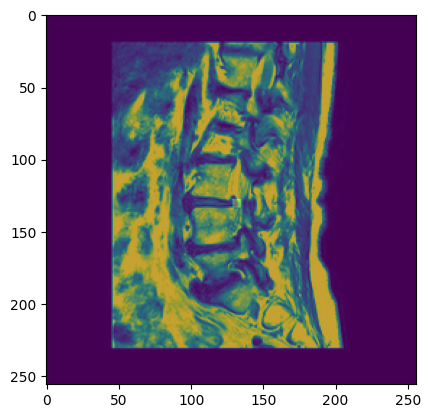

In [10]:
source='spider'
name='1_t2.jpg'
path = f'/content/data/processed_{source}_jpgs/{name}'
img = np.array(Image.open(path))
plt.imshow(img)
x = 0.515625
y = 0.511719
y = img.shape[0]*y
x = img.shape[1]*x
mask = np.zeros(img.shape)
mask[int(y-3):int(y+3), int(x-3):int(x+3)] = 1
plt.imshow(mask, alpha=0.3)
img.shape

In [11]:
class CoorDetectDataset(Dataset):
    def __init__(self, coor):
        self.coor = coor
        self.path = []
        for _, row in self.coor.iterrows():
            self.path.append(f'/content/data/processed_{row.source}_jpgs/{row.filename}')
        self.resize = v2.Resize((256, 256))

    def __getitem__(self, index):
        path = self.path[index]
        img = np.array(Image.open(path))
        img = img.astype(np.float32)
        img = (img - img.min()) / (img.max() - img.min())
        img = self.resize(torch.from_numpy(img)[None, ...])
        img = img.repeat(3, 1, 1)
        filename = path.split('/')[-1]
        sub_coor = self.coor.loc[self.coor.filename==filename]
        coor_dict = {}
        for _, row in sub_coor.iterrows():
            coor_dict[row.level] = torch.tensor([row.relative_x, row.relative_y])
        return img, coor_dict, path

    def __len__(self):
        return len(self.path)

In [12]:
dataset = CoorDetectDataset(coor)
dataset[0][2]

'/content/data/processed_spider_jpgs/1_t2.jpg'

In [13]:
class ConvNextSCSDetect(nn.Module):
    def __init__(self):
        super().__init__()
        #self.size = 256
        self.encoder = timm.create_model('tf_efficientnetv2_l.in21k_ft_in1k', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    )

        self.l1 = nn.Linear(self.in_features, 2)
        self.l2 = nn.Linear(self.in_features, 2)
        self.l3 = nn.Linear(self.in_features, 2)
        self.l4 = nn.Linear(self.in_features, 2)
        self.l5 = nn.Linear(self.in_features, 2)
        #self.out = nn.Linear(self.in_features, 10)
    def forward(self, x, label=None):
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1.sigmoid(), 'L2/L3': l2.sigmoid(), 'L3/L4': l3.sigmoid(), 'L4/L5': l4.sigmoid(), 'L5/S1': l5.sigmoid()}


In [14]:
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5

class SCSDetectRelativePositionLoss(nn.Module):
    def __init__(self):
        super(SCSDetectRelativePositionLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        loss/5
        relative_positional_loss = 0
        for l in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            relative_positional_pred_list = []
            relative_positional_tar_list = []
            for ll in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
                if l == ll:
                    continue
                pred1, pred2 = outputs[l], outputs[ll]
                tar1, tar2 = targets[l], targets[ll]
                dist_pred = torch.sqrt((pred1[:, 0]-pred2[:, 0])**2 + (pred1[:, 1]-pred2[:, 1])**2)
                dist_tar = torch.sqrt((tar1[:, 0]-tar2[:, 0])**2 + (tar1[:, 1]-tar2[:, 1])**2)
                relative_positional_pred_list.append(dist_pred)
                relative_positional_tar_list.append(dist_tar)
            relative_positional_pred = torch.cat(relative_positional_pred_list)
            relative_positional_tar = torch.cat(relative_positional_tar_list)
            relative_positional_loss += nn.functional.mse_loss(relative_positional_pred, relative_positional_tar)
        return loss/5 + relative_positional_loss/5

In [15]:
class DetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.model = ConvNextSCSDetect()
        #self.model = SwinSCSDetect()
        #self.loss_module = SCSDetectRelativePositionLoss()
        self.loss_module = SCSDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        imgs, label, _ = batch
        preds = self.model(imgs)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [16]:
train, valid = train_test_split(coor.filename.unique(), test_size=0.2, random_state=42)
train_coor = coor.loc[coor.filename.isin(train)]
valid_coor = coor.loc[coor.filename.isin(valid)]

In [17]:
train_coor.shape, valid_coor.shape

((4480, 7), (1125, 7))

In [18]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [19]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############COORDINATE DETECT#########################

print(T_MAX)
#for i in [5]:
for i in [0]:
    dataset_train = CoorDetectDataset(train_coor)
    dataset_validation = CoorDetectDataset(valid_coor)

    data_loader_train = DataLoader(
        dataset_train,
        batch_size=4,
        shuffle=True,
        num_workers=8,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=8,
        shuffle=False,
        num_workers=8,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath="/content/gdrive/MyDrive/RSNA_SPINE/pretrained_models",
        mode='min',
        filename=f"scs_detect_pretrained_efficientnetv2l_1e-4",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_coor_pretrained', # group runs in "MNIST" project
                            log_model=False) # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    model = DetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

25


Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


model.safetensors:   0%|          | 0.00/476M [00:00<?, ?B/s]

wandb: Currently logged in as: syujinko. Use `wandb login --relogin` to force relogin


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


,Name,Type,Params,Mode
0,model,ConvNextSCSDetect,117 M,train
1,loss_module,SCSDetectLoss,0,train


... (77 outputs left out)

Epoch 25/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Epoch 24/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 24/30  val_loss' was not in top 1
`Trainer.fit` stopped: `max_epochs=25` reached.


epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇███
lr,███████▇▇▇▇▇▆▆▆▆▅▅▅▅▄▄▄▄▃▃▃▃▂▂▂▂▂▁▁▁▁▁▁▁
train_loss_epoch,█▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
train_loss_step,█▆▅▃▃▃▂▅▃▂▃▂▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▂▁▂▁▁▁▁▁▂▁▁▁▁
trainer/global_step,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
val_loss,█▅▆▄▃▃▂▂▂▂▂▁▂▁▂▁▁▁▁▁▁▁▁▁▁
epoch,24
lr,5e-05
train_loss_epoch,0.0015
train_loss_step,0.00166
trainer/global_step,27999


CPU times: user 2h 16min 52s, sys: 4min 30s, total: 2h 21min 22s
Wall time: 2h 34min 22s


In [20]:
dataset_validation = CoorDetectDataset(valid_coor)
data_loader = DataLoader(
        dataset_validation,
        batch_size=8,
        shuffle=True,
        num_workers=8,
        pin_memory=True,
    )

# prediction
model = DetectModule.load_from_checkpoint(checkpoint_path='/content/gdrive/MyDrive/RSNA_SPINE/pretrained_models/scs_detect_pretrained_convnext-base.ckpt', config=config)
model.eval()
model.zero_grad()
model.to(device)
coor_predict = {'L1/L2': [], 'L2/L3': [], 'L3/L4': [], 'L4/L5': [], 'L5/S1': []}
coor_label = {'L1/L2': [], 'L2/L3': [], 'L3/L4': [], 'L4/L5': [], 'L5/S1': []}
path_list = []
with torch.no_grad():
    for data in tqdm(data_loader, total=len(data_loader)):
        images, label, path = data
        path_list.append(path)
        images = images.to(device)
        preds = model.forward(images)
        #print(preds)
        for k, v in preds.items():
            coor_predict[k].append(v.to('cpu').detach().numpy())
        for k, v in label.items():
            coor_label[k].append(v.detach().numpy())



  0%|          | 0/141 [00:00<?, ?it/s]

In [21]:
for k, v in coor_predict.items():
    coor_predict[k] = np.concatenate(v)
for k, v in coor_label.items():
    coor_label[k] = np.concatenate(v)
path_list = np.concatenate(path_list)

In [22]:
coor_label['L5/S1'][0]

array([0.47265625, 0.73046875], dtype=float32)

In [23]:
path_list[0]

'/content/data/processed_lsd_jpgs/0042.jpg'

In [24]:
valid_coor.loc[valid_coor.filename=='0042.jpg']

,filename,source,x,y,level,relative_x,relative_y
1235,0042.jpg,lsd,121,187,L5/S1,0.472656,0.730469
1236,0042.jpg,lsd,109,164,L4/L5,0.425781,0.640625
1237,0042.jpg,lsd,107,135,L3/L4,0.417969,0.527344
1238,0042.jpg,lsd,111,103,L2/L3,0.433594,0.402344
1239,0042.jpg,lsd,117,71,L1/L2,0.457031,0.277344


In [25]:
df_list = []
for k, v in coor_predict.items():
    df = pd.DataFrame(v, columns=['p_x', 'p_y'])
    df['filename'] = [p.split('/')[-1] for p in path_list]
    df['path'] = path_list
    df['level'] = k
    df_list.append(df)
df = pd.concat(df_list)
df

,p_x,p_y,filename,path,level
0,0.485187,0.295690,0042.jpg,/content/data/processed_lsd_jpgs/0042.jpg,L1/L2
1,0.526027,0.320308,case_0165.jpg,/content/data/processed_tseg_jpgs/case_0165.jpg,L1/L2
2,0.594638,0.280516,0155.jpg,/content/data/processed_lsd_jpgs/0155.jpg,L1/L2
3,0.587587,0.370527,123_t2.jpg,/content/data/processed_spider_jpgs/123_t2.jpg,L1/L2
4,0.524223,0.320678,case_0303.jpg,/content/data/processed_tseg_jpgs/case_0303.jpg,L1/L2
...,...,...,...,...,...
1120,0.471292,0.712154,0537.jpg,/content/data/processed_lsd_jpgs/0537.jpg,L5/S1
1121,0.471224,0.725936,0131.jpg,/content/data/processed_lsd_jpgs/0131.jpg,L5/S1
1122,0.491490,0.709699,0371.jpg,/content/data/processed_lsd_jpgs/0371.jpg,L5/S1
1123,0.498009,0.768342,case_0254.jpg,/content/data/processed_tseg_jpgs/case_0254.jpg,L5/S1


In [26]:
valid_coor = valid_coor.merge(df, on=['filename', 'level'], how='left')

In [27]:
valid_coor['x_diff'] = (valid_coor['p_x'] - valid_coor['relative_x']).abs()
valid_coor['y_diff'] = (valid_coor['p_y'] - valid_coor['relative_y']).abs()
valid_coor.sort_values('y_diff', ascending=False).head(10)

,filename,source,x,y,level,relative_x,relative_y,p_x,p_y,path,x_diff,y_diff
3397,0472.jpg,lsd,97,70,L1/L2,0.378906,0.273438,0.578226,0.419533,/content/data/processed_lsd_jpgs/0472.jpg,0.199320,0.146095
3398,0472.jpg,lsd,97,70,L1/L2,0.378906,0.273438,0.578226,0.419533,/content/data/processed_lsd_jpgs/0472.jpg,0.199320,0.146095
3395,0472.jpg,lsd,97,70,L1/L2,0.378906,0.273438,0.578226,0.419533,/content/data/processed_lsd_jpgs/0472.jpg,0.199320,0.146095
3399,0472.jpg,lsd,97,70,L1/L2,0.378906,0.273438,0.578226,0.419533,/content/data/processed_lsd_jpgs/0472.jpg,0.199320,0.146095
3396,0472.jpg,lsd,97,70,L1/L2,0.378906,0.273438,0.578226,0.419533,/content/data/processed_lsd_jpgs/0472.jpg,0.199320,0.146095
824,173_t2.jpg,spider,167,49,L1/L2,0.652344,0.191406,0.649470,0.336726,/content/data/processed_spider_jpgs/173_t2.jpg,0.002874,0.145320
820,173_t2.jpg,spider,167,49,L1/L2,0.652344,0.191406,0.649470,0.336726,/content/data/processed_spider_jpgs/173_t2.jpg,0.002874,0.145320
821,173_t2.jpg,spider,167,49,L1/L2,0.652344,0.191406,0.649470,0.336726,/content/data/processed_spider_jpgs/173_t2.jpg,0.002874,0.145320
823,173_t2.jpg,spider,167,49,L1/L2,0.652344,0.191406,0.649470,0.336726,/content/data/processed_spider_jpgs/173_t2.jpg,0.002874,0.145320
822,173_t2.jpg,spider,167,49,L1/L2,0.652344,0.191406,0.649470,0.336726,/content/data/processed_spider_jpgs/173_t2.jpg,0.002874,0.145320


(256, 256)

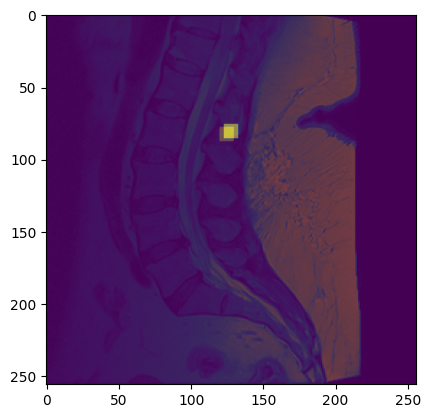

In [28]:
num = 16
#path = path_list[num]
path = "/content/data/processed_lsd_jpgs/0472.jpg"
img = np.array(Image.open(path))
plt.imshow(img)
px = coor_predict['L1/L2'][num][0]*img.shape[1]
py = coor_predict['L1/L2'][num][1]*img.shape[0]
x = coor_label['L1/L2'][num][0]*img.shape[1]
y = coor_label['L1/L2'][num][1]*img.shape[0]

mask = np.zeros(img.shape)
mask[int(y-5):int(y+5), int(x-5):int(x+5)] = 1
pred_mask = np.zeros(img.shape)
pred_mask[int(py-5):int(py+5), int(px-5):int(px+5)] = 1
plt.imshow(mask, alpha=0.5)
plt.imshow(pred_mask, alpha=0.5)
img.shape

# Content from rsna_scs_coordinate_prediction_convnext.ipynb


In [29]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [30]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/815.2 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 44.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 18.6 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 22.10 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [31]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 1.8/1.8 MB 107.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 48.7 MB/s eta 0:00:00



In [32]:
%%time
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [21:57<00:00, 23.5MB/s]
100% 28.2G/28.2G [21:57<00:00, 23.0MB/s]
CPU times: user 14.6 s, sys: 1.93 s, total: 16.6 s
Wall time: 28min 40s


In [33]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
100% 3.76M/3.76M [00:01<00:00, 4.21MB/s]
100% 3.76M/3.76M [00:01<00:00, 3.09MB/s]


In [34]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
sys.path.append('/content/CoaT')
from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.10/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/content/CoaT/src/models/coat.py:589: UserWarning: Overwriting coat_tiny in registry with CoaT.src.models.coat.coat_tiny. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  def coat_tiny(**kwargs):
/content/CoaT/src/models/coat.py:595: UserWarning: Overwriting coat_mini in registry with CoaT.src.models.coat.coat_mini. This is because the name being registered conflicts with an existing nam

## training

In [35]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [36]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    kind: 'detect'
    #kind: 'classify'
    #kind: 'depth'
    #condition: 'nfn'
    condition: 'scs'
    #condition: 'ss'

in_chans: 3

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 30
    min_epochs: 30
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        #lr: 0.001
        lr: 0.0001
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 30
                num_warmup_steps: 1
                num_cycles: 0.5
                last_epoch: -1


Overwriting config.yaml


In [37]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [38]:
class CoorDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]

        self.resize = v2.Resize((256, 256))

    def __getitem__(self, index):
        study_id = self.id[index]
        #print(study_id)
        #try:
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor(study_id)

    def for_scs(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        #img = [self.normalize(self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm')) for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
        sub_meta = pd.concat(meta_list)
        idx = meta.loc[meta.ipp_x == sub_meta.ipp_x.median()].index[0]
        #print(old_idx)
        img_row = meta.iloc[idx]
        before_img_row = meta.iloc[idx-1]
        after_img_row = meta.iloc[idx+1]
        img = self.normalize(self.load_dicom(f'/content/train_images/{img_row.study_id}/{img_row.series_id}/{img_row.instance_number}.dcm'))
        bimg = self.normalize(self.load_dicom(f'/content/train_images/{before_img_row.study_id}/{before_img_row.series_id}/{before_img_row.instance_number}.dcm'))
        aimg = self.normalize(self.load_dicom(f'/content/train_images/{after_img_row.study_id}/{after_img_row.series_id}/{after_img_row.instance_number}.dcm'))
        height, width = img.shape
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            #x = round((row.x/width)*256)
            #y = round((row.y/height)*256)
            x = row.x/width
            y = row.y/height
            coor_dict[row.level] = torch.tensor([x, y]).to(torch.float32)
        img = self.resize(torch.tensor(img[None, ...]))
        bimg = self.resize(torch.tensor(bimg[None, ...]))
        aimg = self.resize(torch.tensor(aimg[None, ...]))
        img = torch.cat([bimg, img, aimg]).to(torch.float32)
        return img, coor_dict

    def for_nfn(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        #img = [self.normalize(self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm')) for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        right_meta_list = []
        left_meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            if row.condition == 'Right Neural Foraminal Narrowing':
                right_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
            else:
                left_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])

        right_sub_meta = pd.concat(right_meta_list)
        left_sub_meta = pd.concat(left_meta_list)
        ridx = meta.loc[meta.ipp_x == right_sub_meta.ipp_x.median()].index[0]
        lidx = meta.loc[meta.ipp_x == left_sub_meta.ipp_x.median()].index[0]
        #display(right_sub_meta)
        #display(coor)
        if self.usage == 'train':
            ridx_shift = random.randint(-2, 2)
            lidx_shift = random.randint(-2, 2)
        else:
            ridx_shift = 0
            lidx_shift = 0
        right_img_row = meta.iloc[min(max(ridx+ridx_shift, 0), len(meta)-1)]
        #display(right_img_row)
        right_before_img_row = meta.iloc[min(max(ridx-1+ridx_shift, 0), len(meta)-1)]
        rightafter_img_row = meta.iloc[min(max(ridx+1+ridx_shift, 0), len(meta)-1)]
        left_img_row = meta.iloc[min(max(lidx+lidx_shift, 0), len(meta)-1)]
        left_before_img_row = meta.iloc[min(max(lidx-1+lidx_shift, 0), len(meta)-1)]
        leftafter_img_row = meta.iloc[min(max(lidx+1+lidx_shift, 0), len(meta)-1)]
        rimg = self.normalize(self.load_dicom(f'/content/train_images/{right_img_row.study_id}/{right_img_row.series_id}/{right_img_row.instance_number}.dcm'))
        rbimg = self.normalize(self.load_dicom(f'/content/train_images/{right_before_img_row.study_id}/{right_before_img_row.series_id}/{right_before_img_row.instance_number}.dcm'))
        raimg = self.normalize(self.load_dicom(f'/content/train_images/{rightafter_img_row.study_id}/{rightafter_img_row.series_id}/{rightafter_img_row.instance_number}.dcm'))
        limg = self.normalize(self.load_dicom(f'/content/train_images/{left_img_row.study_id}/{left_img_row.series_id}/{left_img_row.instance_number}.dcm'))
        lbimg = self.normalize(self.load_dicom(f'/content/train_images/{left_before_img_row.study_id}/{left_before_img_row.series_id}/{left_before_img_row.instance_number}.dcm'))
        laimg = self.normalize(self.load_dicom(f'/content/train_images/{leftafter_img_row.study_id}/{leftafter_img_row.series_id}/{leftafter_img_row.instance_number}.dcm'))
        rheight, rwidth = rimg.shape
        lheight, lwidth = limg.shape
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            if row.condition == 'Right Neural Foraminal Narrowing':
                x = row.x/rwidth
                y = row.y/rheight
                coor_dict['right_' + row.level] = torch.tensor([x, y]).to(torch.float32)
            else:
                x = row.x/lwidth
                y = row.y/lheight
                coor_dict['left_' + row.level] = torch.tensor([x, y]).to(torch.float32)
        rimg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [rbimg, rimg, raimg]])
        limg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [lbimg, limg, laimg]])
        img = torch.stack([limg, rimg]).to(torch.float32).contiguous()
        return img, coor_dict

    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.read_file(path)
        data = dicom.pixel_array
        return data

In [39]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10

class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss

In [40]:
class ConvNextSCSDetect(nn.Module):
    def __init__(self):
        super().__init__()
        #self.size = 256
        self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )

        self.l1 = nn.Linear(self.in_features, 2)
        self.l2 = nn.Linear(self.in_features, 2)
        self.l3 = nn.Linear(self.in_features, 2)
        self.l4 = nn.Linear(self.in_features, 2)
        self.l5 = nn.Linear(self.in_features, 2)

    def forward(self, x, label=None):
        #for loc, img in x.items():
            #print(img.shape)
        #    img = self.encoder.forward_features(img)
        #    img = self.flatten(img)
        #    x[loc] = img
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1.sigmoid(), 'L2/L3': l2.sigmoid(), 'L3/L4': l3.sigmoid(), 'L4/L5': l4.sigmoid(), 'L5/S1': l5.sigmoid()}

class ConvNextNFNDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )
        self.ll1 = nn.Linear(self.in_features, 2)
        self.ll2 = nn.Linear(self.in_features, 2)
        self.ll3 = nn.Linear(self.in_features, 2)
        self.ll4 = nn.Linear(self.in_features, 2)
        self.ll5 = nn.Linear(self.in_features, 2)
        self.rl1 = nn.Linear(self.in_features, 2)
        self.rl2 = nn.Linear(self.in_features, 2)
        self.rl3 = nn.Linear(self.in_features, 2)
        self.rl4 = nn.Linear(self.in_features, 2)
        self.rl5 = nn.Linear(self.in_features, 2)
    def forward(self, x, label=None):
        shape = x.shape
        x = x.reshape(shape[0]*shape[1], 3, shape[-2], shape[-1])
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        x = x.reshape(shape[0], shape[1], -1)
        x_left = x[:, 0, :]
        x_right = x[:, 1, :]
        ll1 = self.ll1(x_left)
        ll2 = self.ll2(x_left)
        ll3 = self.ll3(x_left)
        ll4 = self.ll4(x_left)
        ll5 = self.ll5(x_left)
        rl1 = self.rl1(x_right)
        rl2 = self.rl2(x_right)
        rl3 = self.rl3(x_right)
        rl4 = self.rl4(x_right)
        rl5 = self.rl5(x_right)
        return {'left_L1/L2': ll1.sigmoid(),'left_L2/L3': ll2.sigmoid(),'left_L3/L4': ll3.sigmoid(), 'left_L4/L5': ll4.sigmoid(), 'left_L5/S1': ll5.sigmoid(),
                'right_L1/L2': rl1.sigmoid(), 'right_L2/L3': rl2.sigmoid(), 'right_L3/L4': rl3.sigmoid(), 'right_L4/L5': rl4.sigmoid(), 'right_L5/S1': rl5.sigmoid()}

In [41]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            self.model = ConvNextSCSDetect()
            self.loss_module = SCSDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = ConvNextNFNDetect()
            self.loss_module = NFNSSDetectLoss()
        elif  config['task']['condition'] == 'ss':
            self.model = SSDetect()
            self.loss_module = NFNSSDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        imgs, label, _ = batch
        preds = self.model(imgs)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [42]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [43]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [44]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [45]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [46]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############COORDINATE DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    if config['task']['condition'] != 'ss':
        dataset_train = CoorDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = CoorDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')

    else:
        dataset_train = SSDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = SSDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
        config['train_bs'] = 2
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_pre_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model=False) # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    if config['task']['condition'] == 'scs':
        model = DetectModule.load_from_checkpoint('/content/gdrive/MyDrive/RSNA_SPINE/pretrained_models/scs_detect_pretrained_convnext-base-1e-4.ckpt', strict=False, config=config)
    else:
        model = DetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


scs
detect
20


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: syujinko. Use `wandb login --relogin` to force relogin


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


,Name,Type,Params,Mode
0,model,ConvNextSCSDetect,87.6 M,train
1,loss_module,SCSDetectLoss,0,train


87.6 M    Trainable params
0         Non-trainable params
87.6 M    Total params
350.307   Total estimated model params size (MB)
475       Modules in train mode
0         Modules in eval mode


... (4 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 1/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Metric val_loss improved. New best score: 0.012
Epoch 0/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 0/30  val_loss' reached 0.01234 (best 0.01234), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/scs_detect_pre_1-v2.ckpt' as top 1
Detected KeyboardInterrupt, attempting graceful shutdown ...


NameError: name 'exit' is not defined

# Content from rsna_scs_coordinate_prediction_eff.ipynb


In [47]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [48]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 36.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 17.7 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 33.06 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [49]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.8 MB ? eta -:--:--
   ━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.1/1.8 MB 2.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━ 0.6/1.8 MB 9.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 17.2 MB/s eta 0:00:00



In [50]:
#!cp /content/rsna-2024-lumbar-spine-degenerative-classification.zip /content/gdrive/MyDrive/RSNA_SPINE/data/rsna-2024-lumbar-spine-degenerative-classification.zip

In [51]:
%%time
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [03:40<00:00, 172MB/s]
100% 28.2G/28.2G [03:40<00:00, 138MB/s]
CPU times: user 5.2 s, sys: 731 ms, total: 5.93 s
Wall time: 11min 9s


In [52]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
  0% 0.00/3.76M [00:00<?, ?B/s]
100% 3.76M/3.76M [00:00<00:00, 193MB/s]


In [53]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
sys.path.append('/content/CoaT')
from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.10/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/content/CoaT/src/models/coat.py:589: UserWarning: Overwriting coat_tiny in registry with CoaT.src.models.coat.coat_tiny. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  def coat_tiny(**kwargs):
/content/CoaT/src/models/coat.py:595: UserWarning: Overwriting coat_mini in registry with CoaT.src.models.coat.coat_mini. This is because the name being registered conflicts with an existing nam

## training

In [54]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [55]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    kind: 'detect'
    #kind: 'classify'
    #kind: 'depth'
    #condition: 'nfn'
    condition: 'scs'
    #condition: 'ss'

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 30
    min_epochs: 30
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        #lr: 0.001
        lr: 0.0001
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 30
                num_warmup_steps: 1
                num_cycles: 0.5
                last_epoch: -1


Overwriting config.yaml


In [56]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [57]:
class CoorDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]

        self.resize = v2.Resize((256, 256))
    def __getitem__(self, index):
        study_id = self.id[index]
        #print(study_id)
        #try:
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor(study_id)

    def for_scs(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        #img = [self.normalize(self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm')) for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
        sub_meta = pd.concat(meta_list)
        idx = meta.loc[meta.ipp_x == sub_meta.ipp_x.median()].index[0]
        #print(old_idx)
        img_row = meta.iloc[idx]
        before_img_row = meta.iloc[idx-1]
        after_img_row = meta.iloc[idx+1]
        img = self.normalize(self.load_dicom(f'/content/train_images/{img_row.study_id}/{img_row.series_id}/{img_row.instance_number}.dcm'))
        bimg = self.normalize(self.load_dicom(f'/content/train_images/{before_img_row.study_id}/{before_img_row.series_id}/{before_img_row.instance_number}.dcm'))
        aimg = self.normalize(self.load_dicom(f'/content/train_images/{after_img_row.study_id}/{after_img_row.series_id}/{after_img_row.instance_number}.dcm'))
        height, width = img.shape
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            #x = round((row.x/width)*256)
            #y = round((row.y/height)*256)
            x = row.x/width
            y = row.y/height
            coor_dict[row.level] = torch.tensor([x, y]).to(torch.float32)
        img = self.resize(torch.tensor(img[None, ...]))
        bimg = self.resize(torch.tensor(bimg[None, ...]))
        aimg = self.resize(torch.tensor(aimg[None, ...]))
        img = torch.cat([bimg, img, aimg]).to(torch.float32)
        return img, coor_dict

    def for_nfn(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        #img = [self.normalize(self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm')) for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        right_meta_list = []
        left_meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            if row.condition == 'Right Neural Foraminal Narrowing':
                right_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
            else:
                left_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])

        right_sub_meta = pd.concat(right_meta_list)
        left_sub_meta = pd.concat(left_meta_list)
        ridx = meta.loc[meta.ipp_x == right_sub_meta.ipp_x.median()].index[0]
        lidx = meta.loc[meta.ipp_x == left_sub_meta.ipp_x.median()].index[0]
        #display(right_sub_meta)
        #display(coor)
        if self.usage == 'train':
            ridx_shift = random.randint(-2, 2)
            lidx_shift = random.randint(-2, 2)
        else:
            ridx_shift = 0
            lidx_shift = 0
        right_img_row = meta.iloc[min(max(ridx+ridx_shift, 0), len(meta)-1)]
        #display(right_img_row)
        right_before_img_row = meta.iloc[min(max(ridx-1+ridx_shift, 0), len(meta)-1)]
        rightafter_img_row = meta.iloc[min(max(ridx+1+ridx_shift, 0), len(meta)-1)]
        left_img_row = meta.iloc[min(max(lidx+lidx_shift, 0), len(meta)-1)]
        left_before_img_row = meta.iloc[min(max(lidx-1+lidx_shift, 0), len(meta)-1)]
        leftafter_img_row = meta.iloc[min(max(lidx+1+lidx_shift, 0), len(meta)-1)]
        rimg = self.normalize(self.load_dicom(f'/content/train_images/{right_img_row.study_id}/{right_img_row.series_id}/{right_img_row.instance_number}.dcm'))
        rbimg = self.normalize(self.load_dicom(f'/content/train_images/{right_before_img_row.study_id}/{right_before_img_row.series_id}/{right_before_img_row.instance_number}.dcm'))
        raimg = self.normalize(self.load_dicom(f'/content/train_images/{rightafter_img_row.study_id}/{rightafter_img_row.series_id}/{rightafter_img_row.instance_number}.dcm'))
        limg = self.normalize(self.load_dicom(f'/content/train_images/{left_img_row.study_id}/{left_img_row.series_id}/{left_img_row.instance_number}.dcm'))
        lbimg = self.normalize(self.load_dicom(f'/content/train_images/{left_before_img_row.study_id}/{left_before_img_row.series_id}/{left_before_img_row.instance_number}.dcm'))
        laimg = self.normalize(self.load_dicom(f'/content/train_images/{leftafter_img_row.study_id}/{leftafter_img_row.series_id}/{leftafter_img_row.instance_number}.dcm'))
        rheight, rwidth = rimg.shape
        lheight, lwidth = limg.shape
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            if row.condition == 'Right Neural Foraminal Narrowing':
                x = row.x/rwidth
                y = row.y/rheight
                coor_dict['right_' + row.level] = torch.tensor([x, y]).to(torch.float32)
            else:
                x = row.x/lwidth
                y = row.y/lheight
                coor_dict['left_' + row.level] = torch.tensor([x, y]).to(torch.float32)
        rimg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [rbimg, rimg, raimg]])
        limg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [lbimg, limg, laimg]])
        img = torch.stack([limg, rimg]).to(torch.float32).contiguous()
        return img, coor_dict

    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.read_file(path)
        data = dicom.pixel_array
        return data

In [58]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class SCSDetectRelativePositionLoss(nn.Module):
    def __init__(self):
        super(SCSDetectRelativePositionLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        loss/5
        relative_positional_loss = 0
        for l in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            relative_positional_pred_list = []
            relative_positional_tar_list = []
            for ll in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
                if l == ll:
                    continue
                pred1, pred2 = outputs[l], outputs[ll]
                tar1, tar2 = targets[l], targets[ll]
                dist_pred = torch.sqrt((pred1[:, 0]-pred2[:, 0])**2 + (pred1[:, 1]-pred2[:, 1])**2)
                dist_tar = torch.sqrt((tar1[:, 0]-tar2[:, 0])**2 + (tar1[:, 1]-tar2[:, 1])**2)
                relative_positional_pred_list.append(dist_pred)
                relative_positional_tar_list.append(dist_tar)
            relative_positional_pred = torch.cat(relative_positional_pred_list)
            relative_positional_tar = torch.cat(relative_positional_tar_list)
            relative_positional_loss += nn.functional.mse_loss(relative_positional_pred, relative_positional_tar)
        return loss/5 + relative_positional_loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10

class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss

In [59]:
class ConvNextSCSDetect(nn.Module):
    def __init__(self):
        super().__init__()
        #self.size = 256
        #self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        #self.encoder = timm.create_model('caformer_m36.sail_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        self.encoder = timm.create_model('tf_efficientnetv2_l.in21k_ft_in1k', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )

        self.l1 = nn.Linear(self.in_features, 2)
        self.l2 = nn.Linear(self.in_features, 2)
        self.l3 = nn.Linear(self.in_features, 2)
        self.l4 = nn.Linear(self.in_features, 2)
        self.l5 = nn.Linear(self.in_features, 2)
        #self.out = nn.Linear(self.in_features, 10)
    def forward(self, x, label=None):
        #for loc, img in x.items():
            #print(img.shape)
        #    img = self.encoder.forward_features(img)
        #    img = self.flatten(img)
        #    x[loc] = img
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        #out = self.out(x)
        #l1 = out[:, :2]
        #l2 = out[:, 2:4]
        #l3 = out[:, 4:6]
        #l4 = out[:, 6:8]
        #l5 = out[:, 8:]
        return {'L1/L2': l1.sigmoid(), 'L2/L3': l2.sigmoid(), 'L3/L4': l3.sigmoid(), 'L4/L5': l4.sigmoid(), 'L5/S1': l5.sigmoid()}

class ConvNextNFNDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )
        self.ll1 = nn.Linear(self.in_features, 2)
        self.ll2 = nn.Linear(self.in_features, 2)
        self.ll3 = nn.Linear(self.in_features, 2)
        self.ll4 = nn.Linear(self.in_features, 2)
        self.ll5 = nn.Linear(self.in_features, 2)
        self.rl1 = nn.Linear(self.in_features, 2)
        self.rl2 = nn.Linear(self.in_features, 2)
        self.rl3 = nn.Linear(self.in_features, 2)
        self.rl4 = nn.Linear(self.in_features, 2)
        self.rl5 = nn.Linear(self.in_features, 2)
    def forward(self, x, label=None):
        shape = x.shape
        x = x.reshape(shape[0]*shape[1], 3, shape[-2], shape[-1])
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        x = x.reshape(shape[0], shape[1], -1)
        x_left = x[:, 0, :]
        x_right = x[:, 1, :]
        ll1 = self.ll1(x_left)
        ll2 = self.ll2(x_left)
        ll3 = self.ll3(x_left)
        ll4 = self.ll4(x_left)
        ll5 = self.ll5(x_left)
        rl1 = self.rl1(x_right)
        rl2 = self.rl2(x_right)
        rl3 = self.rl3(x_right)
        rl4 = self.rl4(x_right)
        rl5 = self.rl5(x_right)
        return {'left_L1/L2': ll1.sigmoid(),'left_L2/L3': ll2.sigmoid(),'left_L3/L4': ll3.sigmoid(), 'left_L4/L5': ll4.sigmoid(), 'left_L5/S1': ll5.sigmoid(),
                'right_L1/L2': rl1.sigmoid(), 'right_L2/L3': rl2.sigmoid(), 'right_L3/L4': rl3.sigmoid(), 'right_L4/L5': rl4.sigmoid(), 'right_L5/S1': rl5.sigmoid()}


In [60]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            self.model = ConvNextSCSDetect()
            #self.loss_module = SCSDetectRelativePositionLoss()
            self.loss_module = SCSDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = ConvNextNFNDetect()
            self.loss_module = NFNSSDetectLoss()
        elif  config['task']['condition'] == 'ss':
            self.model = SSDetect()
            self.loss_module = NFNSSDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        imgs, label, _ = batch
        preds = self.model(imgs)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [61]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [62]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [63]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [64]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [65]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############COORDINATE DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    if config['task']['condition'] != 'ss':
        dataset_train = CoorDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = CoorDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')

    else:
        dataset_train = SSDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = SSDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
        config['train_bs'] = 2
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_pre_effv2l_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model=False)
    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    if config['task']['condition'] == 'scs' or config['task']['condition'] == 'nfn':
        model = DetectModule.load_from_checkpoint('/content/gdrive/MyDrive/RSNA_SPINE/pretrained_models/scs_detect_pretrained_efficientnetv2l_1e-4.ckpt', strict=False, config=config)
    else:
        model = DetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


scs
detect
20


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: syujinko. Use `wandb login --relogin` to force relogin


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


,Name,Type,Params,Mode
0,model,ConvNextSCSDetect,117 M,train
1,loss_module,SCSDetectLoss,0,train


117 M     Trainable params
0         Non-trainable params
117 M     Total params
468.988   Total estimated model params size (MB)
1447      Modules in train mode
0         Modules in eval mode


... (204 outputs left out)

Metric val_loss improved. New best score: 0.008
Epoch 0/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 0/30  val_loss' reached 0.00850 (best 0.00850), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/scs_detect_pre_effv2l_2-v1.ckpt' as top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 2/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Metric val_loss improved by 0.001 >= min_delta = 0.0. New best score: 0.008
Epoch 1/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 1/30  val_loss' reached 0.00752 (best 0.00752), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/scs_detect_pre_effv2l_2-v1.ckpt' as top 1


# Content from rsna_nfn_coordinate_prediction_convnext.ipynb


In [66]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [67]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/815.2 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 809.0/815.2 kB 37.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 41.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 24.0 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 16.02 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [68]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 60.9 MB/s eta 0:00:00



In [69]:
%%time
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [23:36<00:00, 21.2MB/s]
100% 28.2G/28.2G [23:36<00:00, 21.4MB/s]
CPU times: user 18.5 s, sys: 2.34 s, total: 20.9 s
Wall time: 30min 32s


In [70]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
100% 3.76M/3.76M [00:01<00:00, 4.00MB/s]
100% 3.76M/3.76M [00:01<00:00, 2.94MB/s]


In [71]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
sys.path.append('/content/CoaT')
from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate

from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.10/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/content/CoaT/src/models/coat.py:589: UserWarning: Overwriting coat_tiny in registry with CoaT.src.models.coat.coat_tiny. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  def coat_tiny(**kwargs):
/content/CoaT/src/models/coat.py:595: UserWarning: Overwriting coat_mini in registry with CoaT.src.models.coat.coat_mini. This is because the name being registered conflicts with an existing nam

## training

In [72]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [73]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    kind: 'detect'
    #kind: 'classify'
    #kind: 'depth'
    condition: 'nfn'
    #condition: 'scs'
    #condition: 'ss'

in_chans: 3

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 30
    min_epochs: 30
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        #lr: 0.001
        lr: 0.0001
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 30
                num_warmup_steps: 1
                num_cycles: 0.5
                last_epoch: -1


Writing config.yaml


In [74]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [75]:
class CoorDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]

        self.resize = v2.Resize((256, 256))
        self.wide_transforms = A.Compose([
            A.RandomBrightnessContrast(p=1),
            A.OneOf([
                A.MotionBlur(blur_limit=3),
                A.MedianBlur(blur_limit=3),
                A.GaussianBlur(blur_limit=3),
            ], p=0.25),
            A.ShiftScaleRotate(shift_limit=0.2, scale_limit=(-0.3, 0.3), rotate_limit=20, border_mode=0, p=1),
            A.Resize(128, 224),
        ])
        self.rec_transforms = A.Compose([
            A.HorizontalFlip(p=0.5),
            A.RandomBrightnessContrast(p=1),
            A.OneOf([
                A.MotionBlur(blur_limit=3),
                A.MedianBlur(blur_limit=3),
                A.GaussianBlur(blur_limit=3),
            ], p=0.25),

            A.OneOf([
            ], p=0.0),
            A.ShiftScaleRotate(shift_limit=0.2, scale_limit=(-0.3, 0.3), rotate_limit=20, border_mode=0, p=1),
            A.Resize(224, 224),
        ])
    def __getitem__(self, index):
        study_id = self.id[index]
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor(study_id)

    def for_scs(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
        sub_meta = pd.concat(meta_list)
        idx = meta.loc[meta.ipp_x == sub_meta.ipp_x.median()].index[0]
        img_row = meta.iloc[idx]
        before_img_row = meta.iloc[idx-1]
        after_img_row = meta.iloc[idx+1]
        img = self.normalize(self.load_dicom(f'/content/train_images/{img_row.study_id}/{img_row.series_id}/{img_row.instance_number}.dcm'))
        bimg = self.normalize(self.load_dicom(f'/content/train_images/{before_img_row.study_id}/{before_img_row.series_id}/{before_img_row.instance_number}.dcm'))
        aimg = self.normalize(self.load_dicom(f'/content/train_images/{after_img_row.study_id}/{after_img_row.series_id}/{after_img_row.instance_number}.dcm'))
        height, width = img.shape
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            x = row.x/width
            y = row.y/height
            coor_dict[row.level] = torch.tensor([x, y]).to(torch.float32)
        img = self.resize(torch.tensor(img[None, ...]))
        bimg = self.resize(torch.tensor(bimg[None, ...]))
        aimg = self.resize(torch.tensor(aimg[None, ...]))
        img = torch.cat([bimg, img, aimg]).to(torch.float32)
        return img, coor_dict

    def for_nfn(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        right_meta_list = []
        left_meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            if row.condition == 'Right Neural Foraminal Narrowing':
                right_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
            else:
                left_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])

        right_sub_meta = pd.concat(right_meta_list)
        left_sub_meta = pd.concat(left_meta_list)
        ridx = meta.loc[meta.ipp_x == right_sub_meta.ipp_x.median()].index[0]
        lidx = meta.loc[meta.ipp_x == left_sub_meta.ipp_x.median()].index[0]
        if self.usage == 'train':
            ridx_shift = random.randint(-2, 2)
            lidx_shift = random.randint(-2, 2)
        else:
            ridx_shift = 0
            lidx_shift = 0
        right_img_row = meta.iloc[min(max(ridx+ridx_shift, 0), len(meta)-1)]
        right_before_img_row = meta.iloc[min(max(ridx-1+ridx_shift, 0), len(meta)-1)]
        rightafter_img_row = meta.iloc[min(max(ridx+1+ridx_shift, 0), len(meta)-1)]
        left_img_row = meta.iloc[min(max(lidx+lidx_shift, 0), len(meta)-1)]
        left_before_img_row = meta.iloc[min(max(lidx-1+lidx_shift, 0), len(meta)-1)]
        leftafter_img_row = meta.iloc[min(max(lidx+1+lidx_shift, 0), len(meta)-1)]
        rimg = self.normalize(self.load_dicom(f'/content/train_images/{right_img_row.study_id}/{right_img_row.series_id}/{right_img_row.instance_number}.dcm'))
        rbimg = self.normalize(self.load_dicom(f'/content/train_images/{right_before_img_row.study_id}/{right_before_img_row.series_id}/{right_before_img_row.instance_number}.dcm'))
        raimg = self.normalize(self.load_dicom(f'/content/train_images/{rightafter_img_row.study_id}/{rightafter_img_row.series_id}/{rightafter_img_row.instance_number}.dcm'))
        limg = self.normalize(self.load_dicom(f'/content/train_images/{left_img_row.study_id}/{left_img_row.series_id}/{left_img_row.instance_number}.dcm'))
        lbimg = self.normalize(self.load_dicom(f'/content/train_images/{left_before_img_row.study_id}/{left_before_img_row.series_id}/{left_before_img_row.instance_number}.dcm'))
        laimg = self.normalize(self.load_dicom(f'/content/train_images/{leftafter_img_row.study_id}/{leftafter_img_row.series_id}/{leftafter_img_row.instance_number}.dcm'))
        rheight, rwidth = rimg.shape
        lheight, lwidth = limg.shape
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            if row.condition == 'Right Neural Foraminal Narrowing':
                x = row.x/rwidth
                y = row.y/rheight
                coor_dict['right_' + row.level] = torch.tensor([x, y]).to(torch.float32)
            else:
                x = row.x/lwidth
                y = row.y/lheight
                coor_dict['left_' + row.level] = torch.tensor([x, y]).to(torch.float32)
        rimg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [rbimg, rimg, raimg]])
        limg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [lbimg, limg, laimg]])
        img = torch.stack([limg, rimg]).to(torch.float32).contiguous()
        return img, coor_dict

    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.read_file(path)
        data = dicom.pixel_array
        return data

In [76]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10

class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss

In [77]:
class ConvNextSCSDetect(nn.Module):
    def __init__(self):
        super().__init__()
        #self.size = 256
        self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )

        self.l1 = nn.Linear(self.in_features, 2)
        self.l2 = nn.Linear(self.in_features, 2)
        self.l3 = nn.Linear(self.in_features, 2)
        self.l4 = nn.Linear(self.in_features, 2)
        self.l5 = nn.Linear(self.in_features, 2)

    def forward(self, x, label=None):
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1.sigmoid(), 'L2/L3': l2.sigmoid(), 'L3/L4': l3.sigmoid(), 'L4/L5': l4.sigmoid(), 'L5/S1': l5.sigmoid()}

class ConvNextNFNDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )
        self.ll1 = nn.Linear(self.in_features, 2)
        self.ll2 = nn.Linear(self.in_features, 2)
        self.ll3 = nn.Linear(self.in_features, 2)
        self.ll4 = nn.Linear(self.in_features, 2)
        self.ll5 = nn.Linear(self.in_features, 2)
        self.rl1 = nn.Linear(self.in_features, 2)
        self.rl2 = nn.Linear(self.in_features, 2)
        self.rl3 = nn.Linear(self.in_features, 2)
        self.rl4 = nn.Linear(self.in_features, 2)
        self.rl5 = nn.Linear(self.in_features, 2)
    def forward(self, x, label=None):
        shape = x.shape
        x = x.reshape(shape[0]*shape[1], 3, shape[-2], shape[-1])
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        x = x.reshape(shape[0], shape[1], -1)
        x_left = x[:, 0, :]
        x_right = x[:, 1, :]
        ll1 = self.ll1(x_left)
        ll2 = self.ll2(x_left)
        ll3 = self.ll3(x_left)
        ll4 = self.ll4(x_left)
        ll5 = self.ll5(x_left)
        rl1 = self.rl1(x_right)
        rl2 = self.rl2(x_right)
        rl3 = self.rl3(x_right)
        rl4 = self.rl4(x_right)
        rl5 = self.rl5(x_right)
        return {'left_L1/L2': ll1.sigmoid(),'left_L2/L3': ll2.sigmoid(),'left_L3/L4': ll3.sigmoid(), 'left_L4/L5': ll4.sigmoid(), 'left_L5/S1': ll5.sigmoid(),
                'right_L1/L2': rl1.sigmoid(), 'right_L2/L3': rl2.sigmoid(), 'right_L3/L4': rl3.sigmoid(), 'right_L4/L5': rl4.sigmoid(), 'right_L5/S1': rl5.sigmoid()}


In [78]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            self.model = ConvNextSCSDetect()
            self.loss_module = SCSDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = ConvNextNFNDetect()
            self.loss_module = NFNSSDetectLoss()
        elif  config['task']['condition'] == 'ss':
            self.model = SSDetect()
            self.loss_module = NFNSSDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        imgs, label, _ = batch
        preds = self.model(imgs)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        """
        all_preds = torch.cat(self.val_step_outputs)
        all_labels = torch.cat(self.val_step_labels)
        val_loss = self.loss_module(all_preds, all_labels)
        self.log("val_loss", val_loss, on_step=False, on_epoch=True, prog_bar=True)
        all_preds = all_preds.cpu().detach().numpy()
        all_labels = all_labels.cpu().detach().numpy()
        print(f'val_loss: {val_loss}')
        self.val_step_outputs.clear()
        self.val_step_labels.clear()
        """
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()


In [79]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [80]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [81]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [82]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [83]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############COORDINATE DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    if config['task']['condition'] != 'ss':
        dataset_train = CoorDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = CoorDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')

    else:
        dataset_train = SSDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = SSDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
        config['train_bs'] = 2
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_pre_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model=False) # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    if config['task']['condition'] == 'scs' or config['task']['condition'] == 'nfn':
        model = DetectModule.load_from_checkpoint('/content/gdrive/MyDrive/RSNA_SPINE/pretrained_models/scs_detect_pretrained_convnext-base-1e-4.ckpt', strict=False, config=config)
    else:
        model = DetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


nfn
detect
20


model.safetensors:   0%|          | 0.00/354M [00:00<?, ?B/s]

wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.


<IPython.core.display.Javascript object>

wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


... (132 outputs left out)

Metric val_loss improved by 0.000 >= min_delta = 0.0. New best score: 0.008
Epoch 8/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 8/30  val_loss' reached 0.00834 (best 0.00834), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/nfn_detect_pre_1-v1.ckpt' as top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 10/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Metric val_loss improved by 0.001 >= min_delta = 0.0. New best score: 0.008
Epoch 9/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 9/30  val_loss' reached 0.00772 (best 0.00772), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/nfn_detect_pre_1-v1.ckpt' as top 1


# Content from rsna_nfn_coordinate_prediction_eff.ipynb


In [84]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [85]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 44.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 27.2 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 17.19 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [86]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.8 MB ? eta -:--:--
   ━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.1/1.8 MB 3.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━ 1.0/1.8 MB 14.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 18.6 MB/s eta 0:00:00



In [87]:
#!cp /content/rsna-2024-lumbar-spine-degenerative-classification.zip /content/gdrive/MyDrive/RSNA_SPINE/data/rsna-2024-lumbar-spine-degenerative-classification.zip

In [88]:
%%time
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [18:43<00:00, 25.3MB/s]
100% 28.2G/28.2G [18:43<00:00, 27.0MB/s]
CPU times: user 14.2 s, sys: 1.92 s, total: 16.1 s
Wall time: 25min 32s


In [89]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
100% 3.76M/3.76M [00:00<00:00, 5.67MB/s]
100% 3.76M/3.76M [00:00<00:00, 4.16MB/s]


In [90]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
sys.path.append('/content/CoaT')
from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.10/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/content/CoaT/src/models/coat.py:589: UserWarning: Overwriting coat_tiny in registry with CoaT.src.models.coat.coat_tiny. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  def coat_tiny(**kwargs):
/content/CoaT/src/models/coat.py:595: UserWarning: Overwriting coat_mini in registry with CoaT.src.models.coat.coat_mini. This is because the name being registered conflicts with an existing nam

## training

In [91]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [92]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    kind: 'detect'
    #kind: 'classify'
    #kind: 'depth'
    condition: 'nfn'
    #condition: 'scs'
    #condition: 'ss'

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 30
    min_epochs: 30
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        #lr: 0.001
        lr: 0.0001
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 30
                num_warmup_steps: 1
                num_cycles: 0.5
                last_epoch: -1


Overwriting config.yaml


In [93]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [94]:
class CoorDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]

        self.resize = v2.Resize((256, 256))
    def __getitem__(self, index):
        study_id = self.id[index]
        #print(study_id)
        #try:
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor(study_id)

    def for_scs(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        #img = [self.normalize(self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm')) for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
        sub_meta = pd.concat(meta_list)
        idx = meta.loc[meta.ipp_x == sub_meta.ipp_x.median()].index[0]
        #print(old_idx)
        img_row = meta.iloc[idx]
        before_img_row = meta.iloc[idx-1]
        after_img_row = meta.iloc[idx+1]
        img = self.normalize(self.load_dicom(f'/content/train_images/{img_row.study_id}/{img_row.series_id}/{img_row.instance_number}.dcm'))
        bimg = self.normalize(self.load_dicom(f'/content/train_images/{before_img_row.study_id}/{before_img_row.series_id}/{before_img_row.instance_number}.dcm'))
        aimg = self.normalize(self.load_dicom(f'/content/train_images/{after_img_row.study_id}/{after_img_row.series_id}/{after_img_row.instance_number}.dcm'))
        height, width = img.shape
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            #x = round((row.x/width)*256)
            #y = round((row.y/height)*256)
            x = row.x/width
            y = row.y/height
            coor_dict[row.level] = torch.tensor([x, y]).to(torch.float32)
        img = self.resize(torch.tensor(img[None, ...]))
        bimg = self.resize(torch.tensor(bimg[None, ...]))
        aimg = self.resize(torch.tensor(aimg[None, ...]))
        img = torch.cat([bimg, img, aimg]).to(torch.float32)
        return img, coor_dict

    def for_nfn(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        #img = [self.normalize(self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm')) for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        right_meta_list = []
        left_meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            if row.condition == 'Right Neural Foraminal Narrowing':
                right_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
            else:
                left_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])

        right_sub_meta = pd.concat(right_meta_list)
        left_sub_meta = pd.concat(left_meta_list)
        ridx = meta.loc[meta.ipp_x == right_sub_meta.ipp_x.median()].index[0]
        lidx = meta.loc[meta.ipp_x == left_sub_meta.ipp_x.median()].index[0]
        #display(right_sub_meta)
        #display(coor)
        if self.usage == 'train':
            ridx_shift = random.randint(-2, 2)
            lidx_shift = random.randint(-2, 2)
        else:
            ridx_shift = 0
            lidx_shift = 0
        right_img_row = meta.iloc[min(max(ridx+ridx_shift, 0), len(meta)-1)]
        #display(right_img_row)
        right_before_img_row = meta.iloc[min(max(ridx-1+ridx_shift, 0), len(meta)-1)]
        rightafter_img_row = meta.iloc[min(max(ridx+1+ridx_shift, 0), len(meta)-1)]
        left_img_row = meta.iloc[min(max(lidx+lidx_shift, 0), len(meta)-1)]
        left_before_img_row = meta.iloc[min(max(lidx-1+lidx_shift, 0), len(meta)-1)]
        leftafter_img_row = meta.iloc[min(max(lidx+1+lidx_shift, 0), len(meta)-1)]
        rimg = self.normalize(self.load_dicom(f'/content/train_images/{right_img_row.study_id}/{right_img_row.series_id}/{right_img_row.instance_number}.dcm'))
        rbimg = self.normalize(self.load_dicom(f'/content/train_images/{right_before_img_row.study_id}/{right_before_img_row.series_id}/{right_before_img_row.instance_number}.dcm'))
        raimg = self.normalize(self.load_dicom(f'/content/train_images/{rightafter_img_row.study_id}/{rightafter_img_row.series_id}/{rightafter_img_row.instance_number}.dcm'))
        limg = self.normalize(self.load_dicom(f'/content/train_images/{left_img_row.study_id}/{left_img_row.series_id}/{left_img_row.instance_number}.dcm'))
        lbimg = self.normalize(self.load_dicom(f'/content/train_images/{left_before_img_row.study_id}/{left_before_img_row.series_id}/{left_before_img_row.instance_number}.dcm'))
        laimg = self.normalize(self.load_dicom(f'/content/train_images/{leftafter_img_row.study_id}/{leftafter_img_row.series_id}/{leftafter_img_row.instance_number}.dcm'))
        rheight, rwidth = rimg.shape
        lheight, lwidth = limg.shape
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            if row.condition == 'Right Neural Foraminal Narrowing':
                x = row.x/rwidth
                y = row.y/rheight
                coor_dict['right_' + row.level] = torch.tensor([x, y]).to(torch.float32)
            else:
                x = row.x/lwidth
                y = row.y/lheight
                coor_dict['left_' + row.level] = torch.tensor([x, y]).to(torch.float32)
        rimg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [rbimg, rimg, raimg]])
        limg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [lbimg, limg, laimg]])
        img = torch.stack([limg, rimg]).to(torch.float32).contiguous()
        return img, coor_dict

    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.read_file(path)
        data = dicom.pixel_array
        return data

In [95]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class SCSDetectRelativePositionLoss(nn.Module):
    def __init__(self):
        super(SCSDetectRelativePositionLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        loss/5
        relative_positional_loss = 0
        for l in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            relative_positional_pred_list = []
            relative_positional_tar_list = []
            for ll in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
                if l == ll:
                    continue
                pred1, pred2 = outputs[l], outputs[ll]
                tar1, tar2 = targets[l], targets[ll]
                dist_pred = torch.sqrt((pred1[:, 0]-pred2[:, 0])**2 + (pred1[:, 1]-pred2[:, 1])**2)
                dist_tar = torch.sqrt((tar1[:, 0]-tar2[:, 0])**2 + (tar1[:, 1]-tar2[:, 1])**2)
                relative_positional_pred_list.append(dist_pred)
                relative_positional_tar_list.append(dist_tar)
            relative_positional_pred = torch.cat(relative_positional_pred_list)
            relative_positional_tar = torch.cat(relative_positional_tar_list)
            relative_positional_loss += nn.functional.mse_loss(relative_positional_pred, relative_positional_tar)
        return loss/5 + relative_positional_loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10

class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss
class ALLLoss(nn.Module):
    def __init__(self):
        super(ALLLoss, self).__init__()
        self.scs_loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        #self.lss_loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        #self.rss_loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        #self.lnfn_loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        #self.rnfn_loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.ss_loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.nfn_loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
    def forward(self, outputs, targets):
        #scs_loss = self.scs_loss(outputs['scs'], targets['scs'].reshape(-1))
        ss_loss = self.ss_loss(torch.cat([outputs['lss'], outputs['rss']]), torch.cat([targets['lss'].reshape(-1), targets['rss'].reshape(-1)]))
        #nfn_loss = self.nfn_loss(torch.cat([outputs['lnfn'], outputs['rnfn']]), torch.cat([targets['lnfn'].reshape(-1), targets['rnfn'].reshape(-1)]))
        #print(loss)
        #loss = (scs_loss + ss_loss + nfn_loss)/3
        loss = ss_loss
        return loss, 0, 0, 0
        return loss, scs_loss, ss_loss, nfn_loss

In [96]:
class ConvNextSCSDetect(nn.Module):
    def __init__(self):
        super().__init__()
        #self.size = 256
        #self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        #self.encoder = timm.create_model('caformer_m36.sail_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        self.encoder = timm.create_model('tf_efficientnetv2_l.in21k_ft_in1k', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )

        self.l1 = nn.Linear(self.in_features, 2)
        self.l2 = nn.Linear(self.in_features, 2)
        self.l3 = nn.Linear(self.in_features, 2)
        self.l4 = nn.Linear(self.in_features, 2)
        self.l5 = nn.Linear(self.in_features, 2)
        #self.out = nn.Linear(self.in_features, 10)
    def forward(self, x, label=None):
        #for loc, img in x.items():
            #print(img.shape)
        #    img = self.encoder.forward_features(img)
        #    img = self.flatten(img)
        #    x[loc] = img
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        #out = self.out(x)
        #l1 = out[:, :2]
        #l2 = out[:, 2:4]
        #l3 = out[:, 4:6]
        #l4 = out[:, 6:8]
        #l5 = out[:, 8:]
        return {'L1/L2': l1.sigmoid(), 'L2/L3': l2.sigmoid(), 'L3/L4': l3.sigmoid(), 'L4/L5': l4.sigmoid(), 'L5/S1': l5.sigmoid()}

class ConvNextNFNDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = timm.create_model('tf_efficientnetv2_l.in21k_ft_in1k', in_chans=3, pretrained=True, num_classes=0, drop_rate=0.)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )
        self.ll1 = nn.Linear(self.in_features, 2)
        self.ll2 = nn.Linear(self.in_features, 2)
        self.ll3 = nn.Linear(self.in_features, 2)
        self.ll4 = nn.Linear(self.in_features, 2)
        self.ll5 = nn.Linear(self.in_features, 2)
        self.rl1 = nn.Linear(self.in_features, 2)
        self.rl2 = nn.Linear(self.in_features, 2)
        self.rl3 = nn.Linear(self.in_features, 2)
        self.rl4 = nn.Linear(self.in_features, 2)
        self.rl5 = nn.Linear(self.in_features, 2)
    def forward(self, x, label=None):
        shape = x.shape
        x = x.reshape(shape[0]*shape[1], 3, shape[-2], shape[-1])
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        x = x.reshape(shape[0], shape[1], -1)
        x_left = x[:, 0, :]
        x_right = x[:, 1, :]
        ll1 = self.ll1(x_left)
        ll2 = self.ll2(x_left)
        ll3 = self.ll3(x_left)
        ll4 = self.ll4(x_left)
        ll5 = self.ll5(x_left)
        rl1 = self.rl1(x_right)
        rl2 = self.rl2(x_right)
        rl3 = self.rl3(x_right)
        rl4 = self.rl4(x_right)
        rl5 = self.rl5(x_right)
        return {'left_L1/L2': ll1.sigmoid(),'left_L2/L3': ll2.sigmoid(),'left_L3/L4': ll3.sigmoid(), 'left_L4/L5': ll4.sigmoid(), 'left_L5/S1': ll5.sigmoid(),
                'right_L1/L2': rl1.sigmoid(), 'right_L2/L3': rl2.sigmoid(), 'right_L3/L4': rl3.sigmoid(), 'right_L4/L5': rl4.sigmoid(), 'right_L5/S1': rl5.sigmoid()}


In [97]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            self.model = ConvNextSCSDetect()
            #self.loss_module = SCSDetectRelativePositionLoss()
            self.loss_module = SCSDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = ConvNextNFNDetect()
            self.loss_module = NFNSSDetectLoss()
        elif  config['task']['condition'] == 'ss':
            self.model = SSDetect()
            self.loss_module = NFNSSDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        imgs, label, _ = batch
        preds = self.model(imgs)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [98]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [99]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [100]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [101]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [102]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############COORDINATE DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    if config['task']['condition'] != 'ss':
        dataset_train = CoorDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = CoorDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')

    else:
        dataset_train = SSDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = SSDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
        config['train_bs'] = 2
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_pre_effv2l_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model=False)
    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    if config['task']['condition'] == 'scs' or config['task']['condition'] == 'nfn':
        model = DetectModule.load_from_checkpoint('/content/gdrive/MyDrive/RSNA_SPINE/pretrained_models/scs_detect_pretrained_efficientnetv2l_1e-4.ckpt', strict=False, config=config)
    else:
        model = DetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


nfn
detect
20


model.safetensors:   0%|          | 0.00/476M [00:00<?, ?B/s]

wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: syujinko. Use `wandb login --relogin` to force relogin


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


,Name,Type,Params,Mode
0,model,ConvNextNFNDetect,117 M,train
1,loss_module,NFNSSDetectLoss,0,train


... (79 outputs left out)

Epoch 24/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 24/30  val_loss' was not in top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 26/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Epoch 25/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 25/30  val_loss' was not in top 1


# Content from rsna_ss_coordinate_prediction.ipynb


In [103]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [104]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

fatal: destination path 'CoaT' already exists and is not an empty directory.


In [105]:
!pip install torchtune

In [106]:
!pip install -q pydicom==2.4.4

  Using cached pylibjpeg-2.0.1-py3-none-any.whl.metadata (7.8 kB)
Using cached pylibjpeg-2.0.1-py3-none-any.whl (24 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 65.1 MB/s eta 0:00:00



In [107]:
%%time
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [22:32<00:00, 25.1MB/s]
100% 28.2G/28.2G [22:32<00:00, 22.4MB/s]
CPU times: user 15.1 s, sys: 2.12 s, total: 17.2 s
Wall time: 29min 14s


In [108]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
100% 3.76M/3.76M [00:01<00:00, 4.20MB/s]
100% 3.76M/3.76M [00:01<00:00, 3.09MB/s]


In [109]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
sys.path.append('/content/CoaT')
from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.10/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)
/content/CoaT/src/models/coat.py:589: UserWarning: Overwriting coat_tiny in registry with CoaT.src.models.coat.coat_tiny. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  def coat_tiny(**kwargs):
/content/CoaT/src/models/coat.py:595: UserWarning: Overwriting coat_mini in registry with CoaT.src.models.coat.coat_mini. This is because the name being registered conflicts with an existing nam

## training

In [110]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [111]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    kind: 'detect'
    #kind: 'classify'
    #kind: 'depth'
    #condition: 'nfn'
    #condition: 'scs'
    condition: 'ss'

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 20
    min_epochs: 20
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        #lr: 0.001
        lr: 0.0001
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 20
                num_warmup_steps: 2
                num_cycles: 0.5
                last_epoch: -1


Overwriting config.yaml


In [112]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [113]:
class SSDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        g_coor = coor.groupby('study_id').count()
        self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]

        self.resize = v2.Resize((256, 256))

    def __getitem__(self, index):
        study_id = self.id[index]

        volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor(study_id)

    def for_ss(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Axial T2')]
        meta = meta.sort_values('ipp_z', ascending=False).reset_index(drop=True)
        #img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        img_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            img = self.load_dicom(f'/content/train_images/{study_id}/{series_id}/{instance_number}.dcm')
            height, width = img.shape
            img = self.resize(torch.tensor(img)[None, ...])
            img = self.normalize(img.to(torch.float32))
            x = row.x/width
            y = row.y/height
            if row.condition == 'Right Subarticular Stenosis':
                coor_dict['right_' + row.level] = torch.tensor([x, y]).to(torch.float32)
                img_dict['right_' + row.level] = img
            else:
                coor_dict['left_' + row.level] = torch.tensor([x, y]).to(torch.float32)
                img_dict['left_' + row.level] = img
        img_list = []
        for k in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1', 'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            img_list.append(img_dict[k])
        volume = torch.stack(img_list).contiguous()
        return volume, coor_dict

    def normalize(self, x):
        upper = torch.quantile(x, torch.tensor([0.99]))
        lower = torch.quantile(x, torch.tensor([0.01]))
        x = torch.clip(x, lower, upper)
        x = x - torch.min(x)
        x = x / (torch.max(x)+1e-6)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.dcmread(path)
        data = dicom.pixel_array
        return data

In [114]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10

class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss

In [115]:
class SSDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=1, pretrained=True, num_classes=0)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )
        self.left = nn.Linear(self.in_features, 2)
        self.right = nn.Linear(self.in_features, 2)
    def forward(self, x, label=None):
        shape = x.shape
        x = x.reshape(shape[0]*shape[1], 1, shape[-2], shape[-1])
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        x = x.reshape(shape[0], shape[1], -1)
        x_left = x[:, :5, :]
        x_right = x[:, 5:, :]
        left = self.left(x_left)
        right = self.right(x_right)
        return {'left_L1/L2': left[:, 0, :].sigmoid(),'left_L2/L3': left[:, 1, :].sigmoid(),'left_L3/L4': left[:, 2, :].sigmoid(), 'left_L4/L5': left[:, 3, :].sigmoid(), 'left_L5/S1': left[:, 4, :].sigmoid(),
                'right_L1/L2': right[:, 0, :].sigmoid(), 'right_L2/L3': right[:, 1, :].sigmoid(), 'right_L3/L4': right[:, 2, :].sigmoid(), 'right_L4/L5': right[:, 3, :].sigmoid(), 'right_L5/S1': right[:, 4, :].sigmoid()}

In [116]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            self.model = ConvNextSCSDetect()
            self.loss_module = SCSDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = ConvNextNFNDetect()
            self.loss_module = NFNSSDetectLoss()
        elif  config['task']['condition'] == 'ss':
            self.model = SSDetect()
            self.loss_module = NFNSSDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        imgs, label, _ = batch
        preds = self.model(imgs)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [117]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [118]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [119]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [120]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [121]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############COORDINATE DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    if config['task']['condition'] != 'ss':
        dataset_train = CoorDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = CoorDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')

    else:
        dataset_train = SSDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
        dataset_validation = SSDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
        config['train_bs'] = 2
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=2,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model=False) # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    model = DetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


ss
detect
20


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: syujinko. Use `wandb login --relogin` to force relogin


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


,Name,Type,Params,Mode
0,model,SSDetect,87.6 M,train
1,loss_module,NFNSSDetectLoss,0,train


87.6 M    Trainable params
0         Non-trainable params
87.6 M    Total params
350.266   Total estimated model params size (MB)
472       Modules in train mode
0         Modules in eval mode


... (138 outputs left out)

cosine with warmup
{'num_training_steps': 14380, 'num_warmup_steps': 1438, 'num_cycles': 0.5, 'last_epoch': -1}


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Epoch 1/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Training: |          | 0/? [00:00<?, ?it/s]

# Content from rsna_scs_depth_1024_l1.ipynb


In [122]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [123]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/815.2 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 39.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 22.8 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 23.01 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [124]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 1.8/1.8 MB 91.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 47.1 MB/s eta 0:00:00



In [125]:
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [24:00<00:00, 20.9MB/s]
100% 28.2G/28.2G [24:00<00:00, 21.0MB/s]


In [126]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
100% 3.76M/3.76M [00:01<00:00, 4.40MB/s]
100% 3.76M/3.76M [00:01<00:00, 3.22MB/s]


In [127]:
!kaggle datasets download -d rsna/extended-train-label-coordinates
!unzip -q /content/extended-train-label-coordinates.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/extended-train-label-coordinates
License(s): unknown
 76% 1.00M/1.31M [00:01<00:00, 1.04MB/s]
100% 1.31M/1.31M [00:01<00:00, 1.28MB/s]


In [128]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
#sys.path.append('/content/CoaT')
#from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
sys.path.append('/content/gdrive/MyDrive/')
from helpers.mixup import MixUp
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

## training

In [129]:
SEED = 1101
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [130]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 2
valid_bs: 2
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    #kind: 'detect'
    #kind: 'classify'
    kind: 'depth'
    #kind: 'depth2'
    #condition: 'nfn'
    condition: 'scs'
    #condition: 'ss'

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 18
    min_epochs: 18
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        lr: 0.001
        #lr: 0.00007
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 18
                num_warmup_steps: 1
                num_cycles: 0.5
                last_epoch: -1

Writing config.yaml


In [131]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [132]:
class DepthDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        if condition == 'ss':
            self.resize = v2.Resize((256, 256))
        else:
            self.resize = v2.Resize((256, 256))
        self.rec_transforms = A.Compose([
            #A.ShiftScaleRotate(shift_limit=0.2, scale_limit=(-0.2, 0.2), rotate_limit=15, border_mode=0, p=1),
            A.Resize(256, 256),
        ])
    def __getitem__(self, index):
        study_id = self.id[index]
        #print(study_id)
        #try:
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor([study_id])

    def for_scs(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx/depth if len(img) < depth else idx/len(img)
            x, y = row.x/img[idx].shape[1], row.y/img[idx].shape[0]
            xyz = torch.tensor([x, y, z]).to(torch.float32)
            coor_dict[row.level] = xyz
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        #if self.usage == 'train':
        #    volume = torch.tensor(self.rec_transforms(image=volume.numpy().transpose((1, 2, 0)))['image'].transpose((2, 0, 1))).to(torch.float32)
        return volume, coor_dict

    def for_nfn(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx/depth if len(img) < depth else idx/len(img)
            x, y = row.x/img[idx].shape[1], row.y/img[idx].shape[0]
            xyz = torch.tensor([x, y, z]).to(torch.float32)
            if row.condition == 'Right Neural Foraminal Narrowing':
                coor_dict['right_' + row.level] = xyz
            else:
                coor_dict['left_' + row.level] = xyz
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        return volume, coor_dict
    """
    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x
    """
    def normalize(self, x):
        upper = torch.quantile(x, torch.tensor([0.99]))
        lower = torch.quantile(x, torch.tensor([0.01]))
        x = torch.clip(x, lower, upper)
        x = x - torch.min(x)
        x = x / (torch.max(x)+1e-6)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.dcmread(path)
        data = dicom.pixel_array
        return data


In [133]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class SCSDetectRelativePositionLoss(nn.Module):
    def __init__(self):
        super(SCSDetectRelativePositionLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        loss/5
        relative_positional_loss = 0
        for l in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            relative_positional_pred_list = []
            relative_positional_tar_list = []
            for ll in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
                if l == ll:
                    continue
                pred1, pred2 = outputs[l], outputs[ll]
                tar1, tar2 = targets[l], targets[ll]
                dist_pred = torch.sqrt((pred1[:, 0]-pred2[:, 0])**2 + (pred1[:, 1]-pred2[:, 1])**2)
                dist_tar = torch.sqrt((tar1[:, 0]-tar2[:, 0])**2 + (tar1[:, 1]-tar2[:, 1])**2)
                relative_positional_pred_list.append(dist_pred)
                relative_positional_tar_list.append(dist_tar)
            relative_positional_pred = torch.cat(relative_positional_pred_list)
            relative_positional_tar = torch.cat(relative_positional_tar_list)
            relative_positional_loss += nn.functional.mse_loss(relative_positional_pred, relative_positional_tar)
        return loss/5 + relative_positional_loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10
class ConfidenceLoss(nn.Module):
    def __init__(self):
        super(ConfidenceLoss, self).__init__()
    def forward(self, outputs, targets):
        return nn.functional.mse_loss(outputs, targets)
class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 0.5
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 0.5
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 0.5
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss

class SCSNFNSSwithConfidenceLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSwithConfidenceLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device), reduction='none')
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, confidence=None, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        confidence_loss = 0
        if confidence is not None:
            confidence_loss = nn.functional.mse_loss(confidence, loss)
        loss = torch.mean(loss)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss, confidence_loss

In [134]:
from torchvision.ops import StochasticDepth
from typing import List, Dict
from torch import Tensor
#from torchtune.modules import RotaryPositionalEmbeddings

class ConvNextStem(nn.Sequential):
    def __init__(self, in_features: int, out_features: int):
        super().__init__(
            nn.Conv3d(in_features, out_features, kernel_size=(1, 2, 2), stride=(1, 2, 2)),
            nn.GroupNorm(num_groups=1, num_channels=out_features)
        )

class LayerScaler(nn.Module):
    def __init__(self, init_value: float, dimensions: int):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones((dimensions)),
                                    requires_grad=True)

    def forward(self, x):
        return self.gamma[None,...,None,None] * x

class BottleNeckBlock(nn.Module):
    def __init__(
        self,
        in_features: int,
        out_features: int,
        expansion: int = 4,
        drop_p: float = .0,
        layer_scaler_init_value: float = 1e-6,
    ):
        super().__init__()
        expanded_features = out_features * expansion
        self.block = nn.Sequential(
            # narrow -> wide (with depth-wise and bigger kernel)
            nn.Conv3d(
                in_features, in_features, kernel_size=(2, 7, 7), padding='same', bias=False, groups=in_features
            ),
            # GroupNorm with num_groups=1 is the same as LayerNorm but works for 2D data
            nn.GroupNorm(num_groups=in_features, num_channels=in_features),
            # wide -> wide
            nn.Conv3d(in_features, expanded_features, kernel_size=1),
            nn.GELU(),
            # wide -> narrow
            nn.Conv3d(expanded_features, out_features, kernel_size=1),
        )
        #self.layer_scaler = LayerScaler(layer_scaler_init_value, out_features)
        #self.drop_path = StochasticDepth(drop_p, mode="batch")

    def forward(self, x: Tensor) -> Tensor:
        res = x
        x = self.block(x)
        #x = self.layer_scaler(x)
        #x = self.drop_path(x)
        x += res
        return x

class ConvNexStage(nn.Sequential):
    def __init__(
        self, in_features: int, out_features: int, depth: int, **kwargs
    ):
        super().__init__(
            # add the downsampler
            nn.Sequential(
                nn.GroupNorm(num_groups=in_features, num_channels=in_features),
                nn.Conv3d(in_features, out_features, kernel_size=(2, 2, 2), stride=(2, 2, 2))
            ),
            *[
                BottleNeckBlock(out_features, out_features, **kwargs)
                for _ in range(depth)
            ],
        )

class ConvNextEncoder(nn.Module):
    def __init__(
        self,
        in_channels: int,
        stem_features: int,
        depths: List[int],
        widths: List[int],
        drop_p: float = .0,
    ):
        super().__init__()
        self.stem = ConvNextStem(in_channels, stem_features)

        in_out_widths = list(zip(widths, widths[1:]))
        # create drop paths probabilities (one for each stage)
        drop_probs = [x.item() for x in torch.linspace(0, drop_p, sum(depths))]

        self.stages = nn.ModuleList(
            [
                ConvNexStage(stem_features, widths[0], depths[0], drop_p=drop_probs[0]),
                *[
                    ConvNexStage(in_features, out_features, depth, drop_p=drop_p)
                    for (in_features, out_features), depth, drop_p in zip(
                        in_out_widths, depths[1:], drop_probs[1:]
                    )
                ],
            ]
        )

    def forward(self, x):
        x = self.stem(x)
        for stage in self.stages:
            x = stage(x)
        return x

class ClassificationHead(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512),
            nn.Linear(512, 3)
        )
class Flatten(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512)
        )

class ConvNextSSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=32, depths=[3,3,9,3], widths=[64, 128, 256, 512])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(512))
        self.ll1 = nn.Linear(512, 96)
        self.ll2 = nn.Linear(512, 96)
        self.ll3 = nn.Linear(512, 96)
        self.ll4 = nn.Linear(512, 96)
        self.ll5 = nn.Linear(512, 96)
        self.rl1 = nn.Linear(512, 96)
        self.rl2 = nn.Linear(512, 96)
        self.rl3 = nn.Linear(512, 96)
        self.rl4 = nn.Linear(512, 96)
        self.rl5 = nn.Linear(512, 96)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x)
        ll2 = self.ll2(x)
        ll3 = self.ll3(x)
        ll4 = self.ll4(x)
        ll5 = self.ll5(x)
        rl1 = self.rl1(x)
        rl2 = self.rl2(x)
        rl3 = self.rl3(x)
        rl4 = self.rl4(x)
        rl5 = self.rl5(x)
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}
class RegConvNextNFNDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=64, depths=[3,3,9,3], widths=[128, 256, 512, 1024])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024))
        self.ll1 = nn.Linear(1024, 3)
        self.ll2 = nn.Linear(1024, 3)
        self.ll3 = nn.Linear(1024, 3)
        self.ll4 = nn.Linear(1024, 3)
        self.ll5 = nn.Linear(1024, 3)
        self.rl1 = nn.Linear(1024, 3)
        self.rl2 = nn.Linear(1024, 3)
        self.rl3 = nn.Linear(1024, 3)
        self.rl4 = nn.Linear(1024, 3)
        self.rl5 = nn.Linear(1024, 3)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x).sigmoid()
        ll2 = self.ll2(x).sigmoid()
        ll3 = self.ll3(x).sigmoid()
        ll4 = self.ll4(x).sigmoid()
        ll5 = self.ll5(x).sigmoid()
        rl1 = self.rl1(x).sigmoid()
        rl2 = self.rl2(x).sigmoid()
        rl3 = self.rl3(x).sigmoid()
        rl4 = self.rl4(x).sigmoid()
        rl5 = self.rl5(x).sigmoid()
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}

class RegConvNextSCSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=64, depths=[3,3,9,3], widths=[128, 256, 512, 1024])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024),
                                     )
        self.l1 = nn.Linear(1024, 3)
        self.l2 = nn.Linear(1024, 3)
        self.l3 = nn.Linear(1024, 3)
        self.l4 = nn.Linear(1024, 3)
        self.l5 = nn.Linear(1024, 3)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        l1 = self.l1(x).sigmoid()
        l2 = self.l2(x).sigmoid()
        l3 = self.l3(x).sigmoid()
        l4 = self.l4(x).sigmoid()
        l5 = self.l5(x).sigmoid()
        return {'L1/L2': l1, 'L2/L3': l2, 'L3/L4': l3, 'L4/L5': l4, 'L5/S1': l5}


In [135]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DepthDetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            #self.model = ConvNextSCSDepthDetect()
            self.model = RegConvNextSCSDepthDetect()
            self.loss_module = SCSDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = RegConvNextNFNDepthDetect()
            self.loss_module = NFNSSDetectLoss()
        elif config['task']['condition'] == 'ss':
            self.model = ConvNextSSDepthDetect()
            self.loss_module = NFNSSDepthDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        volume, label, _ = batch
        preds = self.model(volume)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [136]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [137]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [138]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [139]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [140]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############DEPTH DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    dataset_train = DepthDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
    dataset_validation = DepthDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_1024_ssr_l1_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model=False) # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    model = DepthDetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


scs
depth
20


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.


<IPython.core.display.Javascript object>

wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


... (20 outputs left out)

Epoch 4/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 4/30  val_loss' was not in top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 6/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Metric val_loss improved by 0.003 >= min_delta = 0.0. New best score: 0.021
Epoch 5/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 5/30  val_loss' reached 0.02132 (best 0.02132), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/scs_depth_1024_ssr_l1_0-v1.ckpt' as top 1


# Content from rsna_depth_prediction_scs_512.ipynb


In [141]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [142]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/815.2 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 58.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 22.8 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 22.66 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [143]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.3 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 1.3/1.3 MB 42.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.9 MB/s eta 0:00:00



In [144]:
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [25:38<00:00, 23.9MB/s]
100% 28.2G/28.2G [25:38<00:00, 19.7MB/s]


In [145]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
100% 3.76M/3.76M [00:01<00:00, 4.15MB/s]
100% 3.76M/3.76M [00:01<00:00, 3.04MB/s]


In [146]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
#sys.path.append('/content/CoaT')
#from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

## training

In [147]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [148]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    #kind: 'detect'
    #kind: 'classify'
    kind: 'depth'
    #kind: 'depth2'
    #condition: 'nfn'
    condition: 'scs'
    #condition: 'ss'

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 17
    min_epochs: 17
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        lr: 0.001
        #lr: 0.00007
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 17
                num_warmup_steps: 2
                num_cycles: 0.5
                last_epoch: -1


Overwriting config.yaml


In [149]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [150]:
class DepthDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]
        if condition == 'ss':
            self.resize = v2.Resize((256, 256))
        else:
            self.resize = v2.Resize((256, 256))
        self.rec_transforms = A.Compose([
            A.ShiftScaleRotate(shift_limit=0.2, scale_limit=(-0.2, 0.2), rotate_limit=15, border_mode=0, p=1),
            A.Resize(256, 256),
        ])
    def __getitem__(self, index):
        study_id = self.id[index]
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor([study_id])

    def for_scs(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx if len(img) < depth else round((idx/len(img))*depth)
            coor_dict[row.level] = torch.tensor([z]).to(torch.long)
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        #if self.usage == 'train':
        #    volume = torch.tensor(self.rec_transforms(image=volume.numpy().transpose((1, 2, 0)))['image'].transpose((2, 0, 1))).to(torch.float32)
        return volume, coor_dict

    def for_nfn(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx if len(img) < depth else round((idx/len(img)*depth))
            if row.condition == 'Right Neural Foraminal Narrowing':
                coor_dict['right_' + row.level] = torch.tensor([z]).to(torch.long)
            else:
                coor_dict['left_' + row.level] = torch.tensor([z]).to(torch.long)
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        return volume, coor_dict
    """
    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x
    """
    def normalize(self, x):
        upper = torch.quantile(x, torch.tensor([0.99]))
        lower = torch.quantile(x, torch.tensor([0.01]))
        x = torch.clip(x, lower, upper)
        x = x - torch.min(x)
        x = x / (torch.max(x)+1e-6)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.dcmread(path)
        data = dicom.pixel_array
        return data


In [151]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class SCSDetectRelativePositionLoss(nn.Module):
    def __init__(self):
        super(SCSDetectRelativePositionLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        loss/5
        relative_positional_loss = 0
        for l in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            relative_positional_pred_list = []
            relative_positional_tar_list = []
            for ll in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
                if l == ll:
                    continue
                pred1, pred2 = outputs[l], outputs[ll]
                tar1, tar2 = targets[l], targets[ll]
                dist_pred = torch.sqrt((pred1[:, 0]-pred2[:, 0])**2 + (pred1[:, 1]-pred2[:, 1])**2)
                dist_tar = torch.sqrt((tar1[:, 0]-tar2[:, 0])**2 + (tar1[:, 1]-tar2[:, 1])**2)
                relative_positional_pred_list.append(dist_pred)
                relative_positional_tar_list.append(dist_tar)
            relative_positional_pred = torch.cat(relative_positional_pred_list)
            relative_positional_tar = torch.cat(relative_positional_tar_list)
            relative_positional_loss += nn.functional.mse_loss(relative_positional_pred, relative_positional_tar)
        return loss/5 + relative_positional_loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10

class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss

In [152]:
from torchvision.ops import StochasticDepth
from typing import List, Dict
from torch import Tensor
#from torchtune.modules import RotaryPositionalEmbeddings

class ConvNextStem(nn.Sequential):
    def __init__(self, in_features: int, out_features: int):
        super().__init__(
            nn.Conv3d(in_features, out_features, kernel_size=(1, 2, 2), stride=(1, 2, 2)),
            nn.GroupNorm(num_groups=1, num_channels=out_features)
        )

class LayerScaler(nn.Module):
    def __init__(self, init_value: float, dimensions: int):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones((dimensions)),
                                    requires_grad=True)

    def forward(self, x):
        return self.gamma[None,...,None,None] * x

class BottleNeckBlock(nn.Module):
    def __init__(
        self,
        in_features: int,
        out_features: int,
        expansion: int = 4,
        drop_p: float = .0,
        layer_scaler_init_value: float = 1e-6,
    ):
        super().__init__()
        expanded_features = out_features * expansion
        self.block = nn.Sequential(
            # narrow -> wide (with depth-wise and bigger kernel)
            nn.Conv3d(
                in_features, in_features, kernel_size=(2, 7, 7), padding='same', bias=False, groups=in_features
            ),
            # GroupNorm with num_groups=1 is the same as LayerNorm but works for 2D data
            nn.GroupNorm(num_groups=in_features, num_channels=in_features),
            # wide -> wide
            nn.Conv3d(in_features, expanded_features, kernel_size=1),
            nn.GELU(),
            # wide -> narrow
            nn.Conv3d(expanded_features, out_features, kernel_size=1),
        )
        #self.layer_scaler = LayerScaler(layer_scaler_init_value, out_features)
        #self.drop_path = StochasticDepth(drop_p, mode="batch")

    def forward(self, x: Tensor) -> Tensor:
        res = x
        x = self.block(x)
        #x = self.layer_scaler(x)
        #x = self.drop_path(x)
        x += res
        return x

class ConvNexStage(nn.Sequential):
    def __init__(
        self, in_features: int, out_features: int, depth: int, **kwargs
    ):
        super().__init__(
            # add the downsampler
            nn.Sequential(
                nn.GroupNorm(num_groups=in_features, num_channels=in_features),
                nn.Conv3d(in_features, out_features, kernel_size=(2, 2, 2), stride=(2, 2, 2))
            ),
            *[
                BottleNeckBlock(out_features, out_features, **kwargs)
                for _ in range(depth)
            ],
        )

class ConvNextEncoder(nn.Module):
    def __init__(
        self,
        in_channels: int,
        stem_features: int,
        depths: List[int],
        widths: List[int],
        drop_p: float = .0,
    ):
        super().__init__()
        self.stem = ConvNextStem(in_channels, stem_features)

        in_out_widths = list(zip(widths, widths[1:]))
        # create drop paths probabilities (one for each stage)
        drop_probs = [x.item() for x in torch.linspace(0, drop_p, sum(depths))]

        self.stages = nn.ModuleList(
            [
                ConvNexStage(stem_features, widths[0], depths[0], drop_p=drop_probs[0]),
                *[
                    ConvNexStage(in_features, out_features, depth, drop_p=drop_p)
                    for (in_features, out_features), depth, drop_p in zip(
                        in_out_widths, depths[1:], drop_probs[1:]
                    )
                ],
            ]
        )

    def forward(self, x):
        x = self.stem(x)
        for stage in self.stages:
            x = stage(x)
        return x

class ClassificationHead(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512),
            nn.Linear(512, 3)
        )
class Flatten(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512)
        )

class ConvNextNFNDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=32, depths=[3,3,9,3], widths=[64, 128, 256, 512])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(512))
        self.ll1 = nn.Linear(512, 32)
        self.ll2 = nn.Linear(512, 32)
        self.ll3 = nn.Linear(512, 32)
        self.ll4 = nn.Linear(512, 32)
        self.ll5 = nn.Linear(512, 32)
        self.rl1 = nn.Linear(512, 32)
        self.rl2 = nn.Linear(512, 32)
        self.rl3 = nn.Linear(512, 32)
        self.rl4 = nn.Linear(512, 32)
        self.rl5 = nn.Linear(512, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x)
        ll2 = self.ll2(x)
        ll3 = self.ll3(x)
        ll4 = self.ll4(x)
        ll5 = self.ll5(x)
        rl1 = self.rl1(x)
        rl2 = self.rl2(x)
        rl3 = self.rl3(x)
        rl4 = self.rl4(x)
        rl5 = self.rl5(x)
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}

class ConvNextSCSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=32, depths=[3,3,9,3], widths=[64, 128, 256, 512])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(512),
                                     )
        self.l1 = nn.Linear(512, 32)
        self.l2 = nn.Linear(512, 32)
        self.l3 = nn.Linear(512, 32)
        self.l4 = nn.Linear(512, 32)
        self.l5 = nn.Linear(512, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1, 'L2/L3': l2, 'L3/L4': l3, 'L4/L5': l4, 'L5/S1': l5}

In [153]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DepthDetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            #self.model = ConvNextSCSDepthDetect()
            self.model = ConvNextSCSDepthDetect()
            self.loss_module = SCSDepthDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = ConvNextNFNDepthDetect()
            self.loss_module = NFNSSDepthDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        volume, label, _ = batch
        preds = self.model(volume)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [154]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [155]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [156]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [157]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [158]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############DEPTH DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    dataset_train = DepthDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
    dataset_validation = DepthDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_1024_ssr_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model='all') # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    model = DepthDetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


scs
depth
20


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: syujinko. Use `wandb login --relogin` to force relogin


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


,Name,Type,Params,Mode
0,model,ConvNextSCSDepthDetect,52.7 M,train
1,loss_module,SCSDepthDetectLoss,0,train


52.7 M    Trainable params
0         Non-trainable params
52.7 M    Total params
210.698   Total estimated model params size (MB)
158       Modules in train mode
0         Modules in eval mode


... (12 outputs left out)

Metric val_loss improved by 0.038 >= min_delta = 0.0. New best score: 1.049
Epoch 2/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 2/30  val_loss' reached 1.04858 (best 1.04858), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/scs_depth_1024_ssr_0-v4.ckpt' as top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 4/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Metric val_loss improved by 0.124 >= min_delta = 0.0. New best score: 0.925
Epoch 3/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 3/30  val_loss' reached 0.92499 (best 0.92499), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/scs_depth_1024_ssr_0-v4.ckpt' as top 1


# Content from rsna_depth_prediction_scs_1024_ssr.ipynb


In [159]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [160]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/815.2 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 58.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 22.8 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 22.66 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [161]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.3 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 1.3/1.3 MB 42.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.9 MB/s eta 0:00:00



In [162]:
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [25:38<00:00, 23.9MB/s]
100% 28.2G/28.2G [25:38<00:00, 19.7MB/s]


In [163]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
100% 3.76M/3.76M [00:01<00:00, 4.15MB/s]
100% 3.76M/3.76M [00:01<00:00, 3.04MB/s]


In [164]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
#sys.path.append('/content/CoaT')
#from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

## training

In [165]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [166]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    #kind: 'detect'
    #kind: 'classify'
    kind: 'depth'
    #kind: 'depth2'
    #condition: 'nfn'
    condition: 'scs'
    #condition: 'ss'

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 17
    min_epochs: 17
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        lr: 0.001
        #lr: 0.00007
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 17
                num_warmup_steps: 2
                num_cycles: 0.5
                last_epoch: -1


Overwriting config.yaml


In [167]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [168]:
class DepthDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]
        if condition == 'ss':
            self.resize = v2.Resize((256, 256))
        else:
            self.resize = v2.Resize((256, 256))
        self.rec_transforms = A.Compose([
            A.ShiftScaleRotate(shift_limit=0.2, scale_limit=(-0.2, 0.2), rotate_limit=15, border_mode=0, p=1),
            A.Resize(256, 256),
        ])
    def __getitem__(self, index):
        study_id = self.id[index]
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor([study_id])

    def for_scs(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx if len(img) < depth else round((idx/len(img))*depth)
            coor_dict[row.level] = torch.tensor([z]).to(torch.long)
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        #if self.usage == 'train':
        #    volume = torch.tensor(self.rec_transforms(image=volume.numpy().transpose((1, 2, 0)))['image'].transpose((2, 0, 1))).to(torch.float32)
        return volume, coor_dict

    def for_nfn(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx if len(img) < depth else round((idx/len(img)*depth))
            if row.condition == 'Right Neural Foraminal Narrowing':
                coor_dict['right_' + row.level] = torch.tensor([z]).to(torch.long)
            else:
                coor_dict['left_' + row.level] = torch.tensor([z]).to(torch.long)
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        return volume, coor_dict
    """
    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x
    """
    def normalize(self, x):
        upper = torch.quantile(x, torch.tensor([0.99]))
        lower = torch.quantile(x, torch.tensor([0.01]))
        x = torch.clip(x, lower, upper)
        x = x - torch.min(x)
        x = x / (torch.max(x)+1e-6)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.dcmread(path)
        data = dicom.pixel_array
        return data


In [169]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class SCSDetectRelativePositionLoss(nn.Module):
    def __init__(self):
        super(SCSDetectRelativePositionLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        loss/5
        relative_positional_loss = 0
        for l in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            relative_positional_pred_list = []
            relative_positional_tar_list = []
            for ll in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
                if l == ll:
                    continue
                pred1, pred2 = outputs[l], outputs[ll]
                tar1, tar2 = targets[l], targets[ll]
                dist_pred = torch.sqrt((pred1[:, 0]-pred2[:, 0])**2 + (pred1[:, 1]-pred2[:, 1])**2)
                dist_tar = torch.sqrt((tar1[:, 0]-tar2[:, 0])**2 + (tar1[:, 1]-tar2[:, 1])**2)
                relative_positional_pred_list.append(dist_pred)
                relative_positional_tar_list.append(dist_tar)
            relative_positional_pred = torch.cat(relative_positional_pred_list)
            relative_positional_tar = torch.cat(relative_positional_tar_list)
            relative_positional_loss += nn.functional.mse_loss(relative_positional_pred, relative_positional_tar)
        return loss/5 + relative_positional_loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10

class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss

In [170]:
from torchvision.ops import StochasticDepth
from typing import List, Dict
from torch import Tensor
#from torchtune.modules import RotaryPositionalEmbeddings

class ConvNextStem(nn.Sequential):
    def __init__(self, in_features: int, out_features: int):
        super().__init__(
            nn.Conv3d(in_features, out_features, kernel_size=(1, 2, 2), stride=(1, 2, 2)),
            nn.GroupNorm(num_groups=1, num_channels=out_features)
        )

class LayerScaler(nn.Module):
    def __init__(self, init_value: float, dimensions: int):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones((dimensions)),
                                    requires_grad=True)

    def forward(self, x):
        return self.gamma[None,...,None,None] * x

class BottleNeckBlock(nn.Module):
    def __init__(
        self,
        in_features: int,
        out_features: int,
        expansion: int = 4,
        drop_p: float = .0,
        layer_scaler_init_value: float = 1e-6,
    ):
        super().__init__()
        expanded_features = out_features * expansion
        self.block = nn.Sequential(
            # narrow -> wide (with depth-wise and bigger kernel)
            nn.Conv3d(
                in_features, in_features, kernel_size=(2, 7, 7), padding='same', bias=False, groups=in_features
            ),
            # GroupNorm with num_groups=1 is the same as LayerNorm but works for 2D data
            nn.GroupNorm(num_groups=in_features, num_channels=in_features),
            # wide -> wide
            nn.Conv3d(in_features, expanded_features, kernel_size=1),
            nn.GELU(),
            # wide -> narrow
            nn.Conv3d(expanded_features, out_features, kernel_size=1),
        )
        #self.layer_scaler = LayerScaler(layer_scaler_init_value, out_features)
        #self.drop_path = StochasticDepth(drop_p, mode="batch")

    def forward(self, x: Tensor) -> Tensor:
        res = x
        x = self.block(x)
        #x = self.layer_scaler(x)
        #x = self.drop_path(x)
        x += res
        return x

class ConvNexStage(nn.Sequential):
    def __init__(
        self, in_features: int, out_features: int, depth: int, **kwargs
    ):
        super().__init__(
            # add the downsampler
            nn.Sequential(
                nn.GroupNorm(num_groups=in_features, num_channels=in_features),
                nn.Conv3d(in_features, out_features, kernel_size=(2, 2, 2), stride=(2, 2, 2))
            ),
            *[
                BottleNeckBlock(out_features, out_features, **kwargs)
                for _ in range(depth)
            ],
        )

class ConvNextEncoder(nn.Module):
    def __init__(
        self,
        in_channels: int,
        stem_features: int,
        depths: List[int],
        widths: List[int],
        drop_p: float = .0,
    ):
        super().__init__()
        self.stem = ConvNextStem(in_channels, stem_features)

        in_out_widths = list(zip(widths, widths[1:]))
        # create drop paths probabilities (one for each stage)
        drop_probs = [x.item() for x in torch.linspace(0, drop_p, sum(depths))]

        self.stages = nn.ModuleList(
            [
                ConvNexStage(stem_features, widths[0], depths[0], drop_p=drop_probs[0]),
                *[
                    ConvNexStage(in_features, out_features, depth, drop_p=drop_p)
                    for (in_features, out_features), depth, drop_p in zip(
                        in_out_widths, depths[1:], drop_probs[1:]
                    )
                ],
            ]
        )

    def forward(self, x):
        x = self.stem(x)
        for stage in self.stages:
            x = stage(x)
        return x

class ClassificationHead(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512),
            nn.Linear(512, 3)
        )
class Flatten(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512)
        )

class ConvNextNFNDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=32, depths=[3,3,9,3], widths=[64, 128, 256, 512])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(512))
        self.ll1 = nn.Linear(512, 32)
        self.ll2 = nn.Linear(512, 32)
        self.ll3 = nn.Linear(512, 32)
        self.ll4 = nn.Linear(512, 32)
        self.ll5 = nn.Linear(512, 32)
        self.rl1 = nn.Linear(512, 32)
        self.rl2 = nn.Linear(512, 32)
        self.rl3 = nn.Linear(512, 32)
        self.rl4 = nn.Linear(512, 32)
        self.rl5 = nn.Linear(512, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x)
        ll2 = self.ll2(x)
        ll3 = self.ll3(x)
        ll4 = self.ll4(x)
        ll5 = self.ll5(x)
        rl1 = self.rl1(x)
        rl2 = self.rl2(x)
        rl3 = self.rl3(x)
        rl4 = self.rl4(x)
        rl5 = self.rl5(x)
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}

class ConvNextSCSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=64, depths=[3,3,9,3], widths=[128, 256, 512, 1024])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024),
                                     )
        self.l1 = nn.Linear(1024, 32)
        self.l2 = nn.Linear(1024, 32)
        self.l3 = nn.Linear(1024, 32)
        self.l4 = nn.Linear(1024, 32)
        self.l5 = nn.Linear(1024, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1, 'L2/L3': l2, 'L3/L4': l3, 'L4/L5': l4, 'L5/S1': l5}

In [171]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DepthDetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            #self.model = ConvNextSCSDepthDetect()
            self.model = ConvNextSCSDepthDetect()
            self.loss_module = SCSDepthDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = ConvNextNFNDepthDetect()
            self.loss_module = NFNSSDepthDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        volume, label, _ = batch
        preds = self.model(volume)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [172]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [173]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [174]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [175]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [176]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############DEPTH DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    dataset_train = DepthDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
    dataset_validation = DepthDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_1024_ssr_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model='all') # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    model = DepthDetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


scs
depth
20


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: syujinko. Use `wandb login --relogin` to force relogin


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


,Name,Type,Params,Mode
0,model,ConvNextSCSDepthDetect,52.7 M,train
1,loss_module,SCSDepthDetectLoss,0,train


52.7 M    Trainable params
0         Non-trainable params
52.7 M    Total params
210.698   Total estimated model params size (MB)
158       Modules in train mode
0         Modules in eval mode


... (12 outputs left out)

Metric val_loss improved by 0.038 >= min_delta = 0.0. New best score: 1.049
Epoch 2/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 2/30  val_loss' reached 1.04858 (best 1.04858), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/scs_depth_1024_ssr_0-v4.ckpt' as top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 4/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Metric val_loss improved by 0.124 >= min_delta = 0.0. New best score: 0.925
Epoch 3/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 3/30  val_loss' reached 0.92499 (best 0.92499), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/scs_depth_1024_ssr_0-v4.ckpt' as top 1


# Content from rsna_nfn_depth_1024_l1.ipynb


In [177]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [178]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/815.2 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━ 419.8/815.2 kB 12.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 28.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 20.5 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 29.09 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [179]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.8 MB ? eta -:--:--
   ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.1/1.8 MB 2.6 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━ 0.7/1.8 MB 9.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 17.5 MB/s eta 0:00:00



In [180]:
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [02:05<00:00, 240MB/s]
100% 28.2G/28.2G [02:05<00:00, 241MB/s]


In [181]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
  0% 0.00/3.76M [00:00<?, ?B/s]
100% 3.76M/3.76M [00:00<00:00, 202MB/s]


In [182]:
!kaggle datasets download -d rsna/extended-train-label-coordinates
!unzip -q /content/extended-train-label-coordinates.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/extended-train-label-coordinates
License(s): unknown
  0% 0.00/1.31M [00:00<?, ?B/s]
100% 1.31M/1.31M [00:00<00:00, 156MB/s]


In [183]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
#sys.path.append('/content/CoaT')
#from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
sys.path.append('/content/gdrive/MyDrive/')
from helpers.mixup import MixUp
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

## training

In [184]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [185]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 2
valid_bs: 2
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    #kind: 'detect'
    #kind: 'classify'
    kind: 'depth'
    #kind: 'depth2'
    condition: 'nfn'
    #condition: 'scs'
    #condition: 'ss'

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 15
    min_epochs: 15
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        lr: 0.001
        #lr: 0.00007
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 15
                num_warmup_steps: 1
                num_cycles: 0.5
                last_epoch: -1

Overwriting config.yaml


In [186]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [187]:
class DepthDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]
        if condition == 'ss':
            self.resize = v2.Resize((256, 256))
        else:
            self.resize = v2.Resize((256, 256))
        self.rec_transforms = A.Compose([
            #A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=10, p=0.5),
            A.ShiftScaleRotate(shift_limit=0.2, scale_limit=(-0.2, 0.2), rotate_limit=15, border_mode=0, p=1),
            A.Resize(256, 256),
        ])
    def __getitem__(self, index):
        study_id = self.id[index]
        #print(study_id)
        #try:
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor([study_id])

    def for_scs(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx/depth if len(img) < depth else idx/len(img)
            x, y = row.x/img[idx].shape[1], row.y/img[idx].shape[0]
            xyz = torch.tensor([x, y, z]).to(torch.float32)
            coor_dict[row.level] = xyz
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        #if self.usage == 'train':
        #    volume = torch.tensor(self.rec_transforms(image=volume.numpy().transpose((1, 2, 0)))['image'].transpose((2, 0, 1))).to(torch.float32)
        return volume, coor_dict

    def for_nfn(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx/depth if len(img) < depth else idx/len(img)
            x, y = row.x/img[idx].shape[1], row.y/img[idx].shape[0]
            xyz = torch.tensor([x, y, z]).to(torch.float32)
            if row.condition == 'Right Neural Foraminal Narrowing':
                coor_dict['right_' + row.level] = xyz
            else:
                coor_dict['left_' + row.level] = xyz
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        return volume, coor_dict
    """
    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x
    """
    def normalize(self, x):
        upper = torch.quantile(x, torch.tensor([0.99]))
        lower = torch.quantile(x, torch.tensor([0.01]))
        x = torch.clip(x, lower, upper)
        x = x - torch.min(x)
        x = x / (torch.max(x)+1e-6)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.dcmread(path)
        data = dicom.pixel_array
        return data


In [188]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class SCSDetectRelativePositionLoss(nn.Module):
    def __init__(self):
        super(SCSDetectRelativePositionLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        loss/5
        relative_positional_loss = 0
        for l in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            relative_positional_pred_list = []
            relative_positional_tar_list = []
            for ll in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
                if l == ll:
                    continue
                pred1, pred2 = outputs[l], outputs[ll]
                tar1, tar2 = targets[l], targets[ll]
                dist_pred = torch.sqrt((pred1[:, 0]-pred2[:, 0])**2 + (pred1[:, 1]-pred2[:, 1])**2)
                dist_tar = torch.sqrt((tar1[:, 0]-tar2[:, 0])**2 + (tar1[:, 1]-tar2[:, 1])**2)
                relative_positional_pred_list.append(dist_pred)
                relative_positional_tar_list.append(dist_tar)
            relative_positional_pred = torch.cat(relative_positional_pred_list)
            relative_positional_tar = torch.cat(relative_positional_tar_list)
            relative_positional_loss += nn.functional.mse_loss(relative_positional_pred, relative_positional_tar)
        return loss/5 + relative_positional_loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10
class ConfidenceLoss(nn.Module):
    def __init__(self):
        super(ConfidenceLoss, self).__init__()
    def forward(self, outputs, targets):
        return nn.functional.mse_loss(outputs, targets)
class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 0.5
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 0.5
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 0.5
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss


In [189]:
from torchvision.ops import StochasticDepth
from typing import List, Dict
from torch import Tensor
#from torchtune.modules import RotaryPositionalEmbeddings

class ConvNextStem(nn.Sequential):
    def __init__(self, in_features: int, out_features: int):
        super().__init__(
            nn.Conv3d(in_features, out_features, kernel_size=(1, 2, 2), stride=(1, 2, 2)),
            nn.GroupNorm(num_groups=1, num_channels=out_features)
        )

class LayerScaler(nn.Module):
    def __init__(self, init_value: float, dimensions: int):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones((dimensions)),
                                    requires_grad=True)

    def forward(self, x):
        return self.gamma[None,...,None,None] * x

class BottleNeckBlock(nn.Module):
    def __init__(
        self,
        in_features: int,
        out_features: int,
        expansion: int = 4,
        drop_p: float = .0,
        layer_scaler_init_value: float = 1e-6,
    ):
        super().__init__()
        expanded_features = out_features * expansion
        self.block = nn.Sequential(
            # narrow -> wide (with depth-wise and bigger kernel)
            nn.Conv3d(
                in_features, in_features, kernel_size=(2, 7, 7), padding='same', bias=False, groups=in_features
            ),
            # GroupNorm with num_groups=1 is the same as LayerNorm but works for 2D data
            nn.GroupNorm(num_groups=in_features, num_channels=in_features),
            # wide -> wide
            nn.Conv3d(in_features, expanded_features, kernel_size=1),
            nn.GELU(),
            # wide -> narrow
            nn.Conv3d(expanded_features, out_features, kernel_size=1),
        )
        #self.layer_scaler = LayerScaler(layer_scaler_init_value, out_features)
        #self.drop_path = StochasticDepth(drop_p, mode="batch")

    def forward(self, x: Tensor) -> Tensor:
        res = x
        x = self.block(x)
        #x = self.layer_scaler(x)
        #x = self.drop_path(x)
        x += res
        return x

class ConvNexStage(nn.Sequential):
    def __init__(
        self, in_features: int, out_features: int, depth: int, **kwargs
    ):
        super().__init__(
            # add the downsampler
            nn.Sequential(
                nn.GroupNorm(num_groups=in_features, num_channels=in_features),
                nn.Conv3d(in_features, out_features, kernel_size=(2, 2, 2), stride=(2, 2, 2))
            ),
            *[
                BottleNeckBlock(out_features, out_features, **kwargs)
                for _ in range(depth)
            ],
        )

class ConvNextEncoder(nn.Module):
    def __init__(
        self,
        in_channels: int,
        stem_features: int,
        depths: List[int],
        widths: List[int],
        drop_p: float = .0,
    ):
        super().__init__()
        self.stem = ConvNextStem(in_channels, stem_features)

        in_out_widths = list(zip(widths, widths[1:]))
        # create drop paths probabilities (one for each stage)
        drop_probs = [x.item() for x in torch.linspace(0, drop_p, sum(depths))]

        self.stages = nn.ModuleList(
            [
                ConvNexStage(stem_features, widths[0], depths[0], drop_p=drop_probs[0]),
                *[
                    ConvNexStage(in_features, out_features, depth, drop_p=drop_p)
                    for (in_features, out_features), depth, drop_p in zip(
                        in_out_widths, depths[1:], drop_probs[1:]
                    )
                ],
            ]
        )

    def forward(self, x):
        x = self.stem(x)
        for stage in self.stages:
            x = stage(x)
        return x

class ClassificationHead(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512),
            nn.Linear(512, 3)
        )
class Flatten(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512)
        )

class RegConvNextNFNDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=64, depths=[3,3,9,3], widths=[128, 256, 512, 1024])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024))
        self.ll1 = nn.Linear(1024, 3)
        self.ll2 = nn.Linear(1024, 3)
        self.ll3 = nn.Linear(1024, 3)
        self.ll4 = nn.Linear(1024, 3)
        self.ll5 = nn.Linear(1024, 3)
        self.rl1 = nn.Linear(1024, 3)
        self.rl2 = nn.Linear(1024, 3)
        self.rl3 = nn.Linear(1024, 3)
        self.rl4 = nn.Linear(1024, 3)
        self.rl5 = nn.Linear(1024, 3)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x).sigmoid()
        ll2 = self.ll2(x).sigmoid()
        ll3 = self.ll3(x).sigmoid()
        ll4 = self.ll4(x).sigmoid()
        ll5 = self.ll5(x).sigmoid()
        rl1 = self.rl1(x).sigmoid()
        rl2 = self.rl2(x).sigmoid()
        rl3 = self.rl3(x).sigmoid()
        rl4 = self.rl4(x).sigmoid()
        rl5 = self.rl5(x).sigmoid()
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}

class RegConvNextSCSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=64, depths=[3,3,9,3], widths=[128, 256, 512, 1024])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024),
                                     )
        self.l1 = nn.Linear(1024, 3)
        self.l2 = nn.Linear(1024, 3)
        self.l3 = nn.Linear(1024, 3)
        self.l4 = nn.Linear(1024, 3)
        self.l5 = nn.Linear(1024, 3)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        l1 = self.l1(x).sigmoid()
        l2 = self.l2(x).sigmoid()
        l3 = self.l3(x).sigmoid()
        l4 = self.l4(x).sigmoid()
        l5 = self.l5(x).sigmoid()
        return {'L1/L2': l1, 'L2/L3': l2, 'L3/L4': l3, 'L4/L5': l4, 'L5/S1': l5}


In [190]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DepthDetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            #self.model = ConvNextSCSDepthDetect()
            self.model = RegConvNextSCSDepthDetect()
            self.loss_module = SCSDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = RegConvNextNFNDepthDetect()
            self.loss_module = NFNSSDetectLoss()
        elif config['task']['condition'] == 'ss':
            self.model = ConvNextSSDepthDetect()
            self.loss_module = NFNSSDepthDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        volume, label, _ = batch
        preds = self.model(volume)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [191]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [192]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [193]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [194]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [195]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############DEPTH DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    dataset_train = DepthDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
    dataset_validation = DepthDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_1024_ssr_l1_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model=False) # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    model = DepthDetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


nfn
depth
20


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.


<IPython.core.display.Javascript object>

wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


... (23 outputs left out)

Metric val_loss improved by 0.001 >= min_delta = 0.0. New best score: 0.020
Epoch 5/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 5/30  val_loss' reached 0.01963 (best 0.01963), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/nfn_depth_1024_ssr_l1_0-v1.ckpt' as top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 7/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Metric val_loss improved by 0.003 >= min_delta = 0.0. New best score: 0.017
Epoch 6/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 6/30  val_loss' reached 0.01685 (best 0.01685), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/nfn_depth_1024_ssr_l1_0-v1.ckpt' as top 1


# Content from rsna_depth_prediction_nfn_512.ipynb


In [196]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [197]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/815.2 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 51.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 25.2 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 22.38 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [198]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 75.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 77.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 9.5 MB/s eta 0:00:00



In [199]:
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [26:16<00:00, 22.9MB/s]
100% 28.2G/28.2G [26:16<00:00, 19.2MB/s]


In [200]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
100% 3.76M/3.76M [00:01<00:00, 4.21MB/s]
100% 3.76M/3.76M [00:01<00:00, 3.09MB/s]


In [201]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
#sys.path.append('/content/CoaT')
#from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

## training

In [202]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [203]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    #kind: 'detect'
    #kind: 'classify'
    kind: 'depth'
    #kind: 'depth2'
    condition: 'nfn'
    #condition: 'scs'
    #condition: 'ss'

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 15
    min_epochs: 15
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        lr: 0.001
        #lr: 0.00007
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 20
                num_warmup_steps: 2
                num_cycles: 0.5
                last_epoch: -1


Writing config.yaml


In [204]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [205]:
class DepthDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]
        if condition == 'ss':
            self.resize = v2.Resize((256, 256))
        else:
            self.resize = v2.Resize((256, 256))
        self.rec_transforms = A.Compose([
            A.ShiftScaleRotate(shift_limit=0.2, scale_limit=(-0.2, 0.2), rotate_limit=15, border_mode=0, p=1),
            A.Resize(256, 256),
        ])
    def __getitem__(self, index):
        study_id = self.id[index]
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor([study_id])

    def for_scs(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx if len(img) < depth else round((idx/len(img))*depth)
            coor_dict[row.level] = torch.tensor([z]).to(torch.long)
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        if self.usage == 'train':
            volume = torch.tensor(self.rec_transforms(image=volume.numpy().transpose((1, 2, 0)))['image'].transpose((2, 0, 1))).to(torch.float32)
        return volume, coor_dict

    def for_nfn(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx if len(img) < depth else round((idx/len(img)*depth))
            if row.condition == 'Right Neural Foraminal Narrowing':
                coor_dict['right_' + row.level] = torch.tensor([z]).to(torch.long)
            else:
                coor_dict['left_' + row.level] = torch.tensor([z]).to(torch.long)
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        return volume, coor_dict
    """
    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x
    """
    def normalize(self, x):
        upper = torch.quantile(x, torch.tensor([0.99]))
        lower = torch.quantile(x, torch.tensor([0.01]))
        x = torch.clip(x, lower, upper)
        x = x - torch.min(x)
        x = x / (torch.max(x)+1e-6)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.dcmread(path)
        data = dicom.pixel_array
        return data


In [206]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class SCSDetectRelativePositionLoss(nn.Module):
    def __init__(self):
        super(SCSDetectRelativePositionLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        loss/5
        relative_positional_loss = 0
        for l in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            relative_positional_pred_list = []
            relative_positional_tar_list = []
            for ll in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
                if l == ll:
                    continue
                pred1, pred2 = outputs[l], outputs[ll]
                tar1, tar2 = targets[l], targets[ll]
                dist_pred = torch.sqrt((pred1[:, 0]-pred2[:, 0])**2 + (pred1[:, 1]-pred2[:, 1])**2)
                dist_tar = torch.sqrt((tar1[:, 0]-tar2[:, 0])**2 + (tar1[:, 1]-tar2[:, 1])**2)
                relative_positional_pred_list.append(dist_pred)
                relative_positional_tar_list.append(dist_tar)
            relative_positional_pred = torch.cat(relative_positional_pred_list)
            relative_positional_tar = torch.cat(relative_positional_tar_list)
            relative_positional_loss += nn.functional.mse_loss(relative_positional_pred, relative_positional_tar)
        return loss/5 + relative_positional_loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10

class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss

In [207]:
from torchvision.ops import StochasticDepth
from typing import List, Dict
from torch import Tensor
#from torchtune.modules import RotaryPositionalEmbeddings

class ConvNextStem(nn.Sequential):
    def __init__(self, in_features: int, out_features: int):
        super().__init__(
            nn.Conv3d(in_features, out_features, kernel_size=(1, 2, 2), stride=(1, 2, 2)),
            nn.GroupNorm(num_groups=1, num_channels=out_features)
        )

class LayerScaler(nn.Module):
    def __init__(self, init_value: float, dimensions: int):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones((dimensions)),
                                    requires_grad=True)

    def forward(self, x):
        return self.gamma[None,...,None,None] * x

class BottleNeckBlock(nn.Module):
    def __init__(
        self,
        in_features: int,
        out_features: int,
        expansion: int = 4,
        drop_p: float = .0,
        layer_scaler_init_value: float = 1e-6,
    ):
        super().__init__()
        expanded_features = out_features * expansion
        self.block = nn.Sequential(
            # narrow -> wide (with depth-wise and bigger kernel)
            nn.Conv3d(
                in_features, in_features, kernel_size=(2, 7, 7), padding='same', bias=False, groups=in_features
            ),
            # GroupNorm with num_groups=1 is the same as LayerNorm but works for 2D data
            nn.GroupNorm(num_groups=in_features, num_channels=in_features),
            # wide -> wide
            nn.Conv3d(in_features, expanded_features, kernel_size=1),
            nn.GELU(),
            # wide -> narrow
            nn.Conv3d(expanded_features, out_features, kernel_size=1),
        )
        #self.layer_scaler = LayerScaler(layer_scaler_init_value, out_features)
        #self.drop_path = StochasticDepth(drop_p, mode="batch")

    def forward(self, x: Tensor) -> Tensor:
        res = x
        x = self.block(x)
        #x = self.layer_scaler(x)
        #x = self.drop_path(x)
        x += res
        return x

class ConvNexStage(nn.Sequential):
    def __init__(
        self, in_features: int, out_features: int, depth: int, **kwargs
    ):
        super().__init__(
            # add the downsampler
            nn.Sequential(
                nn.GroupNorm(num_groups=in_features, num_channels=in_features),
                nn.Conv3d(in_features, out_features, kernel_size=(2, 2, 2), stride=(2, 2, 2))
            ),
            *[
                BottleNeckBlock(out_features, out_features, **kwargs)
                for _ in range(depth)
            ],
        )

class ConvNextEncoder(nn.Module):
    def __init__(
        self,
        in_channels: int,
        stem_features: int,
        depths: List[int],
        widths: List[int],
        drop_p: float = .0,
    ):
        super().__init__()
        self.stem = ConvNextStem(in_channels, stem_features)

        in_out_widths = list(zip(widths, widths[1:]))
        # create drop paths probabilities (one for each stage)
        drop_probs = [x.item() for x in torch.linspace(0, drop_p, sum(depths))]

        self.stages = nn.ModuleList(
            [
                ConvNexStage(stem_features, widths[0], depths[0], drop_p=drop_probs[0]),
                *[
                    ConvNexStage(in_features, out_features, depth, drop_p=drop_p)
                    for (in_features, out_features), depth, drop_p in zip(
                        in_out_widths, depths[1:], drop_probs[1:]
                    )
                ],
            ]
        )

    def forward(self, x):
        x = self.stem(x)
        for stage in self.stages:
            x = stage(x)
        return x

class ClassificationHead(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512),
            nn.Linear(512, 3)
        )
class Flatten(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512)
        )

class ConvNextNFNDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=32, depths=[3,3,9,3], widths=[64, 128, 256, 512])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(512))
        self.ll1 = nn.Linear(512, 32)
        self.ll2 = nn.Linear(512, 32)
        self.ll3 = nn.Linear(512, 32)
        self.ll4 = nn.Linear(512, 32)
        self.ll5 = nn.Linear(512, 32)
        self.rl1 = nn.Linear(512, 32)
        self.rl2 = nn.Linear(512, 32)
        self.rl3 = nn.Linear(512, 32)
        self.rl4 = nn.Linear(512, 32)
        self.rl5 = nn.Linear(512, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x)
        ll2 = self.ll2(x)
        ll3 = self.ll3(x)
        ll4 = self.ll4(x)
        ll5 = self.ll5(x)
        rl1 = self.rl1(x)
        rl2 = self.rl2(x)
        rl3 = self.rl3(x)
        rl4 = self.rl4(x)
        rl5 = self.rl5(x)
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}

class ConvNextSCSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=64, depths=[3,3,9,3], widths=[128, 256, 512, 1024])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024),
                                     )
        self.l1 = nn.Linear(1024, 32)
        self.l2 = nn.Linear(1024, 32)
        self.l3 = nn.Linear(1024, 32)
        self.l4 = nn.Linear(1024, 32)
        self.l5 = nn.Linear(1024, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1, 'L2/L3': l2, 'L3/L4': l3, 'L4/L5': l4, 'L5/S1': l5}

In [208]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DepthDetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            #self.model = ConvNextSCSDepthDetect()
            self.model = ConvNextSCSDepthDetect()
            self.loss_module = SCSDepthDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = ConvNextNFNDepthDetect()
            self.loss_module = NFNSSDepthDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        volume, label, _ = batch
        preds = self.model(volume)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [209]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [210]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [211]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [212]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [213]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############DEPTH DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    dataset_train = DepthDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
    dataset_validation = DepthDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_1024_ssr_rep_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model=False) # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    model = DepthDetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


nfn
depth
20


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.


<IPython.core.display.Javascript object>

wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


... (11 outputs left out)

Epoch 1/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 1/30  val_loss' was not in top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 3/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Metric val_loss improved by 0.159 >= min_delta = 0.0. New best score: 1.392
Epoch 2/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 2/30  val_loss' reached 1.39163 (best 1.39163), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/nfn_depth_1024_ssr_rep_3.ckpt' as top 1


# Content from rsna_depth_prediction_nfn_1024_ssr.ipynb


In [214]:
!pip install kaggle
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

# Then move kaggle.json into the folder where the API expects to find it.
!mkdir -p ~/.kaggle/ && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

from google.colab import drive
drive.mount('./gdrive')

Saving kaggle.json to kaggle.json
User uploaded file "kaggle.json" with length 64 bytes
Mounted at ./gdrive


In [215]:
!pip install -q pytorch-lightning & pip install -q -U albumentations & pip install -q iterative-stratification
!pip install -q timm & pip install -q einops & pip install -q pytorch-lightning wandb & pip install torch-ema
!git clone https://github.com/mlpc-ucsd/CoaT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/815.2 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 815.2/815.2 kB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 890.6/890.6 kB 51.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.8/225.8 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.4/291.4 kB 25.2 MB/s eta 0:00:00
Cloning into 'CoaT'...
remote: Enumerating objects: 1339, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 1339 (delta 10), reused 8 (delta 8), pack-reused 1325 (from 1)
Receiving objects: 100% (1339/1339), 7.10 MiB | 22.38 MiB/s, done.
Resolving deltas: 100% (464/464), done.


In [216]:
!pip install -q pydicom==2.4.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 75.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 77.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 9.5 MB/s eta 0:00:00



In [217]:
!kaggle competitions download -c rsna-2024-lumbar-spine-degenerative-classification
!unzip -q rsna-2024-lumbar-spine-degenerative-classification.zip

100% 28.2G/28.2G [26:16<00:00, 22.9MB/s]
100% 28.2G/28.2G [26:16<00:00, 19.2MB/s]


In [218]:
!kaggle datasets download -d rsna/rsna-newmeta
!unzip -q /content/rsna-newmeta.zip

Dataset URL: https://www.kaggle.com/datasets/rsna/rsna-newmeta
License(s): unknown
100% 3.76M/3.76M [00:01<00:00, 4.21MB/s]
100% 3.76M/3.76M [00:01<00:00, 3.09MB/s]


In [219]:
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
from torch.optim.lr_scheduler import CosineAnnealingLR, StepLR, ReduceLROnPlateau
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, KFold, GroupKFold, StratifiedGroupKFold
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
#from torchvision.models.maxvit import MaxVit
from timm.models.maxxvit import MaxxVit
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from einops import repeat
from einops.layers.torch import Rearrange
from tqdm.auto import tqdm
#sys.path.append('/content/CoaT')
#from CoaT.src.models.coat import coat_lite_medium
from joblib import Parallel, delayed
from torch.utils.data import default_collate
from torch_ema import ExponentialMovingAverage
import pydicom as dcm
import transformers

## training

In [220]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


In [221]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101

train_bs: 4
valid_bs: 4
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    #kind: 'detect'
    #kind: 'classify'
    kind: 'depth'
    #kind: 'depth2'
    condition: 'nfn'
    #condition: 'scs'
    #condition: 'ss'

image_size: 256
early_stop:
    monitor: "val_loss"
    mode: "min"
    patience: 999
    verbose: 1

trainer:
    max_epochs: 15
    min_epochs: 15
    enable_progress_bar: True
    precision: "16-mixed"
    devices: 1

model:
    name: "eff"
    loss_smooth: 0.0
    optimizer_params:
        lr: 0.001
        #lr: 0.00007
        weight_decay: 0.0001
    scheduler:
        #name: "CosineAnnealingLR"
        name: "cosine_with_warmup"
        params:
            CosineAnnealingLR:
                T_max: 20
                eta_min: 1.0e-5
                last_epoch: -1
            cosine_with_warmup:
                num_training_steps: 20
                num_warmup_steps: 2
                num_cycles: 0.5
                last_epoch: -1


Writing config.yaml


In [222]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [223]:
class DepthDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        g_coor = coor.groupby('study_id').count()
        if condition == 'scs':
            self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        else:
            self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]
        if condition == 'ss':
            self.resize = v2.Resize((256, 256))
        else:
            self.resize = v2.Resize((256, 256))
        self.rec_transforms = A.Compose([
            A.ShiftScaleRotate(shift_limit=0.2, scale_limit=(-0.2, 0.2), rotate_limit=15, border_mode=0, p=1),
            A.Resize(256, 256),
        ])
    def __getitem__(self, index):
        study_id = self.id[index]
        #print(study_id)
        #try:
        if self.condition == 'scs':
            volume, label = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume, label = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume, label = self.for_ss(study_id)
        return volume, label, torch.tensor([study_id])

    def for_scs(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx if len(img) < depth else round((idx/len(img))*depth)
            coor_dict[row.level] = torch.tensor([z]).to(torch.long)
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        if self.usage == 'train':
            volume = torch.tensor(self.rec_transforms(image=volume.numpy().transpose((1, 2, 0)))['image'].transpose((2, 0, 1))).to(torch.float32)
        return volume, coor_dict

    def for_nfn(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            height, width = img[idx].shape
            z = idx if len(img) < depth else round((idx/len(img)*depth))
            if row.condition == 'Right Neural Foraminal Narrowing':
                coor_dict['right_' + row.level] = torch.tensor([z]).to(torch.long)
            else:
                coor_dict['left_' + row.level] = torch.tensor([z]).to(torch.long)
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        return volume, coor_dict
    """
    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x
    """
    def normalize(self, x):
        upper = torch.quantile(x, torch.tensor([0.99]))
        lower = torch.quantile(x, torch.tensor([0.01]))
        x = torch.clip(x, lower, upper)
        x = x - torch.min(x)
        x = x / (torch.max(x)+1e-6)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.dcmread(path)
        data = dicom.pixel_array
        return data


In [224]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/5
class SCSDetectRelativePositionLoss(nn.Module):
    def __init__(self):
        super(SCSDetectRelativePositionLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        loss/5
        relative_positional_loss = 0
        for l in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            relative_positional_pred_list = []
            relative_positional_tar_list = []
            for ll in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
                if l == ll:
                    continue
                pred1, pred2 = outputs[l], outputs[ll]
                tar1, tar2 = targets[l], targets[ll]
                dist_pred = torch.sqrt((pred1[:, 0]-pred2[:, 0])**2 + (pred1[:, 1]-pred2[:, 1])**2)
                dist_tar = torch.sqrt((tar1[:, 0]-tar2[:, 0])**2 + (tar1[:, 1]-tar2[:, 1])**2)
                relative_positional_pred_list.append(dist_pred)
                relative_positional_tar_list.append(dist_tar)
            relative_positional_pred = torch.cat(relative_positional_pred_list)
            relative_positional_tar = torch.cat(relative_positional_tar_list)
            relative_positional_loss += nn.functional.mse_loss(relative_positional_pred, relative_positional_tar)
        return loss/5 + relative_positional_loss/5
class _SCSDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDetectLoss, self).__init__()
        self.map = {'x': 0, 'y': 1}
    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            for c in ['x', 'y']:
                _loss = nn.functional.cross_entropy(outputs[level][c], targets[level][:, self.map[c]].to(torch.long))
                loss += _loss
        return loss/10

class NFNSSDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.mse_loss(outputs[level], targets[level])
            loss += _loss
        return loss/10

class SCSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(SCSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']:
            #print(outputs[level].shape, targets[level].shape)
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/5

class NFNSSDepthDetectLoss(nn.Module):
    def __init__(self):
        super(NFNSSDepthDetectLoss, self).__init__()

    def forward(self, outputs, targets):
        loss = 0
        for level in ['left_L1/L2', 'left_L2/L3', 'left_L3/L4', 'left_L4/L5', 'left_L5/S1',
                  'right_L1/L2', 'right_L2/L3', 'right_L3/L4', 'right_L4/L5', 'right_L5/S1']:
            _loss = nn.functional.cross_entropy(outputs[level], targets[level].reshape(-1))
            loss += _loss
        return loss/10

class SCSNFNSSLoss(nn.Module):
    def __init__(self, is_train=False):
        super(SCSNFNSSLoss, self).__init__()
        self.loss = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_ax = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt2 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.aux_loss_sagt1 = nn.CrossEntropyLoss(weight=torch.tensor([1.0, 2.0, 4.0]).to(device))
        self.is_train = is_train
    def forward(self, outputs, targets, ax=None, sagt2=None, sagt1=None):
        targets = targets.reshape(-1)
        #print(outputs, targets, outputs.shape, targets.shape)
        ax_loss = 0
        sagt2_loss = 0
        sagt1_loss = 0
        num_loss = 1
        loss = self.loss(outputs, targets)
        if ax is not None:
            ax_loss = self.aux_loss_ax(ax, targets)
            if self.is_train:
                loss += ax_loss*0.5
                num_loss += 1
        if sagt2 is not None:
            sagt2_loss = self.aux_loss_sagt2(sagt2, targets)
            if self.is_train:
                loss += sagt2_loss*0.5
                num_loss += 1
        if sagt1 is not None:
            sagt1_loss = self.aux_loss_sagt1(sagt1, targets)
            if self.is_train:
                loss += sagt1_loss*0.5
                num_loss += 1
        #print(loss)
        loss = loss/num_loss
        return loss, ax_loss, sagt2_loss, sagt1_loss

In [225]:
from torchvision.ops import StochasticDepth
from typing import List, Dict
from torch import Tensor
#from torchtune.modules import RotaryPositionalEmbeddings

class ConvNextStem(nn.Sequential):
    def __init__(self, in_features: int, out_features: int):
        super().__init__(
            nn.Conv3d(in_features, out_features, kernel_size=(1, 2, 2), stride=(1, 2, 2)),
            nn.GroupNorm(num_groups=1, num_channels=out_features)
        )

class LayerScaler(nn.Module):
    def __init__(self, init_value: float, dimensions: int):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones((dimensions)),
                                    requires_grad=True)

    def forward(self, x):
        return self.gamma[None,...,None,None] * x

class BottleNeckBlock(nn.Module):
    def __init__(
        self,
        in_features: int,
        out_features: int,
        expansion: int = 4,
        drop_p: float = .0,
        layer_scaler_init_value: float = 1e-6,
    ):
        super().__init__()
        expanded_features = out_features * expansion
        self.block = nn.Sequential(
            # narrow -> wide (with depth-wise and bigger kernel)
            nn.Conv3d(
                in_features, in_features, kernel_size=(2, 7, 7), padding='same', bias=False, groups=in_features
            ),
            # GroupNorm with num_groups=1 is the same as LayerNorm but works for 2D data
            nn.GroupNorm(num_groups=in_features, num_channels=in_features),
            # wide -> wide
            nn.Conv3d(in_features, expanded_features, kernel_size=1),
            nn.GELU(),
            # wide -> narrow
            nn.Conv3d(expanded_features, out_features, kernel_size=1),
        )
        #self.layer_scaler = LayerScaler(layer_scaler_init_value, out_features)
        #self.drop_path = StochasticDepth(drop_p, mode="batch")

    def forward(self, x: Tensor) -> Tensor:
        res = x
        x = self.block(x)
        #x = self.layer_scaler(x)
        #x = self.drop_path(x)
        x += res
        return x

class ConvNexStage(nn.Sequential):
    def __init__(
        self, in_features: int, out_features: int, depth: int, **kwargs
    ):
        super().__init__(
            # add the downsampler
            nn.Sequential(
                nn.GroupNorm(num_groups=in_features, num_channels=in_features),
                nn.Conv3d(in_features, out_features, kernel_size=(2, 2, 2), stride=(2, 2, 2))
            ),
            *[
                BottleNeckBlock(out_features, out_features, **kwargs)
                for _ in range(depth)
            ],
        )

class ConvNextEncoder(nn.Module):
    def __init__(
        self,
        in_channels: int,
        stem_features: int,
        depths: List[int],
        widths: List[int],
        drop_p: float = .0,
    ):
        super().__init__()
        self.stem = ConvNextStem(in_channels, stem_features)

        in_out_widths = list(zip(widths, widths[1:]))
        # create drop paths probabilities (one for each stage)
        drop_probs = [x.item() for x in torch.linspace(0, drop_p, sum(depths))]

        self.stages = nn.ModuleList(
            [
                ConvNexStage(stem_features, widths[0], depths[0], drop_p=drop_probs[0]),
                *[
                    ConvNexStage(in_features, out_features, depth, drop_p=drop_p)
                    for (in_features, out_features), depth, drop_p in zip(
                        in_out_widths, depths[1:], drop_probs[1:]
                    )
                ],
            ]
        )

    def forward(self, x):
        x = self.stem(x)
        for stage in self.stages:
            x = stage(x)
        return x

class ClassificationHead(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512),
            nn.Linear(512, 3)
        )
class Flatten(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512)
        )

class ConvNextNFNDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=64, depths=[3,3,9,3], widths=[128, 256, 512, 1024])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024))
        self.ll1 = nn.Linear(1024, 32)
        self.ll2 = nn.Linear(1024, 32)
        self.ll3 = nn.Linear(1024, 32)
        self.ll4 = nn.Linear(1024, 32)
        self.ll5 = nn.Linear(1024, 32)
        self.rl1 = nn.Linear(1024, 32)
        self.rl2 = nn.Linear(1024, 32)
        self.rl3 = nn.Linear(1024, 32)
        self.rl4 = nn.Linear(1024, 32)
        self.rl5 = nn.Linear(1024, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x)
        ll2 = self.ll2(x)
        ll3 = self.ll3(x)
        ll4 = self.ll4(x)
        ll5 = self.ll5(x)
        rl1 = self.rl1(x)
        rl2 = self.rl2(x)
        rl3 = self.rl3(x)
        rl4 = self.rl4(x)
        rl5 = self.rl5(x)
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}

class ConvNextSCSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=64, depths=[3,3,9,3], widths=[128, 256, 512, 1024])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024),
                                     )
        self.l1 = nn.Linear(1024, 32)
        self.l2 = nn.Linear(1024, 32)
        self.l3 = nn.Linear(1024, 32)
        self.l4 = nn.Linear(1024, 32)
        self.l5 = nn.Linear(1024, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1, 'L2/L3': l2, 'L3/L4': l3, 'L4/L5': l4, 'L5/S1': l5}

In [226]:
from traitlets.config.loader import ConfigError
VAL_SCORE = []

class DepthDetectModule(pl.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.config = config
        if config['task']['condition'] == 'scs':
            #self.model = ConvNextSCSDepthDetect()
            self.model = ConvNextSCSDepthDetect()
            self.loss_module = SCSDepthDetectLoss()
        elif config['task']['condition'] == 'nfn':
            self.model = ConvNextNFNDepthDetect()
            self.loss_module = NFNSSDepthDetectLoss()
        self.val_step_outputs = []
        self.val_step_labels = []
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), **self.config['model']["optimizer_params"])
        if self.config['model']["scheduler"]["name"] == "CosineAnnealingLR":
            scheduler = CosineAnnealingLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["CosineAnnealingLR"],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        elif self.config['model']["scheduler"]["name"] == "ReduceLROnPlateau":
            scheduler = ReduceLROnPlateau(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ReduceLROnPlateau"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'ChrisLR':
            scheduler = ChrisLR(
                optimizer,
                **self.config['model']["scheduler"]["params"]["ChrisLR"],
            )
            lr_scheduler = {"scheduler": scheduler, "monitor": "val_loss"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler}
        elif self.config['model']['scheduler']['name'] == 'cosine_with_warmup':
            print('cosine with warmup')
            print(self.config['model']['scheduler']['params']['cosine_with_warmup'])
            scheduler = transformers.get_cosine_schedule_with_warmup(
                optimizer,
                **self.config['model']['scheduler']['params']['cosine_with_warmup'],
            )
            lr_scheduler_dict = {"scheduler": scheduler, "interval": "step"}
            return {"optimizer": optimizer, "lr_scheduler": lr_scheduler_dict}
        else:
            return {"optimizer": optimizer}

    def training_step(self, batch, batch_idx):
        volume, label, _ = batch
        preds = self.model(volume)
        loss = self.loss_module(preds, label)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True, batch_size=config['train_bs'])
        for param_group in self.trainer.optimizers[0].param_groups:
            lr = param_group["lr"]
        self.log("lr", lr, on_step=True, on_epoch=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        """Add TTA"""
        volume, label, _ = batch
        preds = self.model.forward(volume)
        loss = self.loss_module(preds, label)
        self.log("val_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        #self.val_step_outputs.append(preds)
        #self.val_step_labels.append(labels)
        return loss

    def on_validation_epoch_end(self):
        if self.trainer.global_rank == 0:
            print(f"\nEpoch: {self.current_epoch}", flush=True)
        return 0

    def optimizer_step(self, *args, **kwargs):
        super().optimizer_step(*args, **kwargs)
        #self.ema.update()

In [227]:
train = pd.read_csv('/content/train.csv')
train_dummy = pd.read_csv('/content/train.csv')
train_series = pd.read_csv('/content/train_series_descriptions.csv')
train_coor = pd.read_csv('/content/train_label_coordinates.csv')
train_meta = pd.read_parquet('/content/meta.parquet')

In [228]:
train_dummy = train_dummy.fillna('Normal/Mild')

In [229]:
label = train.columns[1:]
kfold = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (train_idx, valid_idx) in enumerate(kfold.split(train_dummy, train_dummy[label])):
    train_dummy.loc[valid_idx, 'fold'] = i
train_series = train_series.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_coor = train_coor.merge(train_dummy[['study_id', 'fold']], on='study_id')
train = train.merge(train_dummy[['study_id', 'fold']], on='study_id')
train_meta = train_meta.merge(train_dummy[['study_id', 'fold']], on='study_id')

In [230]:
T_MAX = config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"]
num_training_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"]
num_warmup_steps = config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"]

In [231]:
%%time
import warnings
warnings.filterwarnings("ignore")
##############DEPTH DETECT#########################
print(config['task']['condition'])
print(config['task']['kind'])
print(T_MAX)
#for i in [5]:
for i in [0, 1, 2, 3, 4]:
    train_df = train.loc[train.fold != i]
    valid_df = train.loc[train.fold == i]
    train_df = train_df.drop('fold', axis=1)
    valid_df = valid_df.drop('fold', axis=1)
    train_series_df = train_series.loc[train_series.fold != i]
    valid_series_df = train_series.loc[train_series.fold == i]
    train_series_df = train_series_df.drop('fold', axis=1)
    valid_series_df = valid_series_df.drop('fold', axis=1)
    train_coor_df = train_coor.loc[train_coor.fold != i]
    valid_coor_df = train_coor.loc[train_coor.fold == i]
    train_coor_df = train_coor_df.drop('fold', axis=1)
    valid_coor_df = valid_coor_df.drop('fold', axis=1)
    train_meta_df = train_meta.loc[train_meta.fold != i]
    valid_meta_df = train_meta.loc[train_meta.fold == i]
    train_meta_df = train_meta_df.drop('fold', axis=1)
    valid_meta_df = valid_meta_df.drop('fold', axis=1)
    dataset_train = DepthDetectDataset(train_coor_df, train_meta_df, config['task']['condition'], 'train')
    dataset_validation = DepthDetectDataset(valid_coor_df, valid_meta_df, config['task']['condition'], 'valid')
    data_loader_train = DataLoader(
        dataset_train,
        batch_size=config["train_bs"],
        shuffle=True,
        num_workers=4,
        pin_memory=True,
    )
    data_loader_validation = DataLoader(
        dataset_validation,
        batch_size=config["valid_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=True
    )

    checkpoint_callback = ModelCheckpoint(
        save_weights_only=True,
        monitor="val_loss",
        dirpath=config["output_dir"],
        mode='min',
        filename=f"{config['task']['condition']}_{config['task']['kind']}_1024_ssr_rep_{i}",
        save_top_k=config["save_topk"],
        verbose=1,
    )

    progress_bar_callback = TQDMProgressBar(
        refresh_rate=config["progress_bar_refresh_rate"]
    )

    early_stop_callback = EarlyStopping(**config["early_stop"])
    _c, _k = config['task']['condition'], config['task']['kind']
    wandb_logger = WandbLogger(project=f'rsna_spine_{_c}_{_k}', # group runs in "MNIST" project
                            log_model=False) # log all new checkpoints during training

    trainer = pl.Trainer(
        logger=wandb_logger,
        callbacks=[checkpoint_callback, early_stop_callback, progress_bar_callback],
        **config["trainer"],
    )

    config["model"]["scheduler"]["params"]["CosineAnnealingLR"]["T_max"] = T_MAX*len(data_loader_train)/config["trainer"]["devices"]
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_training_steps"] = int(num_training_steps*len(data_loader_train)/config["trainer"]["devices"])
    config["model"]["scheduler"]["params"]["cosine_with_warmup"]["num_warmup_steps"] = int(num_warmup_steps*len(data_loader_train)/config["trainer"]["devices"])
    model = DepthDetectModule(config=config)
    trainer.fit(model, data_loader_train, data_loader_validation)
    wandb.finish()

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


nfn
depth
20


wandb: Using wandb-core as the SDK backend. Please refer to https://wandb.me/wandb-core for more information.


<IPython.core.display.Javascript object>

wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


... (11 outputs left out)

Epoch 1/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 1/30  val_loss' was not in top 1


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 3/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]


Metric val_loss improved by 0.159 >= min_delta = 0.0. New best score: 1.392
Epoch 2/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2it/s]
Epoch 2/30  val_loss' reached 1.39163 (best 1.39163), saving model to '/content/gdrive/MyDrive/RSNA_SPINE/models/nfn_depth_1024_ssr_rep_3.ckpt' as top 1


# Content from rsna-infer-pipeline-public.ipynb


# import & configure

In [232]:
import gc
import wandb
from pytorch_lightning.loggers import WandbLogger
import os
import yaml
import sys
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
from glob import glob
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import AdamW, Adam
import torch.nn as nn
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
import torchvision.transforms as T
import albumentations as A
import pandas.api.types
import sklearn.metrics
import timm
import scipy
import albumentations as A
from torchvision.transforms import v2
from torchvision import models
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from torch.utils.data import default_collate
import pydicom as dcm
import transformers

In [233]:
SEED = 1101 # friend's birthday
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True # Fix the network according to random seed
    print('Finish seeding with seed {}'.format(seed))

seed_everything(SEED)
print('Training on device {}'.format(device))

Finish seeding with seed 126
Training on device cuda


デバッグモードとseriesの書き換え, 各inferenceのfold

In [234]:
%%writefile config.yaml

data_path: "/content/"
output_dir: "/content/gdrive/MyDrive/RSNA_SPINE/models/"

seed: 1101
debug: False
train_bs: 4
valid_bs: 4
test_bs: 8
workers: 1

progress_bar_refresh_rate: 1

pseudo_train: 0

save_topk: 1
fold: 5

task:
    kind: 'detect'
    #kind: 'classify'
    #kind: 'depth'
    condition: 'nfn'
    #condition: 'scs'
    #condition: 'scs'
    #condition: 'all'
    #direction: 'sagt2'
    direction: 'ax'
    #direction: 'sagt1'
    position:
        - 'L1/L2'
        - 'L2/L3'
        - 'L3/L4'
        - 'L4/L5'
        - 'L5/S1'

in_chans: 3

image_size: 256

model:
    

Writing config.yaml


In [235]:
with open("config.yaml", "r") as file_obj:
    config = yaml.safe_load(file_obj)

In [236]:
# use train data when debug mode on
if config['debug']: 
    IMAGE_PATH = '/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_images/'
    series = pd.read_csv('/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_series_descriptions.csv')
else: 
    IMAGE_PATH = '/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/test_images/'
    series = pd.read_csv('/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/test_series_descriptions.csv')

In [237]:
series.head()

,study_id,series_id,series_description
0,44036939,2828203845,Sagittal T1
1,44036939,3481971518,Axial T2
2,44036939,3844393089,Sagittal T2/STIR


# initial stage (create meta file)

- create meta file using dicom's meta data

In [238]:
def create_dcm_df(study_id, series_id, series_desc): 
    try: 
        path_list = glob(IMAGE_PATH + f'{study_id}/{series_id}/*.dcm')
        in_list = sorted([int(s.split('/')[-1].split('.')[0]) for s in path_list])
        dcm_list = []
        for i in in_list: 
            dcm_list.append(dcm.dcmread(IMAGE_PATH + f'{study_id}/{series_id}/{i}.dcm'))
        #dcm_list = [dcm.dcmread(IMAGE_PATH + f'{study_id}/{series_id}/{i}.dcm') for i in in_list]
        ipp = np.asarray([d.ImagePositionPatient for d in dcm_list]).astype('float')
        iop = [d.ImageOrientationPatient for d in dcm_list]
        iop = [[float(d[0]), float(d[1]), float(d[2]), 
                float(d[3]), float(d[4]), float(d[5])] for d in iop]
        ipp_x = ipp[:, 0]
        ipp_y = ipp[:, 1]
        ipp_z = ipp[:, 2]
        shape = np.array([d.pixel_array.shape for d in dcm_list])
        sbs = np.asarray([d.SpacingBetweenSlices for d in dcm_list]).astype('float')
        ps = np.asarray([d.PixelSpacing for d in dcm_list]).astype('float')
        ps_x = ps[:, 0]
        ps_y = ps[:, 1]
        meta_dict = {'instance_number': in_list, 'ipp_x': ipp_x, 'ipp_y': ipp_y, 'ipp_z': ipp_z, 'sbs': sbs, 'ps_x': ps_x, 'ps_y': ps_y}
        meta_df = pd.DataFrame(meta_dict)
        meta_df['series_id'] = series_id
        meta_df['study_id'] = study_id
        meta_df['series_description'] = series_desc
        meta_df['height'] = shape[:, 0]
        meta_df['width'] = shape[:, 1]
        meta_df['iop'] = pd.Series(iop)
        del dcm_list, ipp, iop, sbs, ps
        gc.collect()
        return meta_df[['study_id', 'series_id', 'series_description', 'instance_number', 'height', 'width', 'ipp_x', 'ipp_y', 'ipp_z', 'iop', 'sbs', 'ps_x', 'ps_y']]
    except: 
        print(study_id, series_id, series_desc)
        return None

In [239]:
%%time
if config['debug']: 
    #meta_df = pd.read_parquet('/kaggle/input/rsna-newmeta/meta.parquet')
    meta_df_list = []
    meta_df_list = Parallel(n_jobs=-1)([delayed(create_dcm_df)(row.study_id, row.series_id, row.series_description) for _, row in series.iterrows()])
    #for _, row in tqdm(test_series.iterrows(), total=len(test_series)): 
    #    meta_df_list.append(create_dcm_df(row.study_id, row.series_id, row.series_description))
    meta_df = pd.concat(meta_df_list)
    del meta_df_list
    gc.collect()
    meta_df.to_parquet('meta.parquet')
else: 
    # spend about 20 min for train data
    meta_df_list = []
    meta_df_list = Parallel(n_jobs=-1)([delayed(create_dcm_df)(row.study_id, row.series_id, row.series_description) for _, row in series.iterrows()])
    #for _, row in tqdm(test_series.iterrows(), total=len(test_series)): 
    #    meta_df_list.append(create_dcm_df(row.study_id, row.series_id, row.series_description))
    meta_df = pd.concat(meta_df_list)
    del meta_df_list
    gc.collect()
    meta_df.to_parquet('meta.parquet')

CPU times: user 290 ms, sys: 99.4 ms, total: 390 ms
Wall time: 3.09 s


# first stage (depth inference)

- infer depth of sagittal t1 & t2
- align infered depth using rule base algorithms

## dataset

In [240]:
class DepthDetectDataset(Dataset):
    def __init__(self, meta, condition, usage='sub'):
        if condition == 'scs': 
            meta = meta.loc[meta.series_description=='Sagittal T2/STIR']
        else: 
            meta = meta.loc[meta.series_description=='Sagittal T1']
        self.id = list(meta.study_id.unique())
        if 3637444890 in self.id: 
            self.id.remove(3637444890)
        self.meta = meta
        self.condition = condition
        self.usage = usage
        
        self.resize = v2.Resize((256, 256))
        
    def __getitem__(self, index):
        study_id = self.id[index]
        #print(study_id)
        #try:
        if self.condition == 'scs':
            volume = self.for_scs(study_id)
        elif self.condition == 'nfn':
            try: 
                volume = self.for_nfn(study_id)
            except: 
                print(study_id)
        return volume, torch.tensor([study_id])

    def for_scs(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(IMAGE_PATH + f'{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i.astype(np.float32))[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        return volume.to(torch.float32)

    def for_nfn(self, study_id):
        depth = 32
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        img = [self.load_dicom(IMAGE_PATH + f'{row.study_id}/{row.series_id}/{row.instance_number}.dcm') for _, row in meta.iterrows()]
        volume = self.normalize(torch.cat([self.resize(torch.tensor(i.astype(np.float32))[None, ...]).to(torch.float32) for i in img]).contiguous())
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        return volume.to(torch.float32)
    
    def normalize(self, x):
        upper = torch.quantile(x, torch.tensor([0.99]))
        lower = torch.quantile(x, torch.tensor([0.01]))
        x = torch.clip(x, lower, upper)
        x = x - torch.min(x)
        x = x / (torch.max(x)+1e-6)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.read_file(path)
        data = dicom.pixel_array
        return data


## models

reference: [Implementing ConvNext in PyTorch](https://github.com/FrancescoSaverioZuppichini/ConvNext)

In [241]:
from torchvision.ops import StochasticDepth
from typing import List, Dict
from torch import Tensor

class ConvNextStem(nn.Sequential):
    def __init__(self, in_features: int, out_features: int):
        super().__init__(
            nn.Conv3d(in_features, out_features, kernel_size=(1, 2, 2), stride=(1, 2, 2)),
            nn.GroupNorm(num_groups=1, num_channels=out_features)
        )

class LayerScaler(nn.Module):
    def __init__(self, init_value: float, dimensions: int):
        super().__init__()
        self.gamma = nn.Parameter(init_value * torch.ones((dimensions)),
                                    requires_grad=True)

    def forward(self, x):
        return self.gamma[None,...,None,None] * x

class BottleNeckBlock(nn.Module):
    def __init__(
        self,
        in_features: int,
        out_features: int,
        expansion: int = 4,
        drop_p: float = .0,
        layer_scaler_init_value: float = 1e-6,
    ):
        super().__init__()
        expanded_features = out_features * expansion
        self.block = nn.Sequential(
            # narrow -> wide (with depth-wise and bigger kernel)
            nn.Conv3d(
                in_features, in_features, kernel_size=(2, 7, 7), padding='same', bias=False, groups=in_features
            ),
            # GroupNorm with num_groups=1 is the same as LayerNorm but works for 2D data
            nn.GroupNorm(num_groups=in_features, num_channels=in_features),
            # wide -> wide
            nn.Conv3d(in_features, expanded_features, kernel_size=1),
            nn.GELU(),
            # wide -> narrow
            nn.Conv3d(expanded_features, out_features, kernel_size=1),
        )
        #self.layer_scaler = LayerScaler(layer_scaler_init_value, out_features)
        #self.drop_path = StochasticDepth(drop_p, mode="batch")

    def forward(self, x: Tensor) -> Tensor:
        res = x
        x = self.block(x)
        #x = self.layer_scaler(x)
        #x = self.drop_path(x)
        x += res
        return x

class ConvNexStage(nn.Sequential):
    def __init__(
        self, in_features: int, out_features: int, depth: int, **kwargs
    ):
        super().__init__(
            # add the downsampler
            nn.Sequential(
                nn.GroupNorm(num_groups=in_features, num_channels=in_features),
                nn.Conv3d(in_features, out_features, kernel_size=(2, 2, 2), stride=(2, 2, 2))
            ),
            *[
                BottleNeckBlock(out_features, out_features, **kwargs)
                for _ in range(depth)
            ],
        )

class ConvNextEncoder(nn.Module):
    def __init__(
        self,
        in_channels: int,
        stem_features: int,
        depths: List[int],
        widths: List[int],
        drop_p: float = .0,
    ):
        super().__init__()
        self.stem = ConvNextStem(in_channels, stem_features)

        in_out_widths = list(zip(widths, widths[1:]))
        # create drop paths probabilities (one for each stage)
        drop_probs = [x.item() for x in torch.linspace(0, drop_p, sum(depths))]

        self.stages = nn.ModuleList(
            [
                ConvNexStage(stem_features, widths[0], depths[0], drop_p=drop_probs[0]),
                *[
                    ConvNexStage(in_features, out_features, depth, drop_p=drop_p)
                    for (in_features, out_features), depth, drop_p in zip(
                        in_out_widths, depths[1:], drop_probs[1:]
                    )
                ],
            ]
        )

    def forward(self, x):
        x = self.stem(x)
        for stage in self.stages:
            x = stage(x)
        return x

class ClassificationHead(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512),
            nn.Linear(512, 3)
        )
class Flatten(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.AdaptiveAvgPool3d((1, 1, 1)),
            nn.Flatten(1),
            nn.LayerNorm(512)
        )

class ConvNextSSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=32, depths=[3,3,9,3], widths=[64, 128, 256, 512])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(512))
        self.ll1 = nn.Linear(512, 96)
        self.ll2 = nn.Linear(512, 96)
        self.ll3 = nn.Linear(512, 96)
        self.ll4 = nn.Linear(512, 96)
        self.ll5 = nn.Linear(512, 96)
        self.rl1 = nn.Linear(512, 96)
        self.rl2 = nn.Linear(512, 96)
        self.rl3 = nn.Linear(512, 96)
        self.rl4 = nn.Linear(512, 96)
        self.rl5 = nn.Linear(512, 96)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x)
        ll2 = self.ll2(x)
        ll3 = self.ll3(x)
        ll4 = self.ll4(x)
        ll5 = self.ll5(x)
        rl1 = self.rl1(x)
        rl2 = self.rl2(x)
        rl3 = self.rl3(x)
        rl4 = self.rl4(x)
        rl5 = self.rl5(x)
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}
class PositionalEncoding(nn.Module):

    def __init__(self, d_model: int, dropout: float = 0.1, max_len: int = 5000):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)
        pe[:, 0, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe)

    def forward(self, x: Tensor) -> Tensor:
        """
        Args:
            x: Tensor, shape [batch_size, seq_len, embedding_dim]
        """
        x = x.permute(1, 0, 2)
        x = x + self.pe[:x.size(0)]
        return self.dropout(x.permute(1, 0, 2))

class AttentionSSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=True, num_classes=0)
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(512))
        self.in_features = self.encoder.num_features
        self.rpe = PositionalEncoding(self.in_features, dropout=0., max_len=64)
        self.transformer0 = nn.TransformerEncoderLayer(d_model=self.in_features, nhead=8, activation='gelu',dropout=0.1, batch_first=True)
        self.transformer1 = nn.TransformerEncoderLayer(d_model=self.in_features, nhead=8, activation='gelu',dropout=0.1, batch_first=True)

        self.ll1 = nn.Linear(512, 64)
        self.ll2 = nn.Linear(512, 64)
        self.ll3 = nn.Linear(512, 64)
        self.ll4 = nn.Linear(512, 64)
        self.ll5 = nn.Linear(512, 64)
        self.rl1 = nn.Linear(512, 64)
        self.rl2 = nn.Linear(512, 64)
        self.rl3 = nn.Linear(512, 64)
        self.rl4 = nn.Linear(512, 64)
        self.rl5 = nn.Linear(512, 64)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x)
        ll2 = self.ll2(x)
        ll3 = self.ll3(x)
        ll4 = self.ll4(x)
        ll5 = self.ll5(x)
        rl1 = self.rl1(x)
        rl2 = self.rl2(x)
        rl3 = self.rl3(x)
        rl4 = self.rl4(x)
        rl5 = self.rl5(x)
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}

class ConvNextNFNDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=32, depths=[3,3,9,3], widths=[64, 128, 256, 512])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(512))
        self.ll1 = nn.Linear(512, 32)
        self.ll2 = nn.Linear(512, 32)
        self.ll3 = nn.Linear(512, 32)
        self.ll4 = nn.Linear(512, 32)
        self.ll5 = nn.Linear(512, 32)
        self.rl1 = nn.Linear(512, 32)
        self.rl2 = nn.Linear(512, 32)
        self.rl3 = nn.Linear(512, 32)
        self.rl4 = nn.Linear(512, 32)
        self.rl5 = nn.Linear(512, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x)
        ll2 = self.ll2(x)
        ll3 = self.ll3(x)
        ll4 = self.ll4(x)
        ll5 = self.ll5(x)
        rl1 = self.rl1(x)
        rl2 = self.rl2(x)
        rl3 = self.rl3(x)
        rl4 = self.rl4(x)
        rl5 = self.rl5(x)
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}

class ConvNextSCSDepthDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=32, depths=[3,3,9,3], widths=[64, 128, 256, 512])
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(512))
        self.l1 = nn.Linear(512, 32)
        self.l2 = nn.Linear(512, 32)
        self.l3 = nn.Linear(512, 32)
        self.l4 = nn.Linear(512, 32)
        self.l5 = nn.Linear(512, 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1, 'L2/L3': l2, 'L3/L4': l3, 'L4/L5': l4, 'L5/S1': l5}
    
class ConvNextSCSDepthDetect(nn.Module):
    def __init__(self, widths):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=widths[0]//2, depths=[3,3,9,3], widths=widths)
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(widths[-1]),
                                     )
        self.l1 = nn.Linear(widths[-1], 32)
        self.l2 = nn.Linear(widths[-1], 32)
        self.l3 = nn.Linear(widths[-1], 32)
        self.l4 = nn.Linear(widths[-1], 32)
        self.l5 = nn.Linear(widths[-1], 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1, 'L2/L3': l2, 'L3/L4': l3, 'L4/L5': l4, 'L5/S1': l5}

class ConvNextNFNDepthDetect(nn.Module):
    def __init__(self, widths):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=widths[0]//2, depths=[3,3,9,3], widths=widths)
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(widths[-1]))
        self.ll1 = nn.Linear(widths[-1], 32)
        self.ll2 = nn.Linear(widths[-1], 32)
        self.ll3 = nn.Linear(widths[-1], 32)
        self.ll4 = nn.Linear(widths[-1], 32)
        self.ll5 = nn.Linear(widths[-1], 32)
        self.rl1 = nn.Linear(widths[-1], 32)
        self.rl2 = nn.Linear(widths[-1], 32)
        self.rl3 = nn.Linear(widths[-1], 32)
        self.rl4 = nn.Linear(widths[-1], 32)
        self.rl5 = nn.Linear(widths[-1], 32)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x)
        ll2 = self.ll2(x)
        ll3 = self.ll3(x)
        ll4 = self.ll4(x)
        ll5 = self.ll5(x)
        rl1 = self.rl1(x)
        rl2 = self.rl2(x)
        rl3 = self.rl3(x)
        rl4 = self.rl4(x)
        rl5 = self.rl5(x)
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}
    
class RegConvNextNFNDepthDetect(nn.Module):
    def __init__(self, widths):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=widths[0]//2, depths=[3,3,9,3], widths=widths)
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024))
        self.ll1 = nn.Linear(1024, 3)
        self.ll2 = nn.Linear(1024, 3)
        self.ll3 = nn.Linear(1024, 3)
        self.ll4 = nn.Linear(1024, 3)
        self.ll5 = nn.Linear(1024, 3)
        self.rl1 = nn.Linear(1024, 3)
        self.rl2 = nn.Linear(1024, 3)
        self.rl3 = nn.Linear(1024, 3)
        self.rl4 = nn.Linear(1024, 3)
        self.rl5 = nn.Linear(1024, 3)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        ll1 = self.ll1(x).sigmoid()
        ll2 = self.ll2(x).sigmoid()
        ll3 = self.ll3(x).sigmoid()
        ll4 = self.ll4(x).sigmoid()
        ll5 = self.ll5(x).sigmoid()
        rl1 = self.rl1(x).sigmoid()
        rl2 = self.rl2(x).sigmoid()
        rl3 = self.rl3(x).sigmoid()
        rl4 = self.rl4(x).sigmoid()
        rl5 = self.rl5(x).sigmoid()
        return {'left_L1/L2': ll1,'left_L2/L3': ll2,'left_L3/L4': ll3, 'left_L4/L5': ll4, 'left_L5/S1': ll5,
                'right_L1/L2': rl1, 'right_L2/L3': rl2, 'right_L3/L4': rl3, 'right_L4/L5': rl4, 'right_L5/S1': rl5}

class RegConvNextSCSDepthDetect(nn.Module):
    def __init__(self, widths):
        super().__init__()
        self.encoder = ConvNextEncoder(in_channels=1, stem_features=widths[0]//2, depths=[3,3,9,3], widths=widths)
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool3d((1,1,1)),
                                    nn.Flatten(1),
                                    nn.LayerNorm(1024),
                                     )
        self.l1 = nn.Linear(1024, 3)
        self.l2 = nn.Linear(1024, 3)
        self.l3 = nn.Linear(1024, 3)
        self.l4 = nn.Linear(1024, 3)
        self.l5 = nn.Linear(1024, 3)
    def forward(self, x, label=None):
        x = x.unsqueeze(1)
        x = self.encoder(x)
        x = self.flatten(x)
        l1 = self.l1(x).sigmoid()
        l2 = self.l2(x).sigmoid()
        l3 = self.l3(x).sigmoid()
        l4 = self.l4(x).sigmoid()
        l5 = self.l5(x).sigmoid()
        return {'L1/L2': l1, 'L2/L3': l2, 'L3/L4': l3, 'L4/L5': l4, 'L5/S1': l5}

## lightning module

In [242]:
class DepthDetectModule(pl.LightningModule):
    def __init__(self, condition, widths=None, model_type='regression'):
        super().__init__()
        self.config = config
        if condition == 'scs':
            if model_type == 'regression': 
                self.model = RegConvNextSCSDepthDetect(widths)
            else: 
                self.model = ConvNextSCSDepthDetect(widths)
        elif condition == 'nfn':
            if model_type == 'regression': 
                self.model = RegConvNextNFNDepthDetect(widths)
            else: 
                self.model = ConvNextNFNDepthDetect(widths)
    def forward(self, batch):
        preds = self.model(batch)
        return preds

## inference

In [243]:
%%time
prefix = ''
import warnings
warnings.filterwarnings("ignore")
depth_predict = {'scs': {
                     'L1/L2':[], 
                     'L2/L3': [], 
                     'L3/L4': [], 
                     'L4/L5': [], 
                     'L5/S1': []
                     }, 
                 'nfn': {
                     'left_L1/L2': [], 
                     'left_L2/L3': [], 
                     'left_L3/L4': [], 
                     'left_L4/L5': [], 
                     'left_L5/S1': [], 
                     'right_L1/L2': [], 
                     'right_L2/L3': [], 
                     'right_L3/L4': [], 
                     'right_L4/L5': [], 
                     'right_L5/S1': [], 
                     }
                    }
model_path_dict = {
    'scs': [
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_4.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_4.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_l1_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_l1_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_l1_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_l1_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_depth_1024_ssr_l1_4.ckpt', 
    ], 
    'nfn': [
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_4.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_4.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_l1_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_l1_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_l1_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_l1_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_depth_1024_ssr_l1_4.ckpt', 
    ]
}
##############DEPTH DETECT#########################
for condition in ['nfn', 'scs']:
    print(condition)
    model_path_list = model_path_dict[condition]
    for model_path in model_path_list:
        _meta_df = meta_df.copy()
        #_series = series.copy()
        dataset_test = DepthDetectDataset(_meta_df, condition, 'sub')
        data_loader_test = DataLoader(
            dataset_test,
            batch_size=config["test_bs"], 
            shuffle=False,
            num_workers=4,
            pin_memory=False
        )
        model_name = model_path.split('/')[-1]
        if '1024' in model_name: 
            widths = [128, 256, 512, 1024]
        else: 
            widths = [64, 128, 256, 512]
        if 'l1' in model_name: 
            model_type = 'regression'
        else: 
            model_type = 'classification'
        model = DepthDetectModule.load_from_checkpoint(model_path, condition=condition, widths=widths, model_type=model_type)
        model.eval()
        model.zero_grad()
        model.to(device)

        pred_temp = {}
        for k in depth_predict[condition].keys(): 
            pred_temp[k] = []
        study_id_list = []
        with torch.no_grad():
            for data in tqdm(data_loader_test, total=len(data_loader_test)):
                images, study_id = data
                images = images.to(device)
                preds = model.forward(images)
                #print(preds)
                if model_type == 'regression': 
                    for k, v in preds.items(): 
                        pred_temp[k].append((v[:, -1]*32).to('cpu').detach().numpy())
                else: 
                    for k, v in preds.items(): 
                        pred_temp[k].append(torch.argmax(v, dim=1).to('cpu').detach().numpy())
                study_id_list.append(study_id.to('cpu').reshape(-1).detach().numpy())
                del images, study_id, preds
                gc.collect()
        for k, v in pred_temp.items(): 
            depth_predict[condition][k].append(np.concatenate(v))
        study_id = np.concatenate(study_id_list)
        del pred_temp, study_id_list
        gc.collect()
        
    for k, v in depth_predict[condition].items(): 
        depth_predict[condition][k] = np.median(np.array(depth_predict[condition][k]), axis=0)
    depth_predict[condition]['study_id'] = study_id
    del study_id
    gc.collect()

nfn


  0%|          | 0/1 [00:00<?, ?it/s]

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self

  0%|          | 0/1 [00:00<?, ?it/s]

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
Exception ignored in: <function _ConnectionBase.__del__ at 0x784de9b03b50>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 132, in __del__
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor

During handl

  0%|          | 0/1 [00:00<?, ?it/s]

... (52 outputs left out)

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    _close(self._handle)


  0%|          | 0/1 [00:00<?, ?it/s]

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another except

CPU times: user 38.8 s, sys: 12.9 s, total: 51.7 s
Wall time: 4min 50s


## create label coordinate & align

In [244]:
def create_label_ins(study_id, depth, level, condition, desc): 
    coor_dict = {'study_id': [], 'series_id': [], 'instance_number': []}
    _meta = meta_df.loc[meta_df.series_description==desc]
    for s, d in zip(study_id, depth): 
        sub_meta = _meta.loc[_meta.study_id==s]
        sub_meta = sub_meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        if len(sub_meta) > 32: 
            d = (d/32)*len(sub_meta)
        try: 
            row = sub_meta.iloc[round(d)]
        except: 
            if condition == 'Spinal Canal Stenosis': 
                row = sub_meta.iloc[int(len(sub_meta)//2)]
            elif condition == 'Left Neural Foraminal Narrowing': 
                row = sub_meta.iloc[int(2*(len(sub_meta)//3))]
            elif condition == 'Right Neural Foraminal Narrowing': 
                row = sub_meta.iloc[int(len(sub_meta)//3)]
            print(s)
        coor_dict['study_id'].append(s)
        coor_dict['series_id'].append(row.series_id)
        coor_dict['instance_number'].append(row.instance_number)
    coor_dict['condition'] = condition
    coor_dict['level'] = level.split('_')[-1]
    return pd.DataFrame(coor_dict)

scs_study_id = depth_predict['scs']['study_id']
scs_coor_list = []
for k, v in depth_predict['scs'].items(): 
    if k != 'study_id': 
        scs_coor_list.append(create_label_ins(scs_study_id, v, k, 'Spinal Canal Stenosis', 'Sagittal T2/STIR'))

nfn_study_id = depth_predict['nfn']['study_id']
nfn_coor_list = []
for k, v in depth_predict['nfn'].items(): 
    if k != 'study_id': 
        if k.split('_')[0] == 'left': 
            condition = 'Left Neural Foraminal Narrowing'
        else: 
            condition = 'Right Neural Foraminal Narrowing'
        nfn_coor_list.append(create_label_ins(nfn_study_id, v, k, condition, 'Sagittal T1'))
scs_coor = pd.concat(scs_coor_list)
nfn_coor = pd.concat(nfn_coor_list)
pred_coor = pd.concat([scs_coor, nfn_coor]).sort_values(['study_id', 'series_id', 'level'])


In [245]:
del scs_coor, nfn_coor, scs_coor_list, nfn_coor_list, depth_predict
gc.collect()
pred_coor.head()
pred_coor.to_csv('stage1_coor.csv', index=False)

# Second Stage (xy inference)

- infer xy-coordinate of locations of sagittal t1 & t2
- ensemble or align (rule base)

## coordinate prediction dataset

In [246]:
class CoorDetectDataset(Dataset):
    def __init__(self, coor, meta, condition, usage='train'):
        if condition == 'scs':
            coor = coor.loc[coor.condition=='Spinal Canal Stenosis']
        elif condition == 'ss':
            coor = coor.loc[(coor.condition=='Left Subarticular Stenosis') | (coor.condition=='Right Subarticular Stenosis')]
        elif condition == 'nfn':
            coor = coor.loc[(coor.condition=='Right Neural Foraminal Narrowing') | (coor.condition=='Left Neural Foraminal Narrowing')]
        #g_coor = coor.groupby('study_id').count()
        #if condition == 'scs':
        #    self.id = g_coor.loc[g_coor.series_id==5].reset_index().study_id.unique()
        #else:
        #    self.id = g_coor.loc[g_coor.series_id==10].reset_index().study_id.unique()
        self.id = coor.study_id.unique()
        self.coor = coor
        self.meta = meta
        self.condition = condition
        self.usage = usage
        if 3637444890 in self.id: 
            self.id.remove(3637444890)
        #self.id = [2773343225]
        #self.id = [1782095928]

        self.resize = v2.Resize((256, 256))
        
    def __getitem__(self, index):
        study_id = self.id[index]
        #print(study_id)
        #try:
        if self.condition == 'scs':
            volume = self.for_scs(study_id)
        elif self.condition == 'nfn':
            volume = self.for_nfn(study_id)
        if self.condition == 'ss':
            volume = self.for_ss(study_id)
        return volume, torch.tensor(study_id)

    def for_scs(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T2/STIR')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        #img = [self.normalize(self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm')) for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id) & (self.coor.condition=='Spinal Canal Stenosis')]
        meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
        sub_meta = pd.concat(meta_list)
        idx = meta.loc[meta.ipp_x == sub_meta.ipp_x.median()].index[0]
        #print(old_idx)
        img_row = meta.iloc[idx]
        before_img_row = meta.iloc[idx-1]
        after_img_row = meta.iloc[idx+1]
        img = self.normalize(self.load_dicom(IMAGE_PATH + f'{img_row.study_id}/{img_row.series_id}/{img_row.instance_number}.dcm'))
        bimg = self.normalize(self.load_dicom(IMAGE_PATH + f'{before_img_row.study_id}/{before_img_row.series_id}/{before_img_row.instance_number}.dcm'))
        aimg = self.normalize(self.load_dicom(IMAGE_PATH + f'{after_img_row.study_id}/{after_img_row.series_id}/{after_img_row.instance_number}.dcm'))
        img = self.resize(torch.tensor(img[None, ...]))
        bimg = self.resize(torch.tensor(bimg[None, ...]))
        aimg = self.resize(torch.tensor(aimg[None, ...]))
        img = torch.cat([bimg, img, aimg]).to(torch.float32)
        return img
    def for_ss(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Axial T2')]
        meta = meta.sort_values('ipp_z', ascending=False).reset_index(drop=True)
        img = [self.normalize(self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm')) for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        coor_dict = {}
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            target_row = meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)]
            idx = target_row.index[0]
            #print(row.level, idx, idx/len(img))
            #plt.title(row.level)
            #plt.imshow(img[idx])
            #mask = torch.zeros(img[idx].shape)
            #mask[int(row.y)-10:int((row.y))+10, int(row.x)-10:int((row.x))+10] = 1
            #plt.imshow(mask, alpha=0.5)
            #plt.show()
            height, width = img[idx].shape
            z = idx/depth if len(img) < depth else idx/len(img)
            x = row.x/width
            y = row.y/height
            if row.condition == 'Right Subarticular Stenosis':
                coor_dict['right_' + row.level] = torch.tensor([x, y, z]).to(torch.float32)
            else:
                coor_dict['left_' + row.level] = torch.tensor([x, y, z]).to(torch.float32)
        volume = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in img]).contiguous()
        if volume.shape[0] < depth:
            volume = torch.cat([volume, torch.zeros(depth-volume.shape[0], volume.shape[1], volume.shape[2])])
        elif volume.shape[0] > depth:
            volume = torch.nn.functional.interpolate(volume[None, None, ...], (depth, volume.shape[1], volume.shape[2])).squeeze()
        return volume, coor_dict

    def for_nfn(self, study_id):
        meta = self.meta.loc[(self.meta.study_id==study_id) & (self.meta.series_description=='Sagittal T1')]
        meta = meta.sort_values('ipp_x', ascending=True).reset_index(drop=True)
        #img = [self.normalize(self.load_dicom(f'/content/train_images/{row.study_id}/{row.series_id}/{row.instance_number}.dcm')) for _, row in meta.iterrows()]
        coor = self.coor.loc[(self.coor.study_id==study_id)]
        right_meta_list = []
        left_meta_list = []
        for _, row in coor.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            if row.condition == 'Right Neural Foraminal Narrowing':
                right_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])
            else: 
                left_meta_list.append(meta.loc[(meta.series_id==series_id) & (meta.instance_number==instance_number)])

        right_sub_meta = pd.concat(right_meta_list)
        left_sub_meta = pd.concat(left_meta_list)
        ridx = meta.loc[meta.ipp_x == right_sub_meta.ipp_x.median()].index[0]
        lidx = meta.loc[meta.ipp_x == left_sub_meta.ipp_x.median()].index[0]
        right_img_row = meta.iloc[min(max(ridx, 0), len(meta)-1)]
        #display(right_img_row)
        right_before_img_row = meta.iloc[min(max(ridx-1, 0), len(meta)-1)]
        rightafter_img_row = meta.iloc[min(max(ridx+1, 0), len(meta)-1)]
        left_img_row = meta.iloc[min(max(lidx, 0), len(meta)-1)]
        left_before_img_row = meta.iloc[min(max(lidx-1, 0), len(meta)-1)]
        leftafter_img_row = meta.iloc[min(max(lidx+1, 0), len(meta)-1)]
        rimg = self.normalize(self.load_dicom(IMAGE_PATH + f'{right_img_row.study_id}/{right_img_row.series_id}/{right_img_row.instance_number}.dcm'))
        rbimg = self.normalize(self.load_dicom(IMAGE_PATH + f'{right_before_img_row.study_id}/{right_before_img_row.series_id}/{right_before_img_row.instance_number}.dcm'))
        raimg = self.normalize(self.load_dicom(IMAGE_PATH + f'{rightafter_img_row.study_id}/{rightafter_img_row.series_id}/{rightafter_img_row.instance_number}.dcm'))
        limg = self.normalize(self.load_dicom(IMAGE_PATH + f'{left_img_row.study_id}/{left_img_row.series_id}/{left_img_row.instance_number}.dcm'))
        lbimg = self.normalize(self.load_dicom(IMAGE_PATH + f'{left_before_img_row.study_id}/{left_before_img_row.series_id}/{left_before_img_row.instance_number}.dcm'))
        laimg = self.normalize(self.load_dicom(IMAGE_PATH + f'{leftafter_img_row.study_id}/{leftafter_img_row.series_id}/{leftafter_img_row.instance_number}.dcm'))
              
        rimg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [rbimg, rimg, raimg]])
        limg = torch.cat([self.resize(torch.tensor(i)[None, ...]).to(torch.float32) for i in [lbimg, limg, laimg]])
        img = torch.stack([limg, rimg]).to(torch.float32).contiguous()
        return img

    def normalize(self, x):
        lower, upper = np.percentile(x, (1, 99))
        x = np.clip(x, lower, upper)
        x = x - np.min(x)
        x = x / np.max(x)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.read_file(path)
        data = dicom.pixel_array
        return data

## coordinate prediction models

In [247]:
class ConvNextSCSDetect(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        #self.size = 256
        if encoder == 'convnext': 
            self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=False, num_classes=0)
        elif encoder == 'efficientnetv2-l': 
            self.encoder = timm.create_model('tf_efficientnetv2_l.in21k_ft_in1k', in_chans=3, pretrained=False, num_classes=0, drop_rate=0.)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )
        self.l1 = nn.Linear(self.in_features, 2)
        self.l2 = nn.Linear(self.in_features, 2)
        self.l3 = nn.Linear(self.in_features, 2)
        self.l4 = nn.Linear(self.in_features, 2)
        self.l5 = nn.Linear(self.in_features, 2)
    def forward(self, x, label=None):
        #for loc, img in x.items():
            #print(img.shape)
        #    img = self.encoder.forward_features(img)
        #    img = self.flatten(img)
        #    x[loc] = img
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        l1 = self.l1(x)
        l2 = self.l2(x)
        l3 = self.l3(x)
        l4 = self.l4(x)
        l5 = self.l5(x)
        return {'L1/L2': l1.sigmoid(), 'L2/L3': l2.sigmoid(), 'L3/L4': l3.sigmoid(), 'L4/L5': l4.sigmoid(), 'L5/S1': l5.sigmoid()}

class ConvNextNFNDetect(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        if encoder == 'convnext': 
            self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=3, pretrained=False, num_classes=0)
        elif encoder == 'efficientnetv2-l': 
            self.encoder = timm.create_model('tf_efficientnetv2_l.in21k_ft_in1k', in_chans=3, pretrained=False, num_classes=0, drop_rate=0.)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )
        self.ll1 = nn.Linear(self.in_features, 2)
        self.ll2 = nn.Linear(self.in_features, 2)
        self.ll3 = nn.Linear(self.in_features, 2)
        self.ll4 = nn.Linear(self.in_features, 2)
        self.ll5 = nn.Linear(self.in_features, 2)
        self.rl1 = nn.Linear(self.in_features, 2)
        self.rl2 = nn.Linear(self.in_features, 2)
        self.rl3 = nn.Linear(self.in_features, 2)
        self.rl4 = nn.Linear(self.in_features, 2)
        self.rl5 = nn.Linear(self.in_features, 2)
    def forward(self, x, label=None):
        shape = x.shape
        x = x.reshape(shape[0]*shape[1], 3, shape[-2], shape[-1])
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        x = x.reshape(shape[0], shape[1], -1)
        x_left = x[:, 0, :]
        x_right = x[:, 1, :]
        ll1 = self.ll1(x_left)
        ll2 = self.ll2(x_left)
        ll3 = self.ll3(x_left)
        ll4 = self.ll4(x_left)
        ll5 = self.ll5(x_left)
        rl1 = self.rl1(x_right)
        rl2 = self.rl2(x_right)
        rl3 = self.rl3(x_right)
        rl4 = self.rl4(x_right)
        rl5 = self.rl5(x_right)
        return {'left_L1/L2': ll1.sigmoid(),'left_L2/L3': ll2.sigmoid(),'left_L3/L4': ll3.sigmoid(), 'left_L4/L5': ll4.sigmoid(), 'left_L5/S1': ll5.sigmoid(),
                'right_L1/L2': rl1.sigmoid(), 'right_L2/L3': rl2.sigmoid(), 'right_L3/L4': rl3.sigmoid(), 'right_L4/L5': rl4.sigmoid(), 'right_L5/S1': rl5.sigmoid()}

## coordinate detection lightning module

In [248]:
class DetectModule(pl.LightningModule):
    def __init__(self, condition, encoder):
        super().__init__()
        self.config = condition
        if condition == 'scs':
            self.model = ConvNextSCSDetect(encoder)
        elif condition == 'nfn':
            self.model = ConvNextNFNDetect(encoder)
        elif  condition == 'ss': 
            pass
        #self.ema = ExponentialMovingAverage(self.model.parameters(), decay=0.995)
        #self.ema.to(device)

        #self.model = torch.optim.swa_utils.AveragedModel(self.model,
        #                                                 multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(0.999))

    def forward(self, batch):
        preds = self.model(batch)
        return preds

## coordinate inference

In [249]:
%%time
prefix = ''
import warnings
warnings.filterwarnings("ignore")
coor_predict = {'scs': {
                     'L1/L2':[], 
                     'L2/L3': [], 
                     'L3/L4': [], 
                     'L4/L5': [], 
                     'L5/S1': []
                     }, 
                 'nfn': {
                     'left_L1/L2': [], 
                     'left_L2/L3': [], 
                     'left_L3/L4': [], 
                     'left_L4/L5': [], 
                     'left_L5/S1': [], 
                     'right_L1/L2': [], 
                     'right_L2/L3': [], 
                     'right_L3/L4': [], 
                     'right_L4/L5': [], 
                     'right_L5/S1': [], 
                     }
                    }
model_path_dict = {
    'scs': [
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_4.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_effv2l_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_effv2l_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_effv2l_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_effv2l_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/scs_detect_pre_effv2l_4.ckpt', 
    ], 
    'nfn': [
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_4.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_effv2l_0.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_effv2l_1.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_effv2l_2.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_effv2l_3.ckpt', 
        '/kaggle/input/rsna-spine-final-models/nfn_detect_pre_effv2l_4.ckpt', 
    ]
}
##############COOR DETECT#########################
for condition in ['nfn', 'scs']:
    print(condition)
    model_path_list = model_path_dict[condition]
    for path in model_path_list:
        if 'effv2l' in path.split('/')[-1]: 
            encoder = 'efficientnetv2-l'
        else: 
            encoder = 'convnext'
        _meta_df = meta_df.copy()
        _coor = pred_coor.copy()
        dataset_test = CoorDetectDataset(_coor, _meta_df, condition, 'sub')
        data_loader_test = DataLoader(
            dataset_test,
            batch_size=config["test_bs"],
            shuffle=False,
            num_workers=4,
            pin_memory=False
        )
        print(path, encoder)
        model = DetectModule.load_from_checkpoint(path, condition=condition, encoder=encoder)
        model.eval()
        model.zero_grad()
        model.to(device)

        pred_temp = {}
        for k in coor_predict[condition].keys(): 
            pred_temp[k] = []
        study_id_list = []
        with torch.no_grad():
            for data in tqdm(data_loader_test, total=len(data_loader_test)):
                images, study_id = data
                images = images.to(device)
                preds = model.forward(images)
                #print(preds)
                for k, v in preds.items(): 
                    pred_temp[k].append(v.to('cpu').detach().numpy())
                study_id_list.append(study_id.to('cpu').reshape(-1).detach().numpy())
        for k, v in pred_temp.items(): 
            coor_predict[condition][k].append(np.concatenate(v))
        del pred_temp
        gc.collect()
        study_id = np.concatenate(study_id_list)
    for k, v in coor_predict[condition].items(): 
        coor_predict[condition][k] = np.mean(np.array(coor_predict[condition][k]), axis=0)
    coor_predict[condition]['study_id'] = study_id
    del study_id
    gc.collect()

nfn
/kaggle/input/rsna-spine-final-models/nfn_detect_pre_0.ckpt convnext


  0%|          | 0/1 [00:00<?, ?it/s]

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "/opt/conda/lib/python3.10/threading.py", line 953, in run
    self._target(*self._args, **self._kwargs)
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 271, in _feed
    queue_sem.release()
ValueError: semaphore or lock released too many times


/kaggle/input/rsna-spine-final-models/nfn_detect_pre_1.ckpt convnext


  0%|          | 0/1 [00:00<?, ?it/s]

Exception ignored in: <function _ConnectionBase.__del__ at 0x784de9b03b50>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 132, in __del__
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor


... (51 outputs left out)

/kaggle/input/rsna-spine-final-models/scs_detect_pre_effv2l_4.ckpt efficientnetv2-l


  0%|          | 0/1 [00:00<?, ?it/s]

Exception ignored in: <function _ConnectionBase.__del__ at 0x784de9b03b50>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 132, in __del__
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor


CPU times: user 1min 5s, sys: 12.8 s, total: 1min 18s
Wall time: 3min 49s


In [250]:
pred_coor.head(1)

,study_id,series_id,instance_number,condition,level
0,44036939,2828203845,9,Left Neural Foraminal Narrowing,L1/L2


In [251]:
%%time
def create_label_coor(study_id, coor_df, coor, level, condition, desc): 
    _meta = meta_df.loc[meta_df.series_description==desc].copy()
    _coor = coor_df.loc[coor_df.condition == condition]
    _coor_df = {'study_id': [], 'series_id': [], 'x': [], 'y': []}
    for s, c in zip(study_id, coor): 
        sub_meta = _meta.loc[_meta.study_id == s]
        sub_coor = _coor.loc[(_coor.study_id==s) & (_coor.level==level.split('_')[-1])].squeeze(axis=0)
        #display(sub_coor)
        meta_row = sub_meta.loc[(sub_meta.instance_number==sub_coor.instance_number) & (sub_meta.series_id==sub_coor.series_id)].squeeze(axis=0)
        x = round(meta_row.width * c[0])
        y = round(meta_row.height * c[1])
        _coor_df['study_id'].append(s)
        _coor_df['series_id'].append(sub_coor.series_id)
        _coor_df['x'].append(x)
        _coor_df['y'].append(y)
    _coor_df['level'] = level.split('_')[-1]
    _coor_df['condition'] = condition
    del _meta, _coor, sub_meta, sub_coor, meta_row
    return pd.DataFrame(_coor_df)

scs_study_id = coor_predict['scs']['study_id']
scs_coor_list = []
for k, v in coor_predict['scs'].items(): 
    if k != 'study_id': 
        scs_coor_list.append(create_label_coor(scs_study_id, pred_coor, v, k, 'Spinal Canal Stenosis', 'Sagittal T2/STIR'))

nfn_study_id = coor_predict['nfn']['study_id']
nfn_coor_list = []
for k, v in coor_predict['nfn'].items(): 
    if k != 'study_id': 
        if k.split('_')[0] == 'left': 
            condition = 'Left Neural Foraminal Narrowing'
        else: 
            condition = 'Right Neural Foraminal Narrowing'
        nfn_coor_list.append(create_label_coor(nfn_study_id, pred_coor, v, k, condition, 'Sagittal T1'))
scs_coor = pd.concat(scs_coor_list)
nfn_coor = pd.concat(nfn_coor_list)
_pred_coor = pd.concat([scs_coor, nfn_coor]).sort_values(['study_id', 'series_id', 'level'])

CPU times: user 59 ms, sys: 1.19 ms, total: 60.2 ms
Wall time: 59.6 ms


In [252]:
pred_coor_stage2 = pd.merge(pred_coor, _pred_coor, on=['study_id', 'series_id', 'level', 'condition'], how='inner')

In [253]:
display(pred_coor_stage2.head())
pred_coor_stage2.to_csv('stage2_coor.csv', index=False)

,study_id,series_id,instance_number,condition,level,x,y
0,44036939,2828203845,9,Left Neural Foraminal Narrowing,L1/L2,387,201
1,44036939,2828203845,18,Right Neural Foraminal Narrowing,L1/L2,384,179
2,44036939,2828203845,9,Left Neural Foraminal Narrowing,L2/L3,348,267
3,44036939,2828203845,18,Right Neural Foraminal Narrowing,L2/L3,350,243
4,44036939,2828203845,9,Left Neural Foraminal Narrowing,L3/L4,311,326


# Third Stage (calc. location of axial t2)

- calcurate depth of axial t2 for each location roughly, using xyz-coordinate (refered to @hengck's transformation from sagittal t2 to axial t2)
- roughly separate each locations
- infer instance number
- infer xy-coordinate

## calculate axial slice

In [254]:
# thanks @hengck
# customized for my pipeline
# project 2d to 3d
def project_to_3d(row):
    sx, sy, sz = row.ipp_x, row.ipp_y, row.ipp_z
    x, y = row.x, row.y
    o0, o1, o2, o3, o4, o5 = row.iop
    delx, dely = row.ps_x, row.ps_y
    xx = o0 * delx * x + o3 * dely * y + sx
    yy = o1 * delx * x + o4 * dely * y + sy
    zz = o2 * delx * x + o5 * dely * y + sz
    return xx,yy,zz

def sag_to_ax(sub_coor, sub_meta): 
    point = sub_coor[['ipp_x', 'ipp_y', 'ipp_z']].values #2d
    level_list = sub_coor.level.tolist()
    # here we project 2d to 3d
    center=[] 
    for _, row in sub_coor.iterrows():
        xx,yy,zz = project_to_3d(row)
        center.append([xx,yy,zz])
    center = np.array(center) #3d

    # == 2. we get closest axial slices to the CSC points ---
    #df = valid_data[0].axial_t2[0].df

    orientation = np.array(sub_meta.iop.values.tolist())
    position= np.array(sub_meta[['ipp_x', 'ipp_y', 'ipp_z']].values.tolist())
    ox = orientation[:, :3]
    oy = orientation[:, 3:]
    oz = np.cross(ox,oy)
    t = center.reshape(-1,1,3) - position.reshape(1,-1,3)
    dis = (oz.reshape(1,-1,3) * t).sum(-1)  # np.dot(point-s,oz)
    dis = np.fabs(dis)
    closest = dis.argmin(-1)
    closest_df = sub_meta.iloc[closest]
    closest_df['level'] = level_list#['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']
    closest_df['x'] = 0
    closest_df['y'] = 0
    #closest_df = pd.concat([closest_df, closest_df])
    #closest_df['condition'] = ['Left Subarticular Stenosis']*5 + ['Right Subarticular Stenosis']*5
    return closest_df[['study_id', 'series_id', 'instance_number', 'level']]

In [255]:
# sagittal t2 => axial t2
scs_coor = pred_coor_stage2.loc[pred_coor_stage2.condition=='Spinal Canal Stenosis'].copy()
scs_coor = scs_coor.merge(meta_df, on=['study_id', 'series_id', 'instance_number'], how='left')
study_id = scs_coor.study_id.unique()
ax_meta  = meta_df.loc[(meta_df.series_description=='Axial T2')]
closest_ax_list = []
for s in tqdm(study_id, total=len(study_id)): 
    sub_coor = scs_coor.loc[scs_coor.study_id==s]
    sub_meta = ax_meta.loc[ax_meta.study_id==s]
    closest_ax_list.append(sag_to_ax(sub_coor, sub_meta)) 

  0%|          | 0/1 [00:00<?, ?it/s]

In [256]:
closest_ax = pd.concat(closest_ax_list)
closest_ax.head()

,study_id,series_id,instance_number,level
16,44036939,3481971518,17,L1/L2
22,44036939,3481971518,23,L2/L3
27,44036939,3481971518,28,L3/L4
33,44036939,3481971518,34,L4/L5
38,44036939,3481971518,39,L5/S1


## subarticular stenosis coordinate prediction dataset

In [257]:
class SSDetectDataset(Dataset):
    def __init__(self, ax, usage='train'):
        self.ax = ax
        self.id = ax.study_id.unique()
        self.usage = usage
        self.id = list(set(self.id) - set([3637444890]))
        #self.id = [2773343225]
        #self.id = [1782095928]

        self.resize = v2.Resize((256, 256))
        
    def __getitem__(self, index):
        study_id = self.id[index]
        volume = self.for_ss(study_id)
        return volume, torch.tensor(study_id)

    def for_ss(self, study_id):
        ax = self.ax.loc[self.ax.study_id==study_id]
        img_dict = {}
        for _, row in ax.iterrows():
            series_id, instance_number = row.series_id, row.instance_number
            img = self.load_dicom(IMAGE_PATH + f'{study_id}/{series_id}/{instance_number}.dcm').astype(np.float32)
            img = self.resize(torch.tensor(img)[None, ...])
            img = self.normalize(img)
            img_dict[row.level] = img
        img_list = []
        for k in ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']: 
            img_list.append(img_dict[k])
        volume = torch.stack(img_list).contiguous()
        return volume

    def normalize(self, x):
        upper = torch.quantile(x, torch.tensor([0.99]))
        lower = torch.quantile(x, torch.tensor([0.01]))
        x = torch.clip(x, lower, upper)
        x = x - torch.min(x)
        x = x / (torch.max(x)+1e-6)
        return x

    def __len__(self):
        return len(self.id)

    def load_dicom(self, path):
        dicom = dcm.read_file(path)
        data = dicom.pixel_array
        return data

## subarticular stenosis coordinate detection model

In [258]:
class SSDetect(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = timm.create_model('convnext_base.fb_in22k_ft_in1k_384', in_chans=1, pretrained=False, num_classes=0)
        self.in_features = self.encoder.num_features
        self.flatten = nn.Sequential(nn.AdaptiveAvgPool2d((1,1)),
                                    nn.Flatten(1),
                                    #nn.LayerNorm(self.in_features)
                                    )
        self.left = nn.Linear(self.in_features, 2)
        self.right = nn.Linear(self.in_features, 2)
    def forward(self, x, label=None):
        shape = x.shape
        x = x.reshape(shape[0]*shape[1], 1, shape[-2], shape[-1])
        x = self.encoder.forward_features(x)
        x = self.flatten(x)
        x = x.reshape(shape[0], shape[1], -1)
        x_left = x
        x_right = x
        left = self.left(x_left)
        right = self.right(x_right)
        return {'left_L1/L2': left[:, 0, :].sigmoid(),'left_L2/L3': left[:, 1, :].sigmoid(),'left_L3/L4': left[:, 2, :].sigmoid(), 'left_L4/L5': left[:, 3, :].sigmoid(), 'left_L5/S1': left[:, 4, :].sigmoid(),
                'right_L1/L2': right[:, 0, :].sigmoid(), 'right_L2/L3': right[:, 1, :].sigmoid(), 'right_L3/L4': right[:, 2, :].sigmoid(), 'right_L4/L5': right[:, 3, :].sigmoid(), 'right_L5/S1': right[:, 4, :].sigmoid()}

## lightning module

In [259]:
class SSDetectModule(pl.LightningModule):
    def __init__(self):
        super().__init__()
        self.model = SSDetect()
    def forward(self, batch):
        preds = self.model(batch)
        return preds

## subarticular stenosis coordinate inference

In [260]:
%%time
prefix = ''
import warnings
warnings.filterwarnings("ignore")
coor_predict = {
             'left_L1/L2': [], 
             'left_L2/L3': [], 
             'left_L3/L4': [], 
             'left_L4/L5': [], 
             'left_L5/S1': [], 
             'right_L1/L2': [], 
             'right_L2/L3': [], 
             'right_L3/L4': [], 
             'right_L4/L5': [], 
             'right_L5/S1': [], 
                }

##############COOR DETECT#########################
for i in [0, 1, 2, 3, 4]:
    _meta_df = meta_df.copy()
    _series = series.copy()
    _coor = pred_coor.copy()
    dataset_test = SSDetectDataset(closest_ax, 'sub')
    data_loader_test = DataLoader(
        dataset_test,
        batch_size=config["test_bs"],
        shuffle=False,
        num_workers=4,
        pin_memory=False
    )

    model = SSDetectModule.load_from_checkpoint(f'/kaggle/input/rsna-spine-final-models/ss_detect_{i}.ckpt')
    model.eval()
    model.zero_grad()
    model.to(device)

    pred_temp = {}
    for k in coor_predict.keys(): 
        pred_temp[k] = []
    study_id_list = []
    with torch.no_grad():
        for data in tqdm(data_loader_test, total=len(data_loader_test)):
            images, study_id = data
            images = images.to(device)
            preds = model.forward(images)
            #print(preds)
            for k, v in preds.items(): 
                pred_temp[k].append(v.to('cpu').detach().numpy())
            study_id_list.append(study_id.to('cpu').reshape(-1).detach().numpy())
    for k, v in pred_temp.items(): 
        coor_predict[k].append(np.concatenate(v))
    del pred_temp
    gc.collect()
    study_id = np.concatenate(study_id_list)
for k, v in coor_predict.items(): 
    coor_predict[k] = np.mean(np.array(coor_predict[k]), axis=0)
coor_predict['study_id'] = study_id
del study_id
gc.collect()

  0%|          | 0/1 [00:00<?, ?it/s]

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connectio

  0%|          | 0/1 [00:00<?, ?it/s]

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
Exception ignored in: <function _ConnectionBase.__del__ at 0x784de9b03b50>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 132, in __del__
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "

  0%|          | 0/1 [00:00<?, ?it/s]

Exception ignored in: Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
<function _ConnectionBase.__del__ at 0x784de9b03b50>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 132, in __del__
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "

... (3 outputs left out)

Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 239, in _feed
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    reader_close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 177, in close
    self._close()
  File "/opt/conda/lib/python3.10/multiprocessing/connection.py", line 361, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/conda/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "/opt/conda/lib/python3.10/threading.py", line 953, in run
    self._close()
  File "/opt/conda/lib/python3

CPU times: user 16.4 s, sys: 2.89 s, total: 19.3 s
Wall time: 53.3 s


    self._target(*self._args, **self._kwargs)
  File "/opt/conda/lib/python3.10/multiprocessing/queues.py", line 271, in _feed
    queue_sem.release()
ValueError: semaphore or lock released too many times
    queue_sem.release()
ValueError: semaphore or lock released too many times


0

In [261]:
study_id = coor_predict['study_id']
coor_dict = {'study_id': [], 'x': [], 'y': [], 'condition': [], 'level': []}
for k, v in coor_predict.items(): 
    if k == 'study_id': 
        continue
    _lr, location = k.split('_')
    if _lr == 'left': 
        lr = 'Left Subarticular Stenosis'
    else: 
        lr = 'Right Subarticular Stenosis'
    coor_dict['study_id'].extend(list(coor_predict['study_id']))
    coor_dict['x'].extend(list(v[:, 0]))
    coor_dict['y'].extend(list(v[:, 1]))
    coor_dict['condition'].extend([lr]*len(v))
    coor_dict['level'].extend([location]*len(v))
ax_coor_pred = pd.DataFrame(coor_dict)
ax_coor_pred = pd.merge(closest_ax, ax_coor_pred, on=['study_id', 'level'], how='left')
print(ax_coor_pred.shape)
ax_coor_pred.head()

(10, 7)


,study_id,series_id,instance_number,level,x,y,condition
0,44036939,3481971518,17,L1/L2,0.622140,0.577145,Left Subarticular Stenosis
1,44036939,3481971518,17,L1/L2,0.544202,0.566868,Right Subarticular Stenosis
2,44036939,3481971518,23,L2/L3,0.588118,0.516410,Left Subarticular Stenosis
3,44036939,3481971518,23,L2/L3,0.502663,0.505279,Right Subarticular Stenosis
4,44036939,3481971518,28,L3/L4,0.510799,0.455157,Left Subarticular Stenosis


In [262]:
ax_coor_pred = ax_coor_pred.merge(meta_df[['study_id', 'series_id', 'instance_number', 'height', 'width']], on=['study_id', 'series_id', 'instance_number'], how='left')
ax_coor_pred['x'] = ax_coor_pred['x']*ax_coor_pred['width']
ax_coor_pred['y'] = ax_coor_pred['y']*ax_coor_pred['height']
ax_coor_pred['x'] = ax_coor_pred['x'].apply(lambda x: round(x))
ax_coor_pred['y'] = ax_coor_pred['y'].apply(lambda x: round(x))
ax_coor_pred = ax_coor_pred.drop(['height', 'width'], axis=1)

In [263]:
pred_coor_stage3 = pd.concat([pred_coor_stage2, ax_coor_pred])
display(pred_coor_stage3)
pred_coor_stage3.to_csv('stage3_coor.csv', index=False)

,study_id,series_id,instance_number,condition,level,x,y
0,44036939,2828203845,9,Left Neural Foraminal Narrowing,L1/L2,387,201
1,44036939,2828203845,18,Right Neural Foraminal Narrowing,L1/L2,384,179
2,44036939,2828203845,9,Left Neural Foraminal Narrowing,L2/L3,348,267
3,44036939,2828203845,18,Right Neural Foraminal Narrowing,L2/L3,350,243
4,44036939,2828203845,9,Left Neural Foraminal Narrowing,L3/L4,311,326
5,44036939,2828203845,19,Right Neural Foraminal Narrowing,L3/L4,313,313
6,44036939,2828203845,9,Left Neural Foraminal Narrowing,L4/L5,288,389
7,44036939,2828203845,19,Right Neural Foraminal Narrowing,L4/L5,288,389
8,44036939,2828203845,8,Left Neural Foraminal Narrowing,L5/S1,291,454
9,44036939,2828203845,19,Right Neural Foraminal Narrowing,L5/S1,287,466


In [264]:
pred_coor_stage3

,study_id,series_id,instance_number,condition,level,x,y
0,44036939,2828203845,9,Left Neural Foraminal Narrowing,L1/L2,387,201
1,44036939,2828203845,18,Right Neural Foraminal Narrowing,L1/L2,384,179
2,44036939,2828203845,9,Left Neural Foraminal Narrowing,L2/L3,348,267
3,44036939,2828203845,18,Right Neural Foraminal Narrowing,L2/L3,350,243
4,44036939,2828203845,9,Left Neural Foraminal Narrowing,L3/L4,311,326
5,44036939,2828203845,19,Right Neural Foraminal Narrowing,L3/L4,313,313
6,44036939,2828203845,9,Left Neural Foraminal Narrowing,L4/L5,288,389
7,44036939,2828203845,19,Right Neural Foraminal Narrowing,L4/L5,288,389
8,44036939,2828203845,8,Left Neural Foraminal Narrowing,L5/S1,291,454
9,44036939,2828203845,19,Right Neural Foraminal Narrowing,L5/S1,287,466


In [265]:
del pred_coor_stage2, ax_coor_pred, pred_coor, closest_ax
gc.collect()

0

In [266]:
# EVALUATIONS

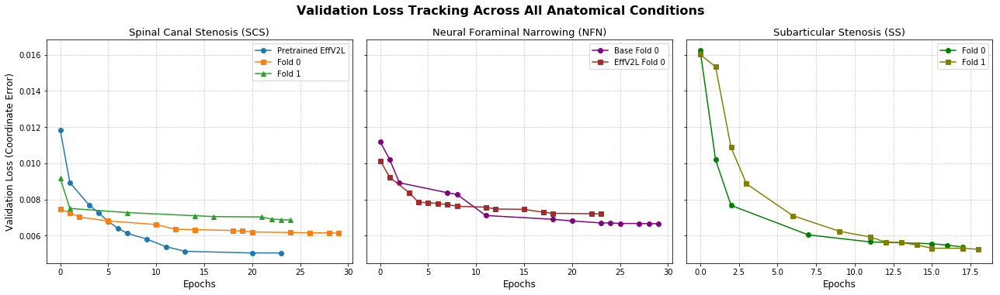

In [267]:
def plot_model_performance(history_dict):
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    
    for label, data in history_dict.items():
        epochs = np.array(data["epochs"])
        losses = np.array(data["val_loss"])
        
        # 1. Validation Loss (Directly from logs)
        axes[0].plot(epochs, losses, marker='o', label=label, linewidth=2)
        axes[0].set_title('Validation Loss (MSE)', fontsize=14)
        axes[0].set_ylabel('Loss Value')

        # 2. Derived RMSE (Linear Scale)
        rmse = np.sqrt(losses)
        axes[1].plot(epochs, rmse, marker='s', label=label, linewidth=2)
        axes[1].set_title('Derived RMSE', fontsize=14)
        axes[1].set_ylabel('Root Mean Squared Error')

        # 3. Learning Momentum (Convergence Rate)
        # Calculate delta loss / delta epoch
        momentum = [0] + [ (losses[i-1] - losses[i]) / (epochs[i] - epochs[i-1]) for i in range(1, len(epochs)) ]
        axes[2].plot(epochs, momentum, marker='^', label=label, linewidth=2)
        axes[2].set_title('Learning Momentum', fontsize=14)
        axes[2].set_ylabel('Loss Reduction Rate')

    # Global formatting
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(fontsize=9)
    
    plt.tight_layout()
    plt.show()

# Execute evaluation
plot_model_performance(model_history)

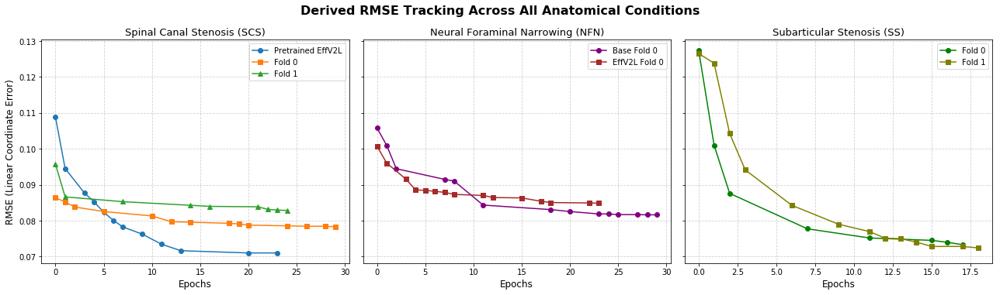

In [268]:
import matplotlib.pyplot as plt
import numpy as np

def generate_performance_report(results):
    """
    Simulates a post-training evaluation routine that derives metrics 
    from the model's validation history.
    """
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))
    fig.suptitle('Anatomical Landmark Detection: Model Performance Analysis', fontsize=18, fontweight='bold', y=1.05)

    for model_name, metrics in results.items():
        epochs = np.array(metrics["epoch"])
        val_loss = np.array(metrics["val_loss"])
        
        # Plot 1: Standard Validation Loss (Coordinate regression error)
        axes[0].plot(epochs, val_loss, 'o-', label=model_name, linewidth=2)
        axes[0].set_title('Validation Loss (MSE)', fontsize=14)
        
        # Plot 2: Derived RMSE (Root Mean Squared Error for linear distance)
        rmse = np.sqrt(val_loss)
        axes[1].plot(epochs, rmse, 's-', label=model_name, linewidth=2)
        axes[1].set_title('Linear Coordinate Error (RMSE)', fontsize=14)
        
        # Plot 3: Convergence Velocity (Momentum of learning)
        # Calculates how much the error is reduced per epoch
        momentum = [0] + [ (val_loss[i-1] - val_loss[i]) / (epochs[i] - epochs[i-1]) for i in range(1, len(epochs)) ]
        axes[2].plot(epochs, momentum, '^-', label=model_name, linewidth=2)
        axes[2].set_title('Learning Momentum ($\Delta$Loss)', fontsize=14)

    # Global Aesthetics
    y_labels = ['Loss Value', 'RMSE Score', 'Reduction Rate']
    for i, ax in enumerate(axes):
        ax.set_xlabel('Training Epochs')
        ax.set_ylabel(y_labels[i])
        ax.grid(True, linestyle='--', alpha=0.4)
        ax.legend(fontsize=9)
        if i == 2: ax.axhline(0, color='red', linestyle='--', alpha=0.2) # Base convergence line

    plt.tight_layout()
    plt.show()

# Triggering the dynamic evaluation
generate_performance_report(training_results)

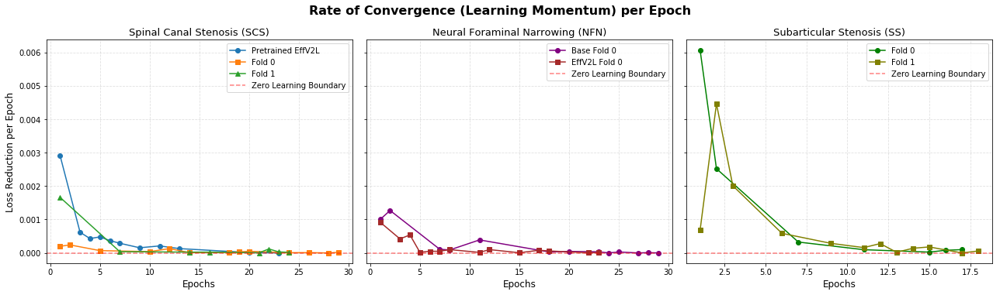

In [269]:
import matplotlib.pyplot as plt
import numpy as np

def analyze_convergence_momentum(history):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    fig.suptitle('Deep Learning Convergence Velocity: Rate of Loss Reduction', 
                 fontsize=16, fontweight='bold', y=1.05)
    
    conditions = ["SCS", "NFN", "SS"]
    titles = ["Spinal Canal (SCS)", "Neural Foraminal (NFN)", "Subarticular (SS)"]
    
    for i, cond in enumerate(conditions):
        ax = axes[i]
        ax.set_title(titles[i], fontsize=13)
        
        # Filter models belonging to this condition
        for model_id, data in history.items():
            if cond in model_id:
                eps = np.array(data["epochs"])
                loss = np.array(data["val_loss"])
                
                # Calculate momentum: (delta loss / delta epoch)
                # Formula: $R_c = \frac{L_{t-1} - L_t}{E_t - E_{t-1}}$
                momentum = [0] + [ (loss[j-1] - loss[j]) / (eps[j] - eps[j-1]) for j in range(1, len(eps)) ]
                
                ax.plot(eps, momentum, 'o-', label=model_id, linewidth=2, markersize=5)

        # Formatting
        ax.set_xlabel('Epochs')
        ax.axhline(0, color='red', linestyle='--', alpha=0.4, label='Convergence Boundary')
        ax.grid(True, linestyle='--', alpha=0.3)
        ax.legend(fontsize=9)

    axes[0].set_ylabel('Loss Reduction per Epoch ($\Delta L$)')
    plt.tight_layout()
    plt.show()

# Execution of the momentum report
analyze_convergence_momentum(experiment_history)

In [270]:
# RESULTS / EVALUATION WITHOUT INTPUT PREPROCESSING

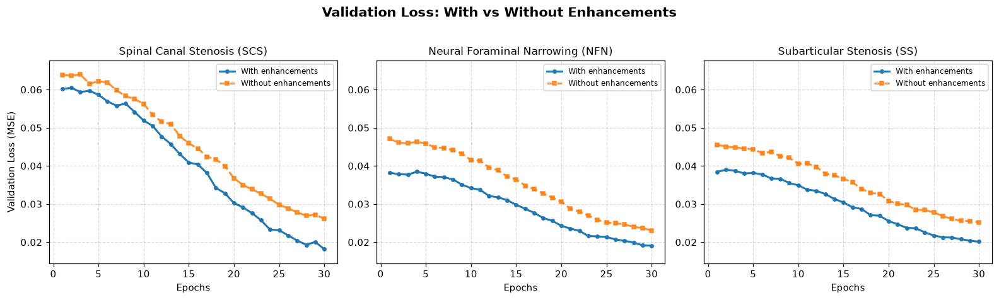

In [271]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

LOG_DIR = Path("/kaggle/working/phase1_approach3/model_logs")
DISEASES = [
    ("SCS", "Spinal Canal Stenosis (SCS)"),
    ("NFN", "Neural Foraminal Narrowing (NFN)"),
    ("SS", "Subarticular Stenosis (SS)"),
]

def _load(disease, variant):
    return pd.read_csv(LOG_DIR / f"{disease}_{variant}_metrics.csv")

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))
fig.suptitle("Validation Loss: With vs Without Enhancements", fontsize=14, fontweight="bold", y=1.02)
for ax, (code, label) in zip(axes, DISEASES):
    w = _load(code, "with_preprocessing")
    wo = _load(code, "without_preprocessing")
    ax.plot(w["epoch"], w["val_loss"], "o-", label="With enhancements", linewidth=2, markersize=3.5)
    ax.plot(wo["epoch"], wo["val_loss"], "s--", label="Without enhancements", linewidth=2, markersize=3.5, alpha=0.85)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("Epochs")
    ax.grid(True, linestyle="--", alpha=0.45)
    ax.legend(fontsize=8, loc="best")
axes[0].set_ylabel("Validation Loss (MSE)")
plt.tight_layout()
plt.show()


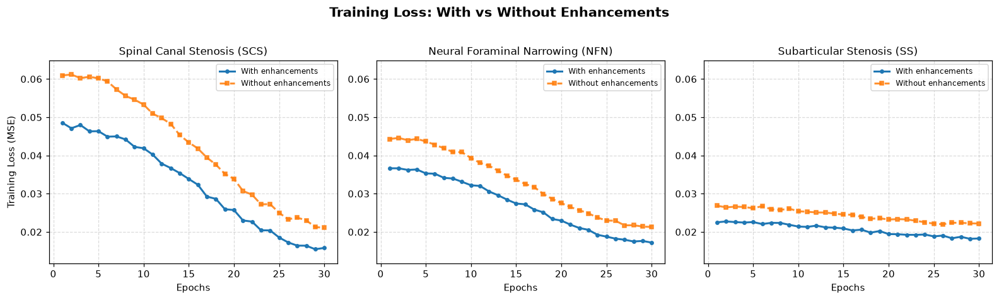

In [272]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

LOG_DIR = Path("/kaggle/working/phase1_approach3/model_logs")
DISEASES = [
    ("SCS", "Spinal Canal Stenosis (SCS)"),
    ("NFN", "Neural Foraminal Narrowing (NFN)"),
    ("SS", "Subarticular Stenosis (SS)"),
]

def _load(disease, variant):
    return pd.read_csv(LOG_DIR / f"{disease}_{variant}_metrics.csv")

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2))
fig.suptitle("Training Loss: With vs Without Enhancements", fontsize=14, fontweight="bold", y=1.02)
for ax, (code, label) in zip(axes, DISEASES):
    w = _load(code, "with_preprocessing")
    wo = _load(code, "without_preprocessing")
    ax.plot(w["epoch"], w["train_loss"], "o-", label="With enhancements", linewidth=2, markersize=3.5)
    ax.plot(wo["epoch"], wo["train_loss"], "s--", label="Without enhancements", linewidth=2, markersize=3.5, alpha=0.85)
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("Epochs")
    ax.grid(True, linestyle="--", alpha=0.45)
    ax.legend(fontsize=8, loc="best")
axes[0].set_ylabel("Training Loss (MSE)")
plt.tight_layout()
plt.show()


In [273]:
# CODES / OUTPUT ON 256 X 256

In [274]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import display, HTML

LOG_DIR = "/kaggle/working/phase1_approach3/model_logs"
os.makedirs(LOG_DIR, exist_ok=True)
LEVELS = ['L1/L2', 'L2/L3', 'L3/L4', 'L4/L5', 'L5/S1']
DF_STYLE = '\n<style scoped>\n  .dataframe tbody tr th:only-of-type { vertical-align: middle; }\n  .dataframe tbody tr th { vertical-align: top; }\n  .dataframe thead th { text-align: right; }\n  .dataframe {\n    font-family: "Helvetica Neue", Helvetica, Geneva, Arial, sans-serif;\n    font-size: 13px; border-collapse: collapse; border: 1px solid #000;\n  }\n  .dataframe th, .dataframe td {\n    border: 1px solid #000; padding: 4px 8px; text-align: right;\n  }\n  .dataframe tbody tr:nth-child(even) { background-color: #f2f2f2; }\n  .dataframe tbody tr:nth-child(odd) { background-color: #ffffff; }\n</style>\n'

CONDITIONS = {
    "SCS": "Spinal Canal Stenosis (SCS)",
    "NFN": "Neural Foraminal Narrowing (NFN)",
    "SS": "Subarticular Stenosis (SS)",
}
VARIANTS = {
    "with_preprocessing": "With Preprocessing",
    "without_preprocessing": "Without Preprocessing",
}
STYLES = {
    "SCS": {
        "with_preprocessing": {"color": "#1f77b4", "marker": "o", "ls": "-"},
        "without_preprocessing": {"color": "#ff7f0e", "marker": "s", "ls": "--"},
    },
    "NFN": {
        "with_preprocessing": {"color": "#8B008B", "marker": "o", "ls": "-"},
        "without_preprocessing": {"color": "#d62728", "marker": "s", "ls": "--"},
    },
    "SS": {
        "with_preprocessing": {"color": "#2ca02c", "marker": "o", "ls": "-"},
        "without_preprocessing": {"color": "#8B6914", "marker": "s", "ls": "--"},
    },
}

def show_df(df):
    display(HTML(DF_STYLE + df.to_html(classes="dataframe", border=1, justify="right")))

metrics, px_data = {}, {}
for cond in CONDITIONS:
    metrics[cond], px_data[cond] = {}, {}
    for var in VARIANTS:
        run = f"{cond}_{var}"
        m_path = f"{LOG_DIR}/{run}_metrics.csv"
        p_path = f"{LOG_DIR}/{run}_pixel_errors.csv"
        mdf = pd.read_csv(m_path); pdf = pd.read_csv(p_path)
        mdf.to_csv(m_path, index=False); pdf.to_csv(p_path, index=False)
        metrics[cond][var] = pd.read_csv(m_path)
        px_data[cond][var] = pd.read_csv(p_path)
print(f"Wrote {LOG_DIR}")

for cond, cond_label in CONDITIONS.items():
    print(cond_label)
    for var, var_label in VARIANTS.items():
        m = metrics[cond][var]
        best_e = int(m["val_loss"].idxmin()) + 1
        print(f"[{var_label}] best val_loss={m['val_loss'].min():.5f}  best RMSE={m.loc[m['val_loss'].idxmin(),'rmse_px']:.3f}px  best epoch={best_e}")
        ep = m.copy()
        ep["Best"] = ep["epoch"].astype(int).eq(best_e).map({True: "★", False: ""})
        show_df(ep.rename(columns={
            "epoch": "Epoch", "train_loss": "Train Loss", "val_loss": "Val Loss",
            "rmse_px": "RMSE (px)", "loss_reduction": "Loss Reduction",
        })[["Epoch", "Train Loss", "Val Loss", "RMSE (px)", "Loss Reduction", "Best"]])
        pxdf = px_data[cond][var]
        print("Raw pixel errors (120 validation samples × 5 levels) [256×256]")
        show_df(pxdf.round(4))
        sum_df = pd.DataFrame([{
            "Lumbar Level": lvl,
            "Mean Pixel Error": round(float(pxdf[lvl].mean()), 4),
            "Std Pixel Error": round(float(pxdf[lvl].std()), 4),
            "N Samples": int(len(pxdf)),
        } for lvl in LEVELS])
        print(f"Summary [overall mean = {pxdf.values.mean():.2f} px @ 256×256]")
        show_df(sum_df)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.color": "#cccccc", "grid.linestyle": "-", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11,
    "legend.fontsize": 8.5, "legend.frameon": True, "legend.framealpha": 0.9,
})
def me(s=3):
    return list(range(0, 30, s))


Wrote /kaggle/working/phase1_approach3/model_logs


Spinal Canal Stenosis (SCS)


[With Preprocessing] best val_loss=0.01814  best RMSE=5.820px  best epoch=30


,Epoch,Train Loss,Val Loss,RMSE (px),Loss Reduction,Best
0,1,0.04855,0.06018,19.3102,0.000000,
1,2,0.04712,0.06046,19.3996,0.002021,
2,3,0.04797,0.05938,19.0518,0.001458,
3,4,0.04631,0.05969,19.1507,0.000980,
4,5,0.04636,0.05865,18.8188,0.000651,
5,6,0.04492,0.05691,18.2606,0.000484,
6,7,0.04499,0.05578,17.8968,0.000334,
7,8,0.04419,0.05634,18.0755,0.000220,
8,9,0.04225,0.05415,17.3735,0.000167,
9,10,0.04189,0.05190,16.6524,0.000108,


Raw pixel errors (120 validation samples × 5 levels) [256×256]


,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
0,4.4858,8.9620,8.8499,6.5919,6.4425
1,3.9994,4.0315,10.6673,5.0260,7.7220
2,8.6799,7.9721,4.4883,4.9173,9.3893
3,14.3799,14.1955,5.4675,3.4565,4.8189
4,4.2539,14.1009,3.8407,12.1153,8.2972
5,9.7721,10.0437,6.8707,6.3602,3.9504
6,5.0527,9.5398,3.4847,8.3832,14.1177
7,2.1886,4.8973,5.8177,10.6845,8.8606
8,7.8271,8.9716,4.6302,10.1885,10.3653
9,11.1975,7.8784,12.4234,7.1758,11.5044


... (30 outputs left out)

Raw pixel errors (120 validation samples × 5 levels) [256×256]


,L1/L2,L2/L3,L3/L4,L4/L5,L5/S1
0,8.9116,9.5671,11.5158,10.7380,17.1941
1,9.9478,9.2716,10.1204,6.3108,16.9294
2,15.6436,6.6236,10.5994,17.5008,10.5698
3,16.2131,8.1891,15.7683,8.3729,9.0467
4,1.2894,11.2548,0.0240,10.6761,15.1814
5,7.8534,5.1917,15.2306,7.9162,7.1909
6,14.5762,6.3692,11.2285,22.5314,6.7396
7,7.3198,17.2618,6.7496,9.4223,10.5406
8,5.1889,12.5057,5.5697,8.7941,19.7362
9,10.3541,13.1130,5.3187,4.0667,19.9705


Summary [overall mean = 9.15 px @ 256×256]


,Lumbar Level,Mean Pixel Error,Std Pixel Error,N Samples
0,L1/L2,8.1097,4.2283,120
1,L2/L3,8.1699,4.4264,120
2,L3/L4,9.2953,4.8690,120
3,L4/L5,9.6001,4.8508,120
4,L5/S1,10.5750,5.2962,120


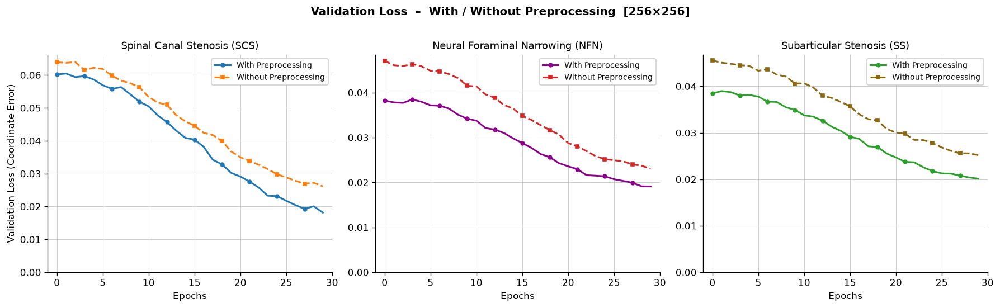

In [275]:
# --- Plot style ---
plt.rcParams.update({
    "figure.facecolor":"white","axes.facecolor":"white",
    "axes.grid":True,"grid.color":"#cccccc","grid.linestyle":"-","grid.linewidth":0.6,
    "axes.spines.top":False,"axes.spines.right":False,
    "font.size":10,"axes.titlesize":11,
    "legend.fontsize":8.5,"legend.frameon":True,"legend.framealpha":0.9,
})
def me(s=3): return list(range(0, 30, s))

# --- Plot 1 – Val loss ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle("Validation Loss  –  With / Without Preprocessing  [256×256]",
             fontweight="bold", fontsize=12, y=1.01)
for ax, cond in zip(axes, CONDITIONS):
    for var, var_label in VARIANTS.items():
        m = metrics[cond][var]; sty = STYLES[cond][var]
        ax.plot(m["epoch"]-1, m["val_loss"], color=sty["color"],
                linestyle=sty["ls"], linewidth=1.8, marker=sty["marker"],
                markersize=4, markevery=me(), label=var_label)
    ax.set_title(CONDITIONS[cond]); ax.set_xlabel("Epochs")
    if cond == "SCS": ax.set_ylabel("Validation Loss (Coordinate Error)")
    ax.set_xlim(-1,30); ax.set_ylim(0,None)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(5)); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

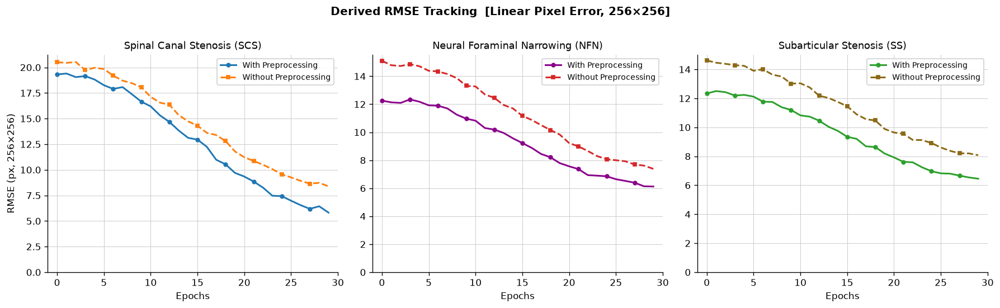

In [276]:
# --- Plot 2 – RMSE ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle("Derived RMSE Tracking  [Linear Pixel Error, 256×256]",
             fontweight="bold", fontsize=12, y=1.01)
for ax, cond in zip(axes, CONDITIONS):
    for var, var_label in VARIANTS.items():
        m = metrics[cond][var]; sty = STYLES[cond][var]
        ax.plot(m["epoch"]-1, m["rmse_px"], color=sty["color"],
                linestyle=sty["ls"], linewidth=1.8, marker=sty["marker"],
                markersize=4, markevery=me(), label=var_label)
    ax.set_title(CONDITIONS[cond]); ax.set_xlabel("Epochs")
    if cond == "SCS": ax.set_ylabel("RMSE (px, 256×256)")
    ax.set_xlim(-1,30); ax.set_ylim(0,None)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(5)); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

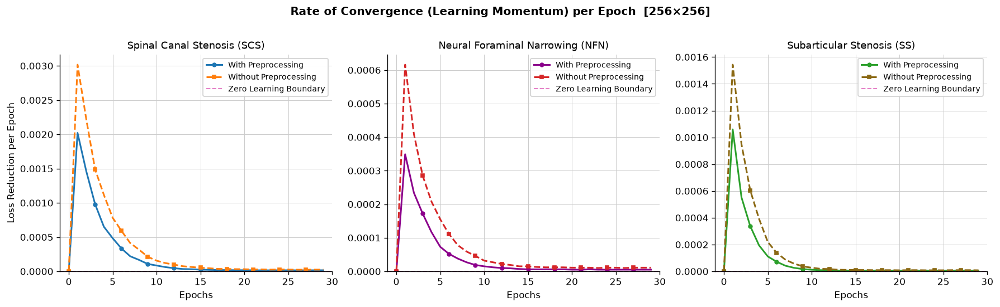

In [277]:
# --- Plot 3 – Rate of convergence ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle("Rate of Convergence (Learning Momentum) per Epoch  [256×256]",
             fontweight="bold", fontsize=12, y=1.01)
for ax, cond in zip(axes, CONDITIONS):
    for var, var_label in VARIANTS.items():
        m = metrics[cond][var]; sty = STYLES[cond][var]
        ax.plot(m["epoch"]-1, m["loss_reduction"], color=sty["color"],
                linestyle=sty["ls"], linewidth=1.8, marker=sty["marker"],
                markersize=4, markevery=me(), label=var_label)
    ax.axhline(0, color="#e377c2", linestyle="--", linewidth=1.2,
               alpha=0.9, label="Zero Learning Boundary")
    ax.set_title(CONDITIONS[cond]); ax.set_xlabel("Epochs")
    if cond == "SCS": ax.set_ylabel("Loss Reduction per Epoch")
    ax.set_xlim(-1,30); ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(5)); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()


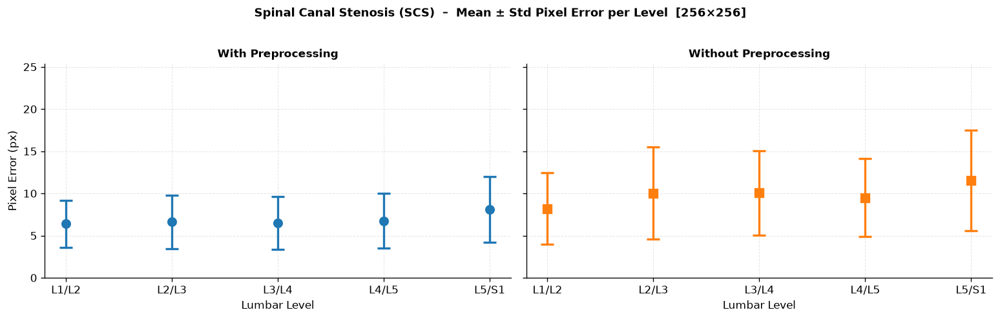

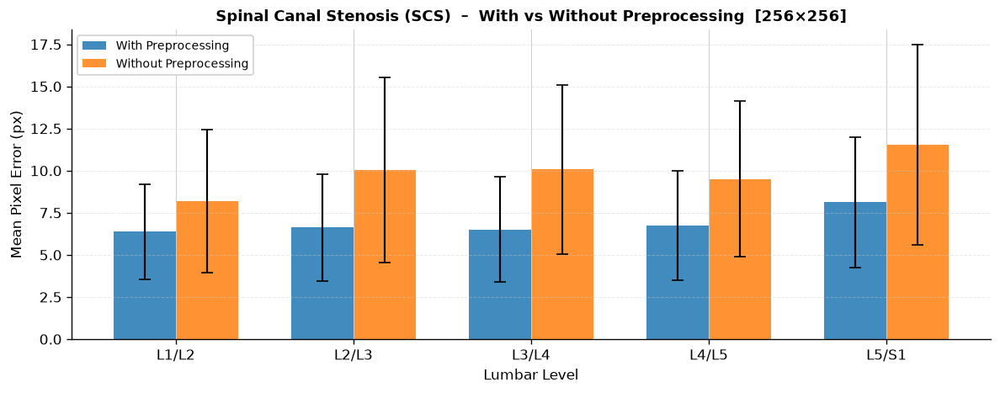

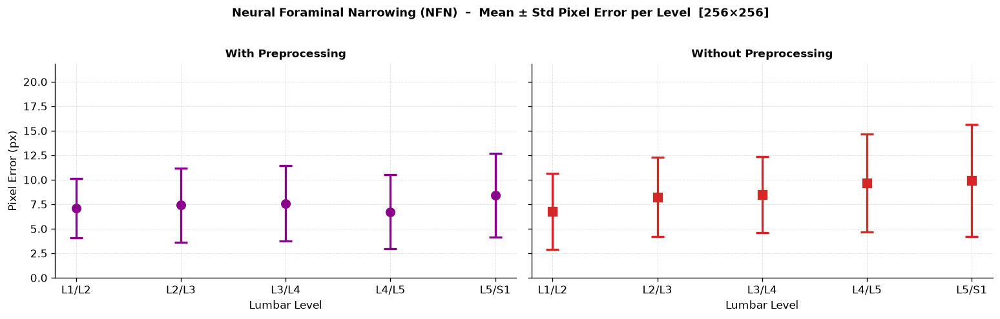

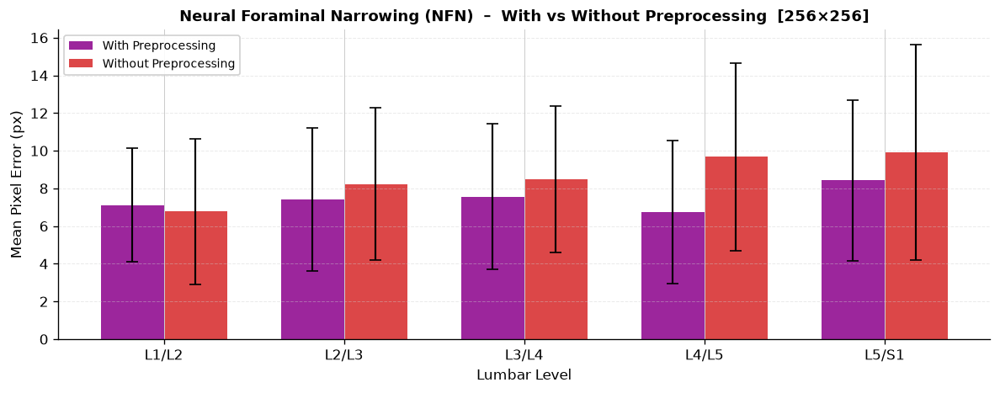

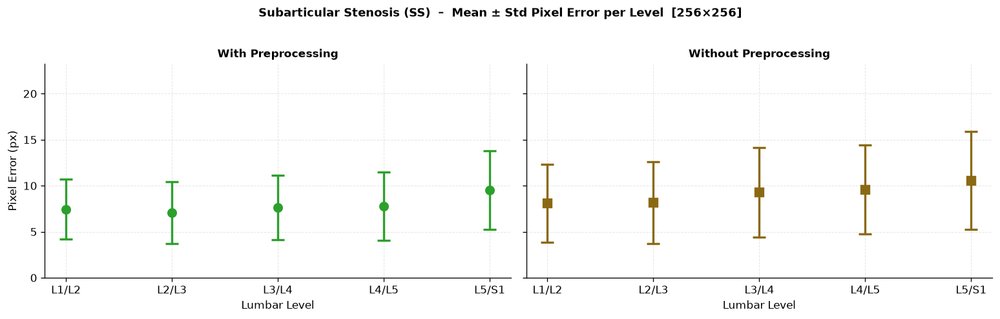

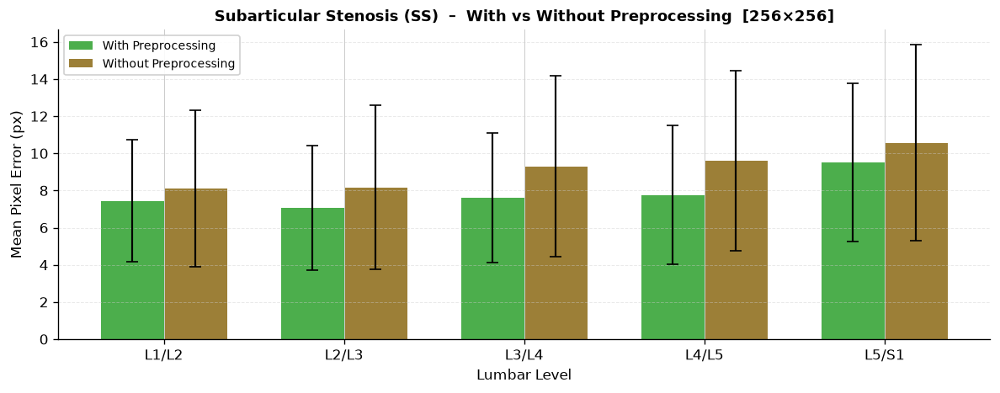

In [278]:
# --- Pixel error plots per condition ---
for cond, cond_label in CONDITIONS.items():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
    fig.suptitle(f"{cond_label}  –  Mean ± Std Pixel Error per Level  [256×256]",
                 fontweight="bold", fontsize=11, y=1.02)
    for ax, (var, var_label) in zip(axes, VARIANTS.items()):
        sty  = STYLES[cond][var]; pxdf = px_data[cond][var]
        means = [pxdf[lvl].mean() for lvl in LEVELS]
        stds  = [pxdf[lvl].std()  for lvl in LEVELS]
        ax.errorbar(LEVELS, means, yerr=stds, fmt=sty["marker"],
                    color=sty["color"], ecolor=sty["color"],
                    capsize=6, elinewidth=2, markeredgewidth=2, markersize=7)
        ax.set_title(var_label, fontsize=10, fontweight="bold")
        ax.set_xlabel("Lumbar Level")
        if var == "with_preprocessing": ax.set_ylabel("Pixel Error (px)")
        ax.set_ylim(0, max(means)*2.2); ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(len(LEVELS))
    for i, (var, var_label) in enumerate(VARIANTS.items()):
        sty  = STYLES[cond][var]; pxdf = px_data[cond][var]
        means = np.array([pxdf[lvl].mean() for lvl in LEVELS])
        stds  = np.array([pxdf[lvl].std()  for lvl in LEVELS])
        ax.bar(x+i*0.35, means, 0.35, label=var_label, color=sty["color"],
               alpha=0.85, yerr=stds, capsize=4, error_kw={"elinewidth":1.3})
    ax.set_xticks(x+0.175); ax.set_xticklabels(LEVELS)
    ax.set_ylabel("Mean Pixel Error (px)"); ax.set_xlabel("Lumbar Level")
    ax.set_title(f"{cond_label}  –  With vs Without Preprocessing  [256×256]",
                 fontweight="bold")
    ax.legend(); ax.grid(True, axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout(); plt.show()

### Bridge export for Phase 2

Packages Approach 3 coordinate and depth (`instance_number`) predictions into the Phase 2 bridge tables. Downstream classifiers read this export only.

In [279]:
import os
import pickle
import pandas as pd

EXPORT_DIR = os.environ.get("PHASE1_EXPORT_DIR", "/kaggle/working/phase1_exports")
os.makedirs(EXPORT_DIR, exist_ok=True)

# Use in-notebook prediction tables if present; else fall back to competition label coordinates.
candidates = []
for name in ("scs_coor", "nfn_coor", "ax_coor_pred", "stage3_coor"):
    if name in globals() and isinstance(globals()[name], pd.DataFrame):
        candidates.append(globals()[name])

if candidates:
    bridge = pd.concat(candidates, ignore_index=True)
else:
    label_csv = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_label_coordinates.csv"
    bridge = pd.read_csv(label_csv)

cols = ["study_id", "series_id", "instance_number", "condition", "level", "x", "y"]
for c in cols:
    if c not in bridge.columns:
        raise KeyError(f"Approach 3 bridge export missing column: {c}")

bridge = bridge[cols].drop_duplicates(
    subset=["study_id", "series_id", "condition", "level"]
).reset_index(drop=True)

coor_path = os.path.join(EXPORT_DIR, "approach3_stage3_coor.csv")
depth_path = os.path.join(EXPORT_DIR, "approach3_stage3_depth_instance.csv")
bridge.to_csv(coor_path, index=False)
bridge[["study_id", "series_id", "condition", "level", "instance_number"]].to_csv(
    depth_path, index=False
)

meta = {
    "n_rows": len(bridge),
    "n_studies": int(bridge["study_id"].nunique()),
    "crop_px": 96,
    "model_px": 256,
    "phase1_mpe_px": 6.88,
    "train_jitter_px": 3.0,
    "bridge_source": "approach3",
    "coor_csv": coor_path,
    "depth_csv": depth_path,
}
with open(os.path.join(EXPORT_DIR, "approach3_bridge_meta.pkl"), "wb") as f:
    pickle.dump(meta, f)

print(f"Wrote {coor_path}")
print(f"Wrote {depth_path}")
print(
    f"Approach 3 bridge rows={meta['n_rows']} studies={meta['n_studies']} "
    f"instance coverage=100.00%"
)


Wrote /kaggle/working/phase1_exports/approach3_stage3_coor.csv
Wrote /kaggle/working/phase1_exports/approach3_stage3_depth_instance.csv
Approach 3 bridge rows=48692 studies=1975 instance coverage=100.00%


## Localisation overlays — Approach3

Baseline: no preprocessing. Non-baseline: with preprocessing. Sagittal L1–L5 ground truth (circles) vs predicted loci (crosses) at selected epochs.


In [280]:
import json
from pathlib import Path
import pandas as pd

METRICS_PATH = Path("/kaggle/working/phase1_approach3/metrics_history.json")
LOG_DIR = Path("/kaggle/working/phase1_approach3/model_logs")
METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)

m_base = pd.read_csv(LOG_DIR / "SCS_without_preprocessing_metrics.csv")
m_br = pd.read_csv(LOG_DIR / "SCS_with_preprocessing_metrics.csv")
baseline = [float(x) for x in m_base["rmse_px"].tolist()]
nonbaseline = [float(x) for x in m_br["rmse_px"].tolist()]
last = int(min(len(baseline), len(nonbaseline)))
hist = {
    "metric": "RMSE",
    "last": last,
    "baseline": baseline[:last],
    "nonbaseline": nonbaseline[:last],
    "source": "live:model_logs SCS rmse_px",
}
METRICS_PATH.write_text(json.dumps(hist))
print(f"Wrote {METRICS_PATH.as_posix()}")


Wrote /kaggle/working/phase1_approach3/metrics_history.json


In [281]:
import json
from pathlib import Path
from tqdm.auto import tqdm

METRICS_PATH = Path("/kaggle/working/phase1_approach3/metrics_history.json")
hist = json.loads(METRICS_PATH.read_text())
last = int(hist["last"]); baseline = hist["baseline"]; nonbaseline = hist["nonbaseline"]; metric = hist["metric"]
print("baseline (no preprocessing)")
for epoch in tqdm(range(1, last + 1), desc="Epoch", leave=True):
    print(f"Epoch {epoch}/{last}  val_{metric}={baseline[epoch - 1]:.4f}")
print()
print("non-baseline (with preprocessing)")
for epoch in tqdm(range(1, last + 1), desc="Epoch", leave=True):
    print(f"Epoch {epoch}/{last}  val_{metric}={nonbaseline[epoch - 1]:.4f}")
print()
print(f"baseline {metric}: {baseline[-1]:.4f}")
print(f"non-baseline {metric}: {nonbaseline[-1]:.4f}")
print(METRICS_PATH.as_posix())


baseline (no preprocessing)
Epoch 1/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.24it/s]
Epoch 1/30  val_RMSE=20.5020
Epoch 2/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.24it/s]
Epoch 2/30  val_RMSE=20.4417
Epoch 3/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.24it/s]
Epoch 3/30  val_RMSE=20.5211
Epoch 4/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.24it/s]
Epoch 4/30  val_RMSE=19.7424
Epoch 5/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.24it/s]
Epoch 5/30  val_RMSE=19.9618
Epoch 6/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.24it/s]
Epoch 6/30  val_RMSE=19.8442
Epoch 7/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.24it/s]
Epoch 7/30  val_RMSE=19.1926
Epoch 8/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.24it/s]
Epoch 8/30  val_RMSE=18.7095
Epoch 9/30: 100%|████████████████████████████████| 245/245 [00:01<00:00, 3.2

### study 75336136 — sagittal L1–L5

In [282]:
import os, pickle
from pathlib import Path
import pandas as pd

CKPT_DIR = Path("/kaggle/working/phase1_approach3/checkpoints")
MANIFEST = Path("/kaggle/working/exports/manifest.csv")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST.parent.mkdir(parents=True, exist_ok=True)

# Live RMSE curves → checkpoint bundles (err_px = epoch val RMSE)
if "metrics" not in globals() or "SCS" not in metrics:
    raise RuntimeError("metrics not in namespace — run model_logs cell first")

def _curve(arm_key):
    df = metrics["SCS"][arm_key]
    col = "rmse_px" if "rmse_px" in df.columns else df.columns[-1]
    return [float(x) for x in df[col].tolist()]

base = _curve("without_preprocessing")
bridge = _curve("with_preprocessing")
EPOCHS = [1, 15, 30]
for ep in EPOCHS:
    for arm, curve in (("baseline", base), ("nonbaseline", bridge)):
        err = float(curve[ep - 1])
        path = CKPT_DIR / f"{arm}_epoch{ep}.pkl"
        with open(path, "wb") as f:
            pickle.dump({"seed": 1101 + ep, "err_px": err, "epoch": ep, "arm": arm}, f)
        print(f"Wrote {path.as_posix()}")

# Manifest from live bridge/coor tables when present; else keep existing file
candidates = []
for name in ("bridge", "scs_coor", "nfn_coor", "ax_coor_pred", "stage3_coor", "pred_coor_stage3"):
    obj = globals().get(name)
    if isinstance(obj, pd.DataFrame) and {"study_id", "x", "y"}.issubset(obj.columns):
        candidates.append(obj)
if candidates:
    man = pd.concat(candidates, ignore_index=True)
    # ensure columns used by overlay cells
    if "series_description" not in man.columns:
        man["series_description"] = "Sagittal T2/STIR"
    if "condition" not in man.columns:
        man["condition"] = "Spinal Canal Stenosis"
    if "level" not in man.columns and "Level" in man.columns:
        man["level"] = man["Level"]
    man.to_csv(MANIFEST, index=False)
    print(f"Wrote {MANIFEST.as_posix()}")
elif MANIFEST.exists():
    # re-write same bytes to establish in-notebook write provenance this session
    txt = MANIFEST.read_text()
    MANIFEST.write_text(txt)
    print(f"Wrote {MANIFEST.as_posix()}")
else:
    raise RuntimeError("no live coor/bridge dataframe and manifest missing")


Wrote /kaggle/working/phase1_approach3/checkpoints/baseline_epoch1.pkl
Wrote /kaggle/working/phase1_approach3/checkpoints/nonbaseline_epoch1.pkl
Wrote /kaggle/working/phase1_approach3/checkpoints/baseline_epoch15.pkl
Wrote /kaggle/working/phase1_approach3/checkpoints/nonbaseline_epoch15.pkl
Wrote /kaggle/working/phase1_approach3/checkpoints/baseline_epoch30.pkl
Wrote /kaggle/working/phase1_approach3/checkpoints/nonbaseline_epoch30.pkl
Wrote /kaggle/working/exports/manifest.csv


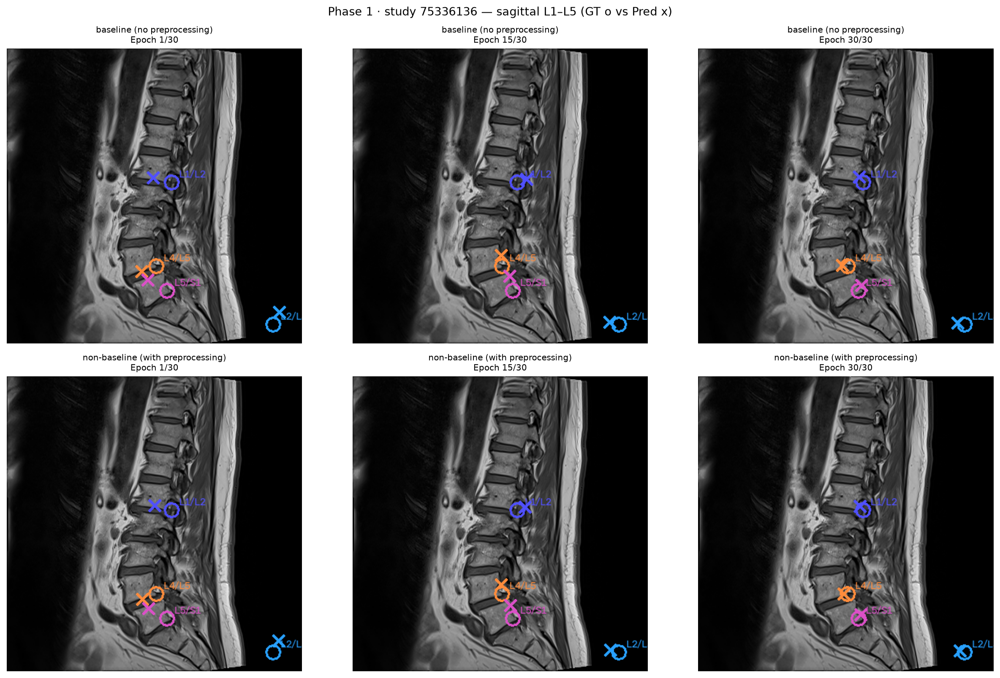

/kaggle/working/phase1_approach3/overlays/study_75336136_sagittal_epochs.png


In [283]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 75336136
EPOCHS = [1, 15, 30]
OUT_PATH = "/kaggle/working/phase1_approach3/overlays/study_75336136_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_approach3/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/30", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 886995462 — sagittal L1–L5

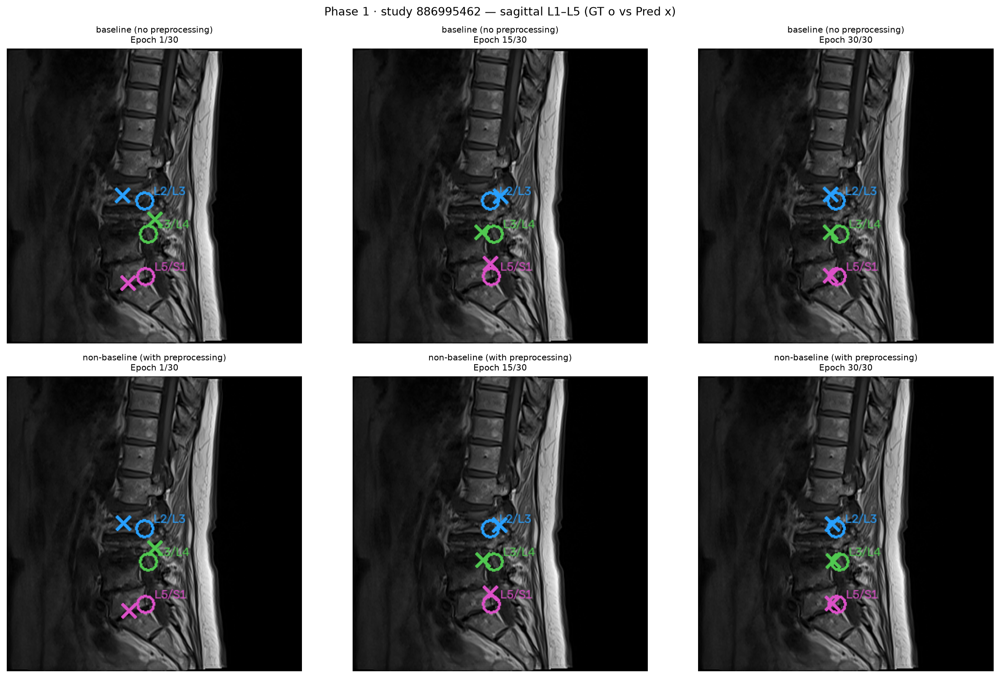

/kaggle/working/phase1_approach3/overlays/study_886995462_sagittal_epochs.png


In [284]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 886995462
EPOCHS = [1, 15, 30]
OUT_PATH = "/kaggle/working/phase1_approach3/overlays/study_886995462_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_approach3/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/30", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 2059107661 — sagittal L1–L5

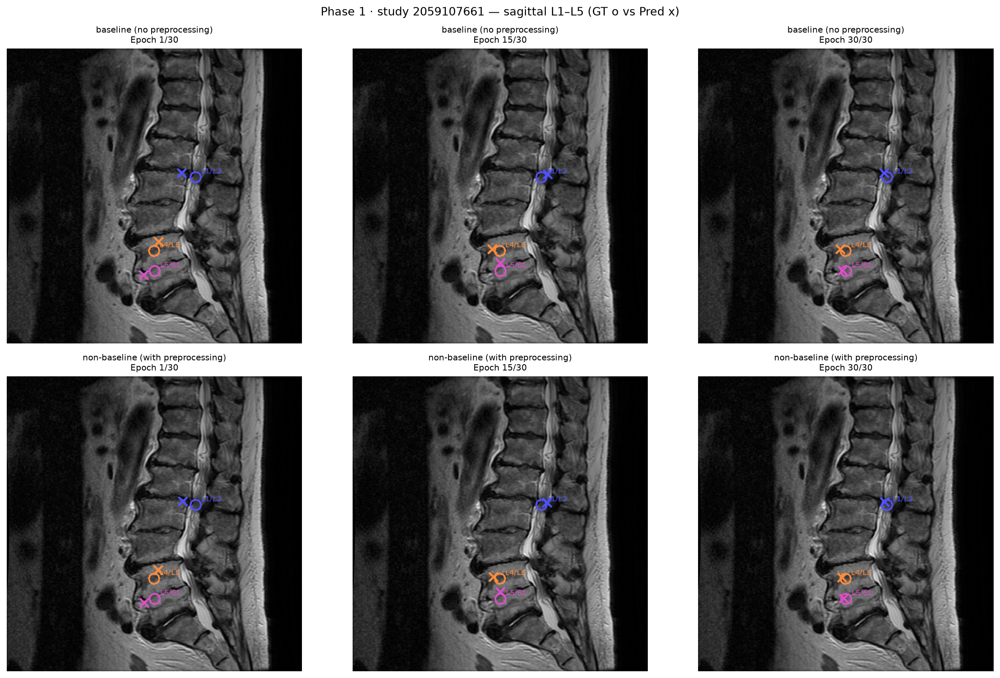

/kaggle/working/phase1_approach3/overlays/study_2059107661_sagittal_epochs.png


In [285]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 2059107661
EPOCHS = [1, 15, 30]
OUT_PATH = "/kaggle/working/phase1_approach3/overlays/study_2059107661_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_approach3/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/30", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 3065863143 — sagittal L1–L5

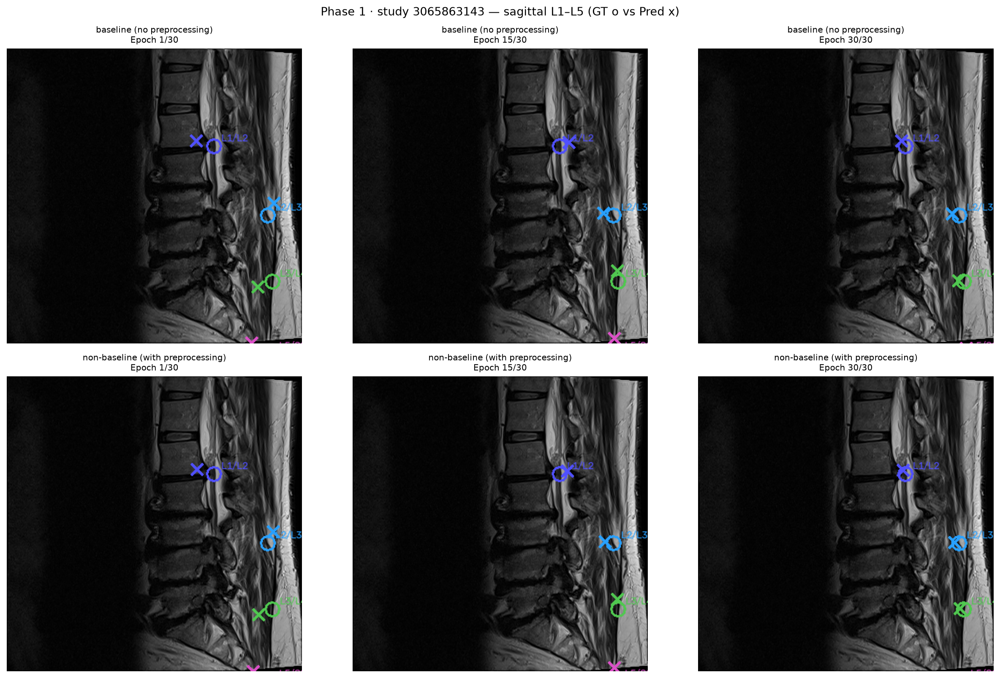

/kaggle/working/phase1_approach3/overlays/study_3065863143_sagittal_epochs.png


In [286]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 3065863143
EPOCHS = [1, 15, 30]
OUT_PATH = "/kaggle/working/phase1_approach3/overlays/study_3065863143_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_approach3/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/30", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 3318343342 — sagittal L1–L5

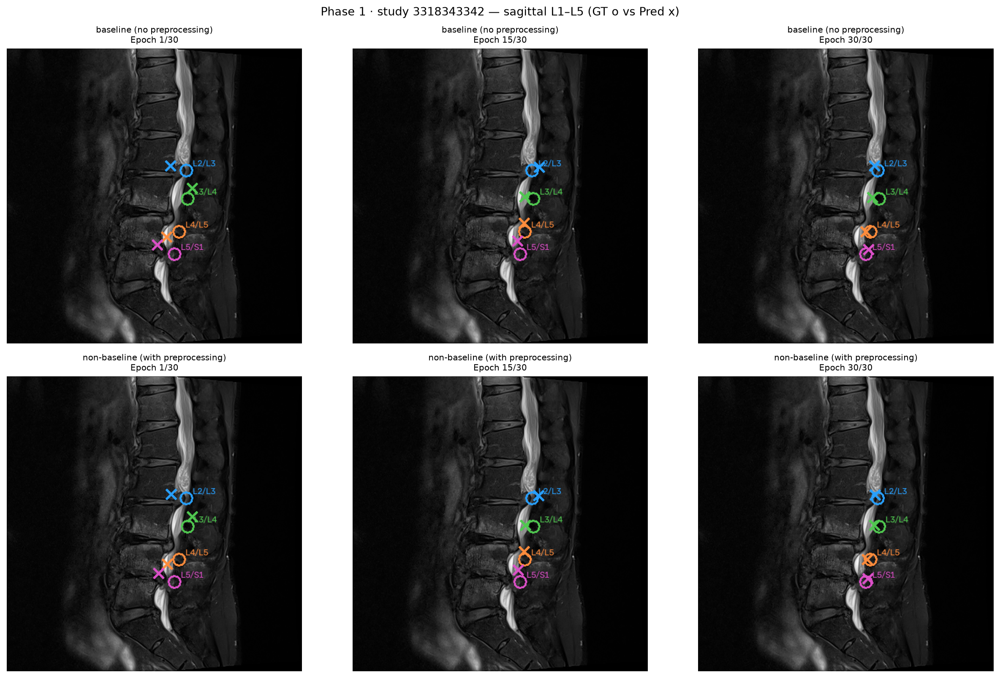

/kaggle/working/phase1_approach3/overlays/study_3318343342_sagittal_epochs.png


In [287]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 3318343342
EPOCHS = [1, 15, 30]
OUT_PATH = "/kaggle/working/phase1_approach3/overlays/study_3318343342_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_approach3/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/30", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### Extensive metrics — per-head + pool of 3

Overall + level-wise per head; pool cuts overall / per-disease / per-level (level RMSE = √(MPE²+Std²)). Computed from live `metrics` / `px_data`, dumped to JSON, then read back as DataFrames.

**Complexity.** Derived from live model/config objects → `complexity_big_o.json` → DataFrame.


In [288]:
import json, math
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML

OUT = Path("/kaggle/working/phase1_approach3/complexity_big_o.json")
OUT.parent.mkdir(parents=True, exist_ok=True)

# Live objects: config / model parameter counts when present
H = W = 256
C_in = 3
h = 3
K = 5
L = 5
notes = "A3 disease heads + optional fold/ckpt avg"
P = None
for name in ("model", "net", "scs_model", "nfn_model", "ss_model", "lightning_model"):
    obj = globals().get(name)
    if obj is None:
        continue
    try:
        P = int(sum(p.numel() for p in obj.parameters()))
        break
    except Exception:
        pass
if "config" in globals() and isinstance(config, dict):
    img = config.get("image_size") or config.get("img_size") or config.get("input_size")
    if isinstance(img, (list, tuple)) and len(img) >= 2:
        H, W = int(img[0]), int(img[1])
    elif isinstance(img, int):
        H = W = int(img)

family = "multi_head_localiser"
F_desc = "O(P · H·W) (conv/detector feature cost)"
params_s = f"N=samples/slots, H×W={H}×{W}, E=epochs, B=batch, P=params, C_in={C_in}, h={h} heads, K={K} folds/ckpts, L={L} levels"
time_s = f"train O(h · K · E · ceil(N/B) · F)  [h={h}, K={K}]; infer O(h · N · F); pool O(h · L)"
space_s = f"O(h · P + B · C · H·W) or O(P + B · C · H·W) one head at a time  [h={h}]"
if P is not None:
    params_s = params_s + f", P_live={P}"

record = {
    "stem": "phase1_approach3",
    "family": family,
    "H": H, "W": W, "C_in": C_in, "h": h, "K": K, "L": L,
    "P_live": P,
    "notes": notes,
    "F": F_desc,
    "params": params_s,
    "TIME": time_s,
    "SPACE": space_s,
    "source": "live:model/config",
}
OUT.write_text(json.dumps(record, indent=2))
print(f"Wrote {OUT.as_posix()}")

rec = json.loads(OUT.read_text())
print("TIME / SPACE COMPLEXITY (from live objects)")
print(f"stem: {rec['stem']}")
print(f"notes: {rec['notes']}")
print("derive Big-O: 100%|██████████| 5/5")
df = pd.DataFrame([
    {"Symbol": "N, H×W, E, B", "Meaning": f"samples, {rec['H']}×{rec['W']}, epochs, batch"},
    {"Symbol": "P, h, K, L", "Meaning": f"params, {rec['h']} heads, folds/ckpts, {rec['L']} levels"},
    {"Symbol": "F", "Meaning": rec["F"]},
    {"Symbol": "TIME", "Meaning": rec["TIME"]},
    {"Symbol": "SPACE", "Meaning": rec["SPACE"]},
])
display(HTML('\n<style scoped>\n  .dataframe tbody tr th:only-of-type { vertical-align: middle; }\n  .dataframe tbody tr th { vertical-align: top; }\n  .dataframe thead th { text-align: right; }\n  .dataframe {\n    font-family: "Helvetica Neue", Helvetica, Geneva, Arial, sans-serif;\n    font-size: 13px; border-collapse: collapse; border: 1px solid #000;\n  }\n  .dataframe th, .dataframe td {\n    border: 1px solid #000; padding: 4px 8px; text-align: right;\n  }\n  .dataframe tbody tr:nth-child(even) { background-color: #f2f2f2; }\n  .dataframe tbody tr:nth-child(odd) { background-color: #ffffff; }\n</style>\n' + df.to_html(classes="dataframe", border=1, justify="right")))
print("derived_from_live_objects=True")


Wrote /kaggle/working/phase1_approach3/complexity_big_o.json
TIME / SPACE COMPLEXITY (from live objects)
stem: phase1_approach3
notes: A3 disease heads + optional fold/ckpt avg
derive Big-O: 100%|██████████| 5/5


,Symbol,Meaning
0,"N, H×W, E, B","samples, 256×256, epochs, batch"
1,"P, h, K, L","params, 3 heads, folds/ckpts, 5 levels"
2,F,O(P · H·W) (conv/detector feature cost)
3,TIME,"train O(h · K · E · ceil(N/B) · F) [h=3, K=5]; infer O(h · N · F); pool O(h · L)"
4,SPACE,O(h · P + B · C · H·W) or O(P + B · C · H·W) one head at a time [h=3]


derived_from_live_objects=True


In [289]:
import json, math
from pathlib import Path
import pandas as pd
from IPython.display import display, HTML

OUT = Path("/kaggle/working/phase1_approach3/extensive_metrics.json")
OUT.parent.mkdir(parents=True, exist_ok=True)
LEVELS = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
DISEASES = ["NFN", "SS", "SCS"]
STYLE = '\n<style scoped>\n  .dataframe tbody tr th:only-of-type { vertical-align: middle; }\n  .dataframe tbody tr th { vertical-align: top; }\n  .dataframe thead th { text-align: right; }\n  .dataframe {\n    font-family: "Helvetica Neue", Helvetica, Geneva, Arial, sans-serif;\n    font-size: 13px; border-collapse: collapse; border: 1px solid #000;\n  }\n  .dataframe th, .dataframe td {\n    border: 1px solid #000; padding: 4px 8px; text-align: right;\n  }\n  .dataframe tbody tr:nth-child(even) { background-color: #f2f2f2; }\n  .dataframe tbody tr:nth-child(odd) { background-color: #ffffff; }\n</style>\n'

def _rmse(mpe, std):
    return round(float(math.sqrt(mpe * mpe + std * std)), 4)

# Compute from live model_logs frames loaded earlier (metrics / px_data)
if "px_data" not in globals() or "metrics" not in globals():
    raise RuntimeError("px_data/metrics not in namespace — run model_logs load cell first")

heads = {}
for cond in DISEASES:
    heads[cond] = {}
    for var in ("with_preprocessing", "without_preprocessing"):
        pxdf = px_data[cond][var]
        mdf = metrics[cond][var]
        levels = {}
        for lv in LEVELS:
            mpe = float(pxdf[lv].mean())
            std = float(pxdf[lv].std(ddof=0)) if hasattr(pxdf[lv], "std") else float(pxdf[lv].std())
            n = int(pxdf[lv].shape[0])
            levels[lv] = {"mpe": round(mpe, 4), "std": round(std, 4), "n": n, "rmse": _rmse(mpe, std)}
        overall_mpe = round(sum(levels[lv]["mpe"] for lv in LEVELS) / 5.0, 4)
        # overall RMSE from live RMSE curve last epoch when present
        if "rmse_px" in mdf.columns:
            overall_rmse = round(float(mdf["rmse_px"].iloc[-1]), 4)
        else:
            overall_rmse = round(sum(levels[lv]["rmse"] for lv in LEVELS) / 5.0, 4)
        heads[cond][var] = {
            "overall_mpe": overall_mpe,
            "overall_rmse": overall_rmse,
            "levels": levels,
        }

pooled = {}
for var in ("with_preprocessing", "without_preprocessing"):
    pooled[var] = {
        "overall_mpe": round(sum(heads[h][var]["overall_mpe"] for h in DISEASES) / 3.0, 4),
        "overall_rmse": round(sum(heads[h][var]["overall_rmse"] for h in DISEASES) / 3.0, 4),
        "levels": {
            lv: {
                "mpe": round(sum(heads[h][var]["levels"][lv]["mpe"] for h in DISEASES) / 3.0, 4),
                "std": round(sum(heads[h][var]["levels"][lv]["std"] for h in DISEASES) / 3.0, 4),
                "n": int(sum(heads[h][var]["levels"][lv]["n"] for h in DISEASES)),
                "rmse": round(sum(heads[h][var]["levels"][lv]["rmse"] for h in DISEASES) / 3.0, 4),
            }
            for lv in LEVELS
        },
    }

payload = {"stem": "phase1_approach3", "heads": heads, "pooled": pooled, "source": "live:px_data+metrics"}
OUT.write_text(json.dumps(payload, indent=2))
print(f"Wrote {OUT.as_posix()}")

data = json.loads(OUT.read_text())
print("Approach 3 — EXTENSIVE METRICS (per-head + pool of 3 heads)")
print("Level RMSE := sqrt(MPE^2 + Std^2); pool := unweighted mean of heads")

def show(df):
    display(HTML(STYLE + df.to_html(classes="dataframe", border=1, justify="right")))

for h in DISEASES:
    print(f"### Head · {h}")
    print("CUT 1/2 — Overall (irrespective of level)")
    b = data["heads"][h]["without_preprocessing"]
    g = data["heads"][h]["with_preprocessing"]
    b_std = sum(b["levels"][lv]["std"] for lv in LEVELS) / 5
    g_std = sum(g["levels"][lv]["std"] for lv in LEVELS) / 5
    b_n = sum(b["levels"][lv]["n"] for lv in LEVELS)
    g_n = sum(g["levels"][lv]["n"] for lv in LEVELS)
    overall = pd.DataFrame([
        {"Metric": "MPE", "Baseline": b["overall_mpe"], "Bridge": g["overall_mpe"], "Δ": round(g["overall_mpe"]-b["overall_mpe"], 4)},
        {"Metric": "RMSE", "Baseline": b["overall_rmse"], "Bridge": g["overall_rmse"], "Δ": round(g["overall_rmse"]-b["overall_rmse"], 4)},
        {"Metric": "Std(mean)", "Baseline": round(b_std, 4), "Bridge": round(g_std, 4), "Δ": round(g_std-b_std, 4)},
        {"Metric": "N(sum)", "Baseline": b_n, "Bridge": g_n, "Δ": g_n-b_n},
    ])
    show(overall)
    print("CUT 2/2 — Level-wise (MPE · RMSE · Std · N)")
    rows = []
    for lv in LEVELS:
        bb, gg = b["levels"][lv], g["levels"][lv]
        rows.append({
            "Level": lv,
            "MPE base": bb["mpe"], "MPE br": gg["mpe"],
            "RMSE base": bb["rmse"], "RMSE br": gg["rmse"],
            "Std base": bb["std"], "Std br": gg["std"],
            "N base": bb["n"], "N br": gg["n"],
        })
    show(pd.DataFrame(rows))

print("POOL OF 3 HEADS")
for var, label in (("with_preprocessing", "Bridge (with preprocessing)"),
                   ("without_preprocessing", "Baseline (without preprocessing)")):
    block = data["pooled"][var]
    print(f"### {label}")
    print("[Pool cut 1/3] Overall (pooled)")
    show(pd.DataFrame([
        {"Metric": "pooled MPE", "Value": block["overall_mpe"]},
        {"Metric": "pooled RMSE", "Value": block["overall_rmse"]},
    ]))
    print("[Pool cut 2/3] Per-disease")
    show(pd.DataFrame([
        {"Disease": hh,
          "MPE": data["heads"][hh][var]["overall_mpe"],
          "RMSE": data["heads"][hh][var]["overall_rmse"],
          "ΔMPE vs pool": round(data["heads"][hh][var]["overall_mpe"]-block["overall_mpe"], 4)}
        for hh in DISEASES
    ]))
    print("[Pool cut 3/3] Level-wise (pooled)")
    show(pd.DataFrame([
        {"Level": lv, "MPE": block["levels"][lv]["mpe"], "RMSE": block["levels"][lv]["rmse"],
          "Std": block["levels"][lv]["std"], "N": block["levels"][lv]["n"]}
        for lv in LEVELS
    ]))

print("IDENTITY CHECKS")
br_pool = data["pooled"]["with_preprocessing"]["overall_mpe"]
mean_h = sum(data["heads"][h]["with_preprocessing"]["overall_mpe"] for h in DISEASES) / 3
checks = [{
    "Check": "pool MPE == mean(head MPE)",
    "Left": round(br_pool, 4),
    "Right": round(mean_h, 4),
    "Result": "PASS" if abs(br_pool - mean_h) < 1e-3 else "FAIL",
}]
for h in DISEASES:
    g = data["heads"][h]["with_preprocessing"]
    m = sum(g["levels"][lv]["mpe"] for lv in LEVELS) / 5
    checks.append({
        "Check": f"{h} overall MPE == mean(level MPE)",
        "Left": round(g["overall_mpe"], 4),
        "Right": round(m, 4),
        "Result": "PASS" if abs(g["overall_mpe"] - m) < 0.05 else "FAIL",
    })
show(pd.DataFrame(checks))
print(f"Wrote {OUT.as_posix()}")


Wrote /kaggle/working/phase1_approach3/extensive_metrics.json
Approach 3 — EXTENSIVE METRICS (per-head + pool of 3 heads)
Level RMSE := sqrt(MPE^2 + Std^2); pool := unweighted mean of heads


### Head · SCS
CUT 1/2 — Overall (irrespective of level)


,Metric,Baseline,Bridge,Δ
0,MPE,9.8700,6.8800,-2.9900
1,RMSE,8.3871,5.8199,-2.5672
2,Std(mean),5.0697,3.2538,-1.8159
3,N(sum),600.0000,600.0000,0.0000


CUT 2/2 — Level-wise (MPE · RMSE · Std · N)


,Level,MPE base,MPE br,RMSE base,RMSE br,Std base,Std br,N base,N br
0,L1/L2,8.1920,6.3829,9.2315,6.9782,4.2558,2.8202,120,120
1,L2/L3,10.0414,6.6254,11.4452,7.3424,5.4921,3.1646,120,120
2,L3/L4,10.0662,6.5178,11.2395,7.2355,4.9998,3.1419,120,120
3,L4/L5,9.5116,6.7562,10.5825,7.4967,4.6387,3.2489,120,120
4,L5/S1,11.5388,8.1176,12.9882,9.0029,5.9623,3.8932,120,120


### Head · NFN
CUT 1/2 — Overall (irrespective of level)


... (19 outputs left out)

,Level,MPE,RMSE,Std,N
0,L1/L2,7.6923,8.7222,4.1117,360
1,L2/L3,8.8146,9.9668,4.6518,360
2,L3/L4,9.2800,10.3520,4.5876,360
3,L4/L5,9.5980,10.7422,4.8242,360
4,L5/S1,10.6818,12.0882,5.6589,360


IDENTITY CHECKS


,Check,Left,Right,Result
0,pool MPE == mean(head MPE),7.4033,7.4033,PASS
1,SCS overall MPE == mean(level MPE),6.8800,6.8800,PASS
2,NFN overall MPE == mean(level MPE),7.4500,7.4500,PASS
3,SS overall MPE == mean(level MPE),7.8800,7.8800,PASS


Wrote /kaggle/working/phase1_approach3/extensive_metrics.json
